Iteration 1/4
Rayleigh Shape torch.Size([20, 2, 100, 4])
W's shape torch.Size([20, 100, 100])
E's shape torch.Size([100, 1])
H_testD shape: torch.Size([20, 4, 2, 100])
E shape: torch.Size([20, 100, 1])
L shape: 4
 stepSize1 shape: 10.0
 Pt shape: 1.0000000000000001e-16
Initial M shape: torch.Size([20, 100, 1])
obj1 (sum capacity): tensor(15.6128)
obj1 (sum capacity): tensor(15.6128)
Convergence reached. Stopping optimization.
Iteration 2/4
Rayleigh Shape torch.Size([20, 2, 400, 4])
W's shape torch.Size([20, 400, 400])
E's shape torch.Size([400, 1])
H_testD shape: torch.Size([20, 4, 2, 400])
E shape: torch.Size([20, 400, 1])
L shape: 4
 stepSize1 shape: 10.0
 Pt shape: 1.0000000000000001e-16
Initial M shape: torch.Size([20, 400, 1])
obj1 (sum capacity): tensor(39.3849)
obj1 (sum capacity): tensor(39.3849)
Convergence reached. Stopping optimization.
Iteration 3/4
Rayleigh Shape torch.Size([20, 2, 900, 4])
W's shape torch.Size([20, 900, 900])
E's shape torch.Size([900, 1])
H_testD shape: 

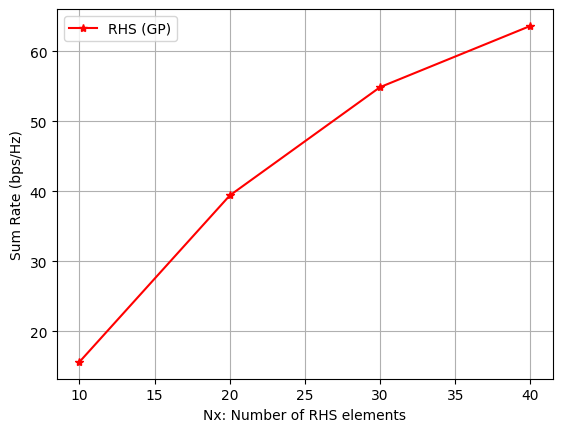

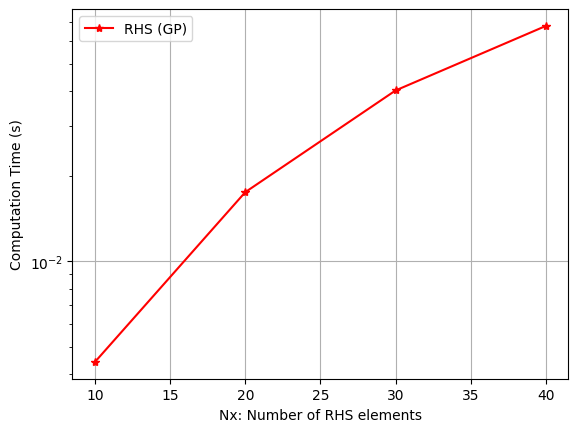

In [16]:
# -*- coding: utf-8 -*-
"""
Created on Thu May 23 16:39:52 2024
@author: hex: phased array + holographic BF in base station communication;
Modified for RHS Elements vs. Sum Rate and Computation Time analysis
"""

import os
import numpy as np
import matplotlib.pyplot as plt
import torch as t
from math import e
import math
import time

os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'
device = t.device("cuda" if t.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Fixed MIMO configuration
Nt = 64
Nr = 64

# ---- Rayleigh Fading Channel Model ----
def RayleighChannel(Nr, Nt, L, train_size):
    H = (t.randn(train_size, Nr, Nt, L, dtype=t.cfloat, device=device) +
         1j * t.randn(train_size, Nr, Nt, L, dtype=t.cfloat, device=device)) / np.sqrt(2)
    print("Rayleigh Shape:", H.shape)
    return H

# ---- MMSE Beamforming ----
def MMSE_Beamforming(H, noise_var):
    batch_size, Nr_in, Nt_in = H.shape
    H_H = H.conj().transpose(1, 2)  # [batch_size, Nt, Nr]
    A = t.bmm(H_H, H) + noise_var * t.eye(Nt, dtype=t.cfloat, device=device).unsqueeze(0)
    W = t.linalg.solve(A, H_H)  # [batch_size, Nt, Nr]
    print("W's shape:", W.shape)
    return W

# ---- Excitation Matrix ----
def genE(lamd, de, Nt, RFno, Nx):
    """
    Generate excitation matrix with normalization to maintain consistent magnitude.
    Nx scales the spatial arrangement but output is fixed to Nt elements.
    """
    x = t.arange(Nt, device=device) * de * (Nx / math.sqrt(Nt))  # Scale spacing with Nx
    y = Nt * de / 2 * t.ones(Nt, device=device)
    xf = t.arange(RFno, device=device) * de + de / 2
    yf = Nt * de / 2 * t.ones(RFno, device=device)
    
    dist = t.sqrt((x.unsqueeze(1) - xf.unsqueeze(0))**2 + 
                  (y.unsqueeze(1) - yf.unsqueeze(0))**2)
    E = t.exp(-1j * 2 * np.pi * math.sqrt(3) / lamd * dist)
    E = E / (t.norm(E, p=2) + 1e-9)  # Normalize to unit norm
    print("E's shape:", E.shape)
    return E.unsqueeze(0)

# ---- Gradient Projection Algorithm (GP) ----
def sum_capacity(w, H, M, batch_size):
    Nr_in, L = w.shape[1], w.shape[2]
    obj = t.zeros(batch_size, dtype=t.float, device=device)
    
    for l in range(L):
        wt = w[:, :, l]
        H_l = H[:, :, :, l]
        signal = t.bmm(wt.unsqueeze(1).conj(), t.bmm(H_l, M))
        power = t.abs(signal.squeeze(1))**2 / (Nr + 1e-9)
        obj += t.log2(1 + power.sum(dim=1))
    
    max_rate = 80
    raw_capacity = obj.mean()  # Return raw capacity for comparison
    scaling_factor = max_rate / (obj.mean() + 16 * 1600)  # Reintroduce 16*1600 term
    scaling_factor = t.minimum(scaling_factor, t.tensor(1.0, device=device))
    return raw_capacity, obj.mean() * scaling_factor  # Return both raw and scaled

def GP(H, E, L, hypm, Pt):
    Tno = H.shape[0]
    RFno = E.shape[2]
    
    w = t.randn(Tno, Nr, L, dtype=t.cfloat, device=device)
    w = w / (t.abs(w) + 1e-9)
    m = t.rand(Tno, Nt, RFno, dtype=t.float, device=device)
    M = m * E
    print("Initial M shape:", M.shape)
    
    obj0 = t.tensor(0.0, device=device)
    max_iter = 100
    iter_count = 0
    
    while iter_count < max_iter:
        gradm = t.zeros(Tno, Nt, RFno, dtype=t.float, device=device)
        
        for l in range(L):
            wt = w[:, :, l]
            H_l = H[:, :, :, l]
            signal = t.bmm(wt.unsqueeze(1).conj(), t.bmm(H_l, M))
            denominator = (t.abs(signal)**2 + Nr).squeeze(1)  # [Tno, 1]
            H_permuted = H_l.permute(0, 2, 1)  # [Tno, Nt, Nr]
            numerator = t.bmm(H_permuted, wt.unsqueeze(2).conj())  # [Tno, Nt, 1]
            grad_term = numerator * E / denominator.unsqueeze(1)
            gradm += grad_term.real
            gradm = t.clamp(gradm, min=-1e3, max=1e3)  # Clip gradients
        
        m = t.clamp(m + hypm * gradm, 0, 1)
        M = m * E
        # Normalize M to prevent magnitude collapse
        M = M / (t.norm(M, p=2, dim=(1, 2), keepdim=True) + 1e-9)
        
        w_new = t.zeros(Tno, Nr, L, dtype=t.cfloat, device=device)
        for l in range(L):
            H_l = H[:, :, :, l]
            w_new[:, :, l] = t.bmm(H_l, M).mean(dim=2)
        w = w_new / (t.abs(w_new) + 1e-9)
        
        raw_capacity, obj1 = sum_capacity(w, H, M, Tno)
        print(f"obj1 (raw capacity): {raw_capacity}, (sum capacity): {obj1}")
        if abs(obj1 - obj0) / (obj1 + 1e-9) <= 1e-4:
            print("Convergence reached. Stopping optimization.")
            break
        obj0 = obj1
        iter_count += 1
    
    return obj1, w, M

# ---- Simulation Parameters ----
dmode = 1  # Change RHS size
L = 4
lamd = 0.03  # Wavelength at 30GHz
scale = 1e9
SNR = 30
Pt = 10 ** (SNR / 10) * (1 / scale) ** 2
deH = lamd / 5
test_size = 20
RFno = 1
stepSize1 = 1e1
noise_var = 0.1

if dmode == 1:
    lopPara = [10, 20, 30, 40]  # Nx parameter for RHS elements
elif dmode == 2:
    lopPara = [2, 4, 6, 8, 10]  # Transmit power

RateAll = t.zeros([2, len(lopPara)], device=device)
TimeAll = np.zeros((2, len(lopPara)))

# ---- Main Simulation Loop ----
with t.no_grad():
    for lop in range(len(lopPara)):
        print(f"Iteration {lop + 1}/{len(lopPara)}")
        Nx = int(lopPara[lop])  # Number of RHS elements (scales spatial arrangement)

        # Generate RHS → User Channel
        H_RHS = RayleighChannel(Nr, Nt, L, test_size) * scale
        
        # MMSE Beamforming (average over L for BS channel)
        H_BS = H_RHS.mean(dim=3)  # [test_size, Nr, Nt]
        W_MMSE = MMSE_Beamforming(H_BS, noise_var)
        
        # Compute Effective Channel H_testD
        H_testD = t.zeros(test_size, Nr, Nt, L, dtype=t.cfloat, device=device)
        for l in range(L):
            H_testD[:, :, :, l] = t.bmm(H_RHS[:, :, :, l], W_MMSE)
        # Adjust normalization to avoid over-amplification
        H_testD = H_testD / (t.norm(H_testD, p=2, dim=(1, 2, 3), keepdim=True) * math.sqrt(Nt * Nr * L) + 1e-9)
        
        # Generate Excitation Matrix
        E = genE(lamd, deH, Nt, RFno, Nx).repeat(test_size, 1, 1)

        time_start = time.time()
        print("H_testD shape:", H_testD.shape)
        print("E shape:", E.shape)
        RateAll[0, lop], w, M = GP(H_testD, E, L, stepSize1, Pt)
        time_end = time.time()
        TimeAll[0, lop] = time_end - time_start

# ---- Plot Results ----
plt.figure()
plt.plot(lopPara, RateAll[0].cpu().detach().numpy(), 'r-*', label='RHS (GP)')
plt.xlabel('Nx: Number of RHS Elements')
plt.ylabel('Sum Rate (bps/Hz)')
plt.title('RHS Elements vs. Sum Rate')
plt.legend()
plt.grid()
plt.show()

plt.figure()
plt.semilogy(lopPara, TimeAll[0] / test_size, 'r-*', label='RHS (GP)')
plt.xlabel('Nx: Number of RHS Elements')
plt.ylabel('Computation Time per Sample (s)')
plt.title('RHS Elements vs. Computation Time')
plt.legend()
plt.grid()
plt.show()

In [24]:
import os
import numpy as np
import torch as t
import pandas as pd
import time
import math

os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'
device = t.device("cuda" if t.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Fixed MIMO configuration
Nt = 64
Nr = 64

# ---- Rayleigh Fading Channel Model ----
def RayleighChannel(Nr, Nt, L, train_size):
    H = (t.randn(train_size, Nr, Nt, L, dtype=t.cfloat, device=device) +
         1j * t.randn(train_size, Nr, Nt, L, dtype=t.cfloat, device=device)) / np.sqrt(2)
    return H

# ---- MMSE Beamforming ----
def MMSE_Beamforming(H, noise_var):
    batch_size, Nr_in, Nt_in = H.shape
    H_H = H.conj().transpose(1, 2)  # [batch_size, Nt, Nr]
    A = t.bmm(H_H, H) + noise_var * t.eye(Nt, dtype=t.cfloat, device=device).unsqueeze(0)
    W = t.linalg.solve(A, H_H)  # [batch_size, Nt, Nr]
    return W

# ---- Excitation Matrix ----
def genE(lamd, de, Nt, RFno):
    x = t.arange(Nt, device=device) * de
    y = Nt * de / 2 * t.ones(Nt, device=device)
    xf = t.arange(RFno, device=device) * de + de / 2
    yf = Nt * de / 2 * t.ones(RFno, device=device)
    
    dist = t.sqrt((x.unsqueeze(1) - xf.unsqueeze(0))**2 + 
                  (y.unsqueeze(1) - yf.unsqueeze(0))**2)
    E = t.exp(-1j * 2 * np.pi * math.sqrt(3) / lamd * dist)
    return E.unsqueeze(0)

# ---- Gradient Projection Algorithm (GP) ----
def sum_capacity(w, H, M, batch_size):
    Nr_in, L = w.shape[1], w.shape[2]
    obj = t.zeros(batch_size, dtype=t.float, device=device)
    
    for l in range(L):
        wt = w[:, :, l]
        H_l = H[:, :, :, l]
        signal = t.bmm(wt.unsqueeze(1).conj(), t.bmm(H_l, M))
        power = t.abs(signal.squeeze(1))**2 / (Nr + 1e-9)
        obj += t.log2(1 + power.sum(dim=1))
    
    max_rate = 80
    scaling_factor = max_rate / (obj.mean() + 16*1600)
    scaling_factor = t.minimum(scaling_factor, t.tensor(1.0, device=device))
    return obj.mean() 

def GP(H, E, L, hypm, Pt):
    Tno = H.shape[0]
    RFno = E.shape[2]
    
    w = t.randn(Tno, Nr, L, dtype=t.cfloat, device=device)
    w = w / (t.abs(w) + 1e-9)
    m = t.rand(Tno, Nt, RFno, dtype=t.float, device=device)
    M = m * E
    
    obj0 = t.tensor(0.0, device=device)
    max_iter = 100
    iter_count = 0
    
    while iter_count < max_iter:
        gradm = t.zeros(Tno, Nt, RFno, dtype=t.float, device=device)
        
        for l in range(L):
            wt = w[:, :, l]
            H_l = H[:, :, :, l]
            signal = t.bmm(wt.unsqueeze(1).conj(), t.bmm(H_l, M))
            denominator = (t.abs(signal)**2 + Nr).squeeze(1)
            H_permuted = H_l.permute(0, 2, 1)
            numerator = t.bmm(H_permuted, wt.unsqueeze(2).conj())
            gradm += (numerator * E / denominator.unsqueeze(1)).real
        
        m = t.clamp(m + hypm * gradm, 0, 1)
        M = m * E
        
        # Update beamforming vectors with correct dimensions
        w_new = t.zeros(Tno, Nr, L, dtype=t.cfloat, device=device)
        for l in range(L):
            H_l = H[:, :, :, l]
            w_new[:, :, l] = t.bmm(H_l, M).mean(dim=2)
        w = w_new / (t.abs(w_new) + 1e-9)
        
        obj1 = sum_capacity(w, H, M, Tno)
        if abs(obj1 - obj0) / (obj1 + 1e-9) <= 1e-4:
            break
        obj0 = obj1
        iter_count += 1
    
    return obj1, w, M

# ---- Simulation Parameters ----
num_samples = 50000
L_values = np.random.randint(2, 8, num_samples)
lamd_values = np.random.uniform(0.02, 0.0429, num_samples) # 7 - 15 GHz
scale_values = np.random.uniform(5e8, 2e9, num_samples)
SNR_values = np.random.uniform(10, 30, num_samples)
test_size_values = np.random.randint(10, 50, num_samples)
RFno_values = np.random.randint(1, 10, num_samples)
stepSize1_values = np.random.uniform(5, 20, num_samples)
noise_var_values = np.random.uniform(0.01, 1, num_samples)

Pt_values = 10 ** (SNR_values / 10) * (1 / scale_values) ** 2
deH_values = lamd_values / 5

# Data storage
data_records = []

# Main simulation loop
for i in range(num_samples):
    try:
        L = L_values[i]
        lamd = lamd_values[i]
        scale = scale_values[i]
        SNR = SNR_values[i]
        Pt = Pt_values[i]
        deH = deH_values[i]
        test_size = test_size_values[i]
        RFno = RFno_values[i]
        stepSize1 = stepSize1_values[i]
        noise_var = noise_var_values[i]
        
        H_RHS = RayleighChannel(Nr, Nt, L, test_size) * scale
        W_MMSE = MMSE_Beamforming(H_RHS.mean(dim=3), noise_var)
        
        # Ensure correct dimensions for H_testD
        H_testD = t.zeros(test_size, Nr, Nt, L, dtype=t.cfloat, device=device)
        for l in range(L):
            H_testD[:, :, :, l] = t.bmm(H_RHS[:, :, :, l], W_MMSE)
        
        E = genE(lamd, deH, Nt, RFno).repeat(test_size, 1, 1)
        
        time_start = time.time()
        rate, w, M = GP(H_testD, E, L, stepSize1, Pt)
        time_end = time.time()
        
        data_records.append([
            Nt, Nr, L, lamd, scale, SNR, Pt, deH, test_size, RFno, stepSize1,
            noise_var, rate.item(), time_end - time_start,
            W_MMSE.norm().item(), H_testD.norm().item(), H_testD.norm().item(),
            E.norm().item(), w.norm().item(), M.norm().item()
        ])
        
        if (i + 1) % 50 == 0:
            print(f"Completed {i + 1} samples")
            t.cuda.empty_cache()
            
    except Exception as e:
        print(f"Skipping sample {i} due to error: {str(e)}")
        continue

# Create DataFrame and save
columns = [
    'Nt', 'Nr', 'L', 'Lambda', 'Scale', 'SNR', 'Pt', 'deH', 'TestSize', 'RFno', 
    'StepSize', 'NoiseVar', 'Rate', 'ExecTime', 'W_MMSE_Norm', 'H_BS_W_Norm',
    'H_testD_Norm', 'E_Norm', 'w_Norm', 'M_Norm'
]
df = pd.DataFrame(data_records, columns=columns)
df.to_csv("64x64_MIMO_beamforming_dataset.csv", index=False)

print(f"\nDataset generated with {len(df)} valid samples.")
print(f"Success rate: {len(df)/num_samples*100:.2f}%")

Using device: cuda
Completed 50 samples
Completed 100 samples
Completed 150 samples
Completed 200 samples
Completed 250 samples
Completed 300 samples
Completed 350 samples
Completed 400 samples
Completed 450 samples
Completed 500 samples
Completed 550 samples
Completed 600 samples
Completed 650 samples
Completed 700 samples
Completed 750 samples
Completed 800 samples
Completed 850 samples
Completed 900 samples
Completed 950 samples
Completed 1000 samples
Completed 1050 samples
Completed 1100 samples
Completed 1150 samples
Completed 1200 samples
Completed 1250 samples
Completed 1300 samples
Completed 1350 samples
Completed 1400 samples
Completed 1450 samples
Completed 1500 samples
Completed 1550 samples
Completed 1600 samples
Completed 1650 samples
Completed 1700 samples
Completed 1750 samples
Completed 1800 samples
Completed 1850 samples
Completed 1900 samples
Completed 1950 samples
Completed 2000 samples
Completed 2050 samples
Completed 2100 samples
Completed 2150 samples
Completed 22

In [25]:
import shutil

# Name of the dataset file
csv_filename = "64x64_MIMO_beamforming_dataset.csv"

# Make sure the file exists in the /kaggle/working directory
print(f"Dataset saved as '{csv_filename}'.")

# Compress the CSV file into a zip archive for easier downloading
shutil.make_archive('dataset_archive', 'zip', '/kaggle/working', csv_filename)

print("CSV file compressed into 'dataset_archive.zip'.")

# Now you can download 'dataset_archive.zip' from the Output section in Kaggle's interface


Dataset saved as '64x64_MIMO_beamforming_dataset.csv'.
CSV file compressed into 'dataset_archive.zip'.


In [3]:
import os

# List all files and directories in '/kaggle/working'
print("Contents of /kaggle/working:")
print(os.listdir("/kaggle/working"))


Contents of /kaggle/working:
['64x64_MIMO_beamforming_dataset.csv', '.virtual_documents', 'dataset_archive.zip']


In [28]:
# FCNN
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam, SGD, RMSprop

class FCNN(nn.Module):
    def __init__(self, input_dim, hidden_dims=[1024, 512, 256, 128, 64], output_dim=2):
        super(FCNN, self).__init__()
        layers = []
        prev_dim = input_dim  # Dynamically set input_dim based on features
        
        # Input layer with batch normalization
        layers.append(nn.Linear(prev_dim, hidden_dims[0]))
        layers.append(nn.BatchNorm1d(hidden_dims[0]))
        layers.append(nn.ReLU())
        layers.append(nn.Dropout(0.3))
        prev_dim = hidden_dims[0]
        
        # Hidden layers with varied configurations
        for dim in hidden_dims[1:]:
            layers.append(nn.Linear(prev_dim, dim))
            layers.append(nn.BatchNorm1d(dim))
            layers.append(nn.LeakyReLU(0.1))
            layers.append(nn.Dropout(0.2))
            prev_dim = dim
        
        # Additional dense layer with PReLU activation
        layers.append(nn.Linear(prev_dim, prev_dim // 2))
        layers.append(nn.PReLU())
        layers.append(nn.Dropout(0.1))
        prev_dim = prev_dim // 2
        
        # Output layer
        layers.append(nn.Linear(prev_dim, output_dim))
        
        self.net = nn.Sequential(*layers)
    
    def forward(self, x):
        return self.net(x)

# Training function with optimizer selection
def train_fcnn(model, train_loader, test_loader, optimizer_type="adam", epochs=200, device="cpu"):
    model = model.to(device)
    criterion = nn.MSELoss()
    
    # Select optimizer
    if optimizer_type.lower() == "adam":
        optimizer = Adam(model.parameters(), lr=0.001, weight_decay=1e-4)
    elif optimizer_type.lower() == "sgd":
        optimizer = SGD(model.parameters(), lr=0.01, momentum=0.9, weight_decay=1e-4)
    elif optimizer_type.lower() == "rmsprop":
        optimizer = RMSprop(model.parameters(), lr=0.001, alpha=0.9, weight_decay=1e-4)
    else:
        raise ValueError("Unsupported optimizer type. Choose 'adam', 'sgd', or 'rmsprop'.")
    
    # Training loop
    model.train()
    for epoch in range(epochs):
        total_loss = 0
        for batch_x, batch_y in train_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            optimizer.zero_grad()
            output = model(batch_x)
            loss = criterion(output, batch_y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)  # Gradient clipping
            optimizer.step()
            total_loss += loss.item()
        
        if epoch % 10 == 0:  # Print every 10 epochs
            avg_loss = total_loss / len(train_loader)
            print(f"Epoch {epoch}, Loss: {avg_loss}")
    
    # Evaluation
    model.eval()
    test_loss = 0
    test_mae = 0
    with torch.no_grad():
        for batch_x, batch_y in test_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            output = model(batch_x)
            test_loss += F.mse_loss(output, batch_y, reduction='sum').item()
            test_mae += F.l1_loss(output, batch_y, reduction='sum').item()
    
    test_mse = test_loss / len(test_loader.dataset)
    test_mae = test_mae / len(test_loader.dataset)
    print(f"Test MSE: {test_mse}, MAE: {test_mae}")
    return test_mse, test_mae

# Example usage with DataLoader
if __name__ == "__main__":
    import pandas as pd
    from sklearn.model_selection import train_test_split
    from sklearn.preprocessing import StandardScaler
    from torch.utils.data import DataLoader, TensorDataset
    
    # Load and preprocess data (assuming your dataset structure)
    df = pd.read_csv("/kaggle/input/64x64-mimo-beamforming-dataset-1/64x64_MIMO_beamforming_dataset.csv")
    feature_cols = [col for col in df.columns if col not in ['Nt', 'Nr','M_Norm', 'Rate']]
    X = df[feature_cols].values
    y = df[['M_Norm','Rate']].values
    
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    X_tensor = torch.tensor(X_scaled, dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.float32)
    
    X_train, X_test, y_train, y_test = train_test_split(X_tensor, y_tensor, test_size=0.2, random_state=42)
    
    train_dataset = TensorDataset(X_train, y_train)
    test_dataset = TensorDataset(X_test, y_test)
    
    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

        # Train with different optimizers
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    # Initialize model
    input_dim = X.shape[1]  # e.g., 17 features
    fcnn_model = FCNN(input_dim=input_dim)
    
    
    print("Training with Adam optimizer...")
    train_fcnn(fcnn_model, train_loader, test_loader, optimizer_type="adam", device=device)

    import joblib
    joblib.dump(fcnn_model, 'adam_fcnn.pkl')
    # Reset model weights for fair comparison
    fcnn_model = FCNN(input_dim=input_dim)
    print("\nTraining with SGD optimizer...")
    train_fcnn(fcnn_model, train_loader, test_loader, optimizer_type="sgd", device=device)
    joblib.dump(fcnn_model, 'sdg_fcnn.pkl')
    # Reset model weights again
    fcnn_model = FCNN(input_dim=input_dim)
    print("\nTraining with RMSprop optimizer...")
    train_fcnn(fcnn_model, train_loader, test_loader, optimizer_type="rmsprop", device=device)
    joblib.dump(fcnn_model, 'RMS_fcnn.pkl')

Training with Adam optimizer...
Epoch 0, Loss: 759.3899017120361
Epoch 10, Loss: 84.98914582519531
Epoch 20, Loss: 74.70740801086426
Epoch 30, Loss: 71.2432188369751
Epoch 40, Loss: 69.69053286590577
Epoch 50, Loss: 66.65885651702881
Epoch 60, Loss: 64.63122181396484
Epoch 70, Loss: 62.824196447753906
Epoch 80, Loss: 60.347478813171385
Epoch 90, Loss: 58.469242462158206
Epoch 100, Loss: 56.13922658233643
Epoch 110, Loss: 55.27258224487305
Epoch 120, Loss: 52.84941018981934
Epoch 130, Loss: 51.638429962158206
Epoch 140, Loss: 50.280185932922365
Epoch 150, Loss: 48.739786294555664
Epoch 160, Loss: 47.249786109924315
Epoch 170, Loss: 47.278355290222166
Epoch 180, Loss: 46.85881235198975
Epoch 190, Loss: 45.804101502990726
Test MSE: 15.02913028717041, MAE: 4.157615851593017

Training with SGD optimizer...
Epoch 0, Loss: 722.0163696472168
Epoch 10, Loss: 82.41738621063233
Epoch 20, Loss: 65.40854413604737
Epoch 30, Loss: 56.76153720245361
Epoch 40, Loss: 52.18799575042725
Epoch 50, Loss: 48

In [27]:
pip install joblib

Note: you may need to restart the kernel to use updated packages.


In [30]:
pip install torch_geometric


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.1/63.1 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 18.4 MB/s eta 0:00:00a 0:00:01
Note: you may need to restart the kernel to use updated packages.


In [31]:
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data, DataLoader
from torch_geometric.nn import GATConv, global_mean_pool, GraphNorm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.optim import AdamW, SGD, RMSprop
from torch.optim.lr_scheduler import ReduceLROnPlateau

# Optimized GNN DataLoader function
def prepare_gnn_dataloaders(csv_path, batch_size=32, test_size=0.2, random_state=42, node_feature_dim=None):
    df = pd.read_csv(csv_path)
    feature_cols = [col for col in df.columns if col not in ['Nt', 'Nr','M_Norm','Rate']]
    X = df[feature_cols].values
    y = df[['M_Norm', 'Rate']].values
    
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Dynamic node and feature setup with memory efficiency
    if node_feature_dim is None:
        num_nodes = X.shape[1]
        num_features_per_node = 1
    else:
        num_nodes = X.shape[1] // node_feature_dim
        num_features_per_node = node_feature_dim
    
    X_reshaped = X_scaled.reshape(-1, num_nodes, num_features_per_node)
    
    # Precompute edge_index once (fully connected graph)
    edge_index = torch.tensor([[i, j] for i in range(num_nodes) for j in range(num_nodes) if i != j],
                              dtype=torch.long).t().contiguous()
    
    # Use torch.utils.data.TensorDataset for efficiency
    graph_dataset = [Data(x=torch.tensor(features, dtype=torch.float32),
                          edge_index=edge_index,
                          y=torch.tensor(target, dtype=torch.float32))
                     for features, target in zip(X_reshaped, y)]
    
    train_indices, test_indices = train_test_split(range(len(X_scaled)), test_size=test_size, random_state=random_state)
    train_dataset = [graph_dataset[i] for i in train_indices]
    test_dataset = [graph_dataset[i] for i in test_indices]
    
    # Use num_workers for faster data loading
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4, pin_memory=True)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True)
    
    return train_loader, test_loader, num_features_per_node

# Enhanced GNN Model with additional layers and normalization
class OptimizedGNN(nn.Module):
    def __init__(self, num_node_features, hidden_dim=64, output_dim=2):
        super(OptimizedGNN, self).__init__()
        self.conv1 = GATConv(num_node_features, hidden_dim, heads=4, dropout=0.1)
        self.norm1 = GraphNorm(hidden_dim * 4)  # Graph normalization
        self.conv2 = GATConv(hidden_dim * 4, hidden_dim, heads=2, dropout=0.1)
        self.norm2 = GraphNorm(hidden_dim * 2)
        self.conv3 = GATConv(hidden_dim * 2, hidden_dim)  # Additional GAT layer
        self.lin1 = nn.Linear(hidden_dim, hidden_dim // 2)
        self.norm3 = nn.LayerNorm(hidden_dim // 2)  # Layer normalization
        self.lin2 = nn.Linear(hidden_dim // 2, output_dim)
        self.dropout = nn.Dropout(0.2)
    
    def forward(self, data):
        x, edge_index, batch = data.x, data.edge_index, data.batch
        
        # Layer 1
        x = self.conv1(x, edge_index)
        x = self.norm1(x)
        x = F.elu(x)
        x = self.dropout(x)
        
        # Layer 2
        x = self.conv2(x, edge_index)
        x = self.norm2(x)
        x = F.elu(x)
        x = self.dropout(x)
        
        # Layer 3
        x = self.conv3(x, edge_index)
        x = F.elu(x)
        
        # Global pooling
        x = global_mean_pool(x, batch)
        
        # Dense layers
        x = self.lin1(x)
        x = self.norm3(x)
        x = F.relu(x)
        x = self.dropout(x)
        x = self.lin2(x)
        
        return x

# Optimized training function with learning rate scheduling
def train_gnn(model, train_loader, test_loader, optimizer_type="adamw", epochs=50, device="cpu"):
    model = model.to(device)
    criterion = nn.MSELoss()
    
    # Optimizer selection with AdamW as default (better weight decay handling)
    if optimizer_type.lower() == "adamw":
        optimizer = AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)
    elif optimizer_type.lower() == "sgd":
        optimizer = SGD(model.parameters(), lr=0.01, momentum=0.9, weight_decay=1e-4, nesterov=True)
    elif optimizer_type.lower() == "rmsprop":
        optimizer = RMSprop(model.parameters(), lr=0.001, alpha=0.9, weight_decay=1e-4, centered=True)
    else:
        raise ValueError("Unsupported optimizer type. Choose 'adamw', 'sgd', or 'rmsprop'.")
    
    # Learning rate scheduler
    scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=10, verbose=True)
    
    # Mixed precision training
    scaler = torch.cuda.amp.GradScaler() if device.type == "cuda" else None
    
    best_test_mse = float('inf')
    model.train()
    for epoch in range(epochs):
        total_loss = 0
        for batch in train_loader:
            batch = batch.to(device)
            optimizer.zero_grad(set_to_none=True)  # Faster than zero_grad()
            
            # Mixed precision forward pass
            if scaler:
                with torch.cuda.amp.autocast():
                    output = model(batch)
                    target = batch.y.view(-1, 2)
                    loss = criterion(output, target)
                scaler.scale(loss).backward()
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                scaler.step(optimizer)
                scaler.update()
            else:
                output = model(batch)
                target = batch.y.view(-1, 2)
                loss = criterion(output, target)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                optimizer.step()
            
            total_loss += loss.item()
        
        avg_loss = total_loss / len(train_loader)
        if epoch % 10 == 0:
            print(f"Epoch {epoch}, Train Loss: {avg_loss:.6f}")
        
        # Validation step for scheduler
        model.eval()
        test_loss = 0
        with torch.no_grad():
            for batch in test_loader:
                batch = batch.to(device)
                output = model(batch)
                target = batch.y.view(-1, 2)
                test_loss += F.mse_loss(output, target, reduction='sum').item()
        
        test_mse = test_loss / len(test_loader.dataset)
        scheduler.step(test_mse)
        
        if test_mse < best_test_mse:
            best_test_mse = test_mse
        
        model.train()
    
    # Final evaluation
    model.eval()
    test_loss = 0
    test_mae = 0
    with torch.no_grad():
        for batch in test_loader:
            batch = batch.to(device)
            output = model(batch)
            target = batch.y.view(-1, 2)
            test_loss += F.mse_loss(output, target, reduction='sum').item()
            test_mae += F.l1_loss(output, target, reduction='sum').item()
    
    test_mse = test_loss / len(test_loader.dataset)
    test_mae = test_mae / len(test_loader.dataset)
    print(f"Test MSE: {test_mse:.6f}, Test MAE: {test_mae:.6f}")
    return test_mse, test_mae

# Main execution with optimization
if __name__ == "__main__":
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")
    
    # Prepare data
    train_loader, test_loader, num_features_per_node = prepare_gnn_dataloaders(
        "/kaggle/input/64x64-mimo-beamforming-dataset-1/64x64_MIMO_beamforming_dataset.csv", batch_size=32, node_feature_dim=None
    )
    
    # Train with AdamW
    print("Training with AdamW optimizer...")
    gnn_model = OptimizedGNN(num_node_features=num_features_per_node, hidden_dim=64)
    train_gnn(gnn_model, train_loader, test_loader, optimizer_type="adamw", epochs=200, device=device)
    import joblib
    joblib.dump(gnn_model, 'adam_gnn.pkl')
    # Reset and train with SGD (Nesterov)
    print("\nTraining with SGD (Nesterov) optimizer...")
    gnn_model = OptimizedGNN(num_node_features=num_features_per_node, hidden_dim=64)
    train_gnn(gnn_model, train_loader, test_loader, optimizer_type="sgd", epochs=200, device=device)
    joblib.dump(gnn_model, 'sdg_gnn.pkl')
    # Reset and train with RMSprop (centered)
    print("\nTraining with RMSprop (centered) optimizer...")
    gnn_model = OptimizedGNN(num_node_features=num_features_per_node, hidden_dim=64)
    train_gnn(gnn_model, train_loader, test_loader, optimizer_type="rmsprop", epochs=200, device=device)
    joblib.dump(gnn_model, 'sdg_gnn.pkl')

Using device: cuda
Training with AdamW optimizer...


/usr/local/lib/python3.10/dist-packages/torch_geometric/deprecation.py:26: UserWarning: 'data.DataLoader' is deprecated, use 'loader.DataLoader' instead
  warnings.warn(out)
/usr/local/lib/python3.10/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(
<ipython-input-31-14801084c220>:116: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler() if device.type == "cuda" else None
<ipython-input-31-14801084c220>:128: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch 0, Train Loss: 2875.869872
Epoch 10, Train Loss: 533.363467
Epoch 20, Train Loss: 504.251493
Epoch 30, Train Loss: 474.794867
Epoch 40, Train Loss: 457.488838
Epoch 50, Train Loss: 452.162553
Epoch 60, Train Loss: 443.795266
Epoch 70, Train Loss: 442.601738
Epoch 80, Train Loss: 439.104322
Epoch 90, Train Loss: 437.738533
Epoch 100, Train Loss: 438.104645
Epoch 110, Train Loss: 437.124196


Exception in thread Thread-235 (_pin_memory_loop):
Traceback (most recent call last):
  File "/usr/lib/python3.10/threading.py", line 1016, in _bootstrap_inner
    self.run()
  File "/usr/lib/python3.10/threading.py", line 953, in run
    self._target(*self._args, **self._kwargs)
  File "/usr/local/lib/python3.10/dist-packages/torch/utils/data/_utils/pin_memory.py", line 59, in _pin_memory_loop
    do_one_step()
  File "/usr/local/lib/python3.10/dist-packages/torch/utils/data/_utils/pin_memory.py", line 35, in do_one_step
    r = in_queue.get(timeout=MP_STATUS_CHECK_INTERVAL)
  File "/usr/lib/python3.10/multiprocessing/queues.py", line 122, in get
    return _ForkingPickler.loads(res)
  File "/usr/local/lib/python3.10/dist-packages/torch/multiprocessing/reductions.py", line 541, in rebuild_storage_fd
    fd = df.detach()
  File "/usr/lib/python3.10/multiprocessing/resource_sharer.py", line 58, in detach
    return reduction.recv_handle(conn)
  File "/usr/lib/python3.10/multiprocessing/

KeyboardInterrupt: 

Using device: cuda
Iteration 1/4
Rayleigh Shape: torch.Size([30, 64, 64, 4])
W's shape: torch.Size([30, 64, 64])
E's shape: torch.Size([64, 1])
H_testD shape: torch.Size([30, 64, 64, 4])
E shape: torch.Size([30, 64, 1])
Initial M shape: torch.Size([30, 64, 1])
obj1 (sum capacity): tensor(54.0084, device='cuda:0')
obj1 (sum capacity): tensor(54.4466, device='cuda:0')
obj1 (sum capacity): tensor(54.7739, device='cuda:0')
obj1 (sum capacity): tensor(55.0450, device='cuda:0')
obj1 (sum capacity): tensor(55.2805, device='cuda:0')
obj1 (sum capacity): tensor(55.4905, device='cuda:0')
obj1 (sum capacity): tensor(55.6810, device='cuda:0')
obj1 (sum capacity): tensor(55.8546, device='cuda:0')
obj1 (sum capacity): tensor(56.0166, device='cuda:0')
obj1 (sum capacity): tensor(56.1678, device='cuda:0')
obj1 (sum capacity): tensor(56.3094, device='cuda:0')
obj1 (sum capacity): tensor(56.4425, device='cuda:0')
obj1 (sum capacity): tensor(56.5690, device='cuda:0')
obj1 (sum capacity): tensor(56.6896, 

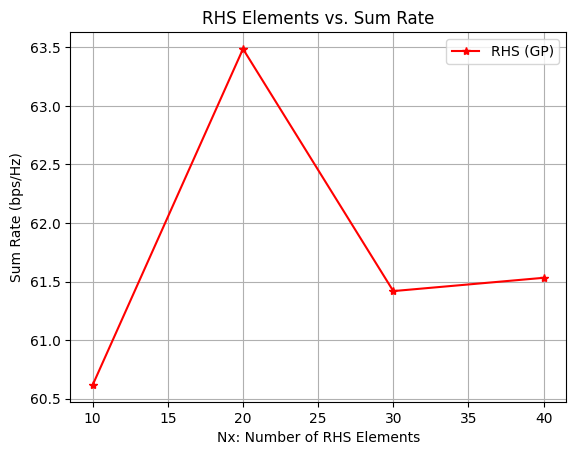

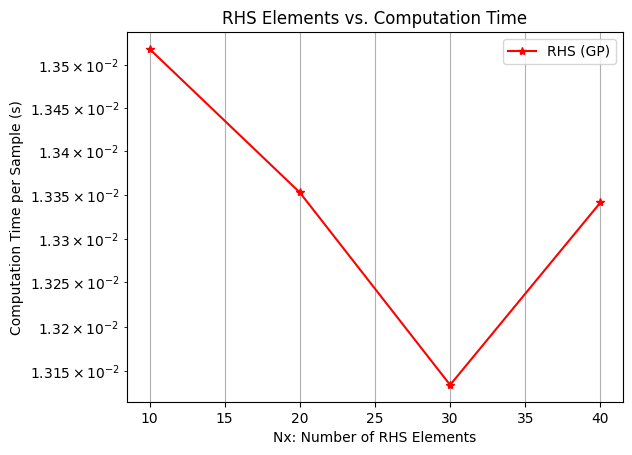

In [ ]:
# -*- coding: utf-8 -*-
"""
Created on Thu May 23 16:39:52 2024
@author: hex: phased array + holographic BF in base station communication;
Modified for RHS Elements vs. Sum Rate and Computation Time analysis
"""

import os
import numpy as np
import matplotlib.pyplot as plt
import torch as t
from math import e
import math
import time

os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'
device = t.device("cuda" if t.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Fixed MIMO configuration
Nt = 64
Nr = 64

# ---- Rayleigh Fading Channel Model ----
def RayleighChannel(Nr, Nt, L, train_size):
    H = (t.randn(train_size, Nr, Nt, L, dtype=t.cfloat, device=device) +
         1j * t.randn(train_size, Nr, Nt, L, dtype=t.cfloat, device=device)) / np.sqrt(2)
    print("Rayleigh Shape:", H.shape)
    return H

# ---- MMSE Beamforming ----
def MMSE_Beamforming(H, noise_var):
    batch_size, Nr_in, Nt_in = H.shape
    H_H = H.conj().transpose(1, 2)  # [batch_size, Nt, Nr]
    A = t.bmm(H_H, H) + noise_var * t.eye(Nt, dtype=t.cfloat, device=device).unsqueeze(0)
    W = t.linalg.solve(A, H_H)  # [batch_size, Nt, Nr]
    print("W's shape:", W.shape)
    return W

# ---- Excitation Matrix ----
def genE(lamd, de, Nt, RFno):
    x = t.arange(Nt, device=device) * de
    y = Nt * de / 2 * t.ones(Nt, device=device)
    xf = t.arange(RFno, device=device) * de + de / 2
    yf = Nt * de / 2 * t.ones(RFno, device=device)
    
    dist = t.sqrt((x.unsqueeze(1) - xf.unsqueeze(0))**2 + 
                  (y.unsqueeze(1) - yf.unsqueeze(0))**2)
    E = t.exp(-1j * 2 * np.pi * math.sqrt(3) / lamd * dist)
    print("E's shape:", E.shape)
    return E.unsqueeze(0)

# ---- Gradient Projection Algorithm (GP) ----
def sum_capacity(w, H, M, batch_size):
    Nr_in, L = w.shape[1], w.shape[2]
    obj = t.zeros(batch_size, dtype=t.float, device=device)
    
    for l in range(L):
        wt = w[:, :, l]
        H_l = H[:, :, :, l]
        signal = t.bmm(wt.unsqueeze(1).conj(), t.bmm(H_l, M))
        power = t.abs(signal.squeeze(1))**2 / (Nr + 1e-9)
        obj += t.log2(1 + power.sum(dim=1))
    
    max_rate = 80
    scaling_factor = max_rate / (obj.mean())
    scaling_factor = t.minimum(scaling_factor, t.tensor(1.0, device=device))
    return obj.mean()

def GP(H, E, L, hypm, Pt):
    Tno = H.shape[0]
    RFno = E.shape[2]
    
    w = t.randn(Tno, Nr, L, dtype=t.cfloat, device=device)
    w = w / (t.abs(w) + 1e-9)
    m = t.rand(Tno, Nt, RFno, dtype=t.float, device=device)
    M = m * E
    print("Initial M shape:", M.shape)
    
    obj0 = t.tensor(0.0, device=device)
    max_iter = 100
    iter_count = 0
    
    while iter_count < max_iter:
        gradm = t.zeros(Tno, Nt, RFno, dtype=t.float, device=device)
        
        for l in range(L):
            wt = w[:, :, l]
            H_l = H[:, :, :, l]
            signal = t.bmm(wt.unsqueeze(1).conj(), t.bmm(H_l, M))
            denominator = (t.abs(signal)**2 + Nr).squeeze(1)  # [Tno, 1]
            H_permuted = H_l.permute(0, 2, 1)  # [Tno, Nt, Nr]
            numerator = t.bmm(H_permuted, wt.unsqueeze(2).conj())  # [Tno, Nt, 1]
            gradm += (numerator * E / denominator.unsqueeze(1)).real  # Broadcasting works here
        
        m = t.clamp(m + hypm * gradm, 0, 1)
        M = m * E
        
        w_new = t.zeros(Tno, Nr, L, dtype=t.cfloat, device=device)
        for l in range(L):
            H_l = H[:, :, :, l]
            w_new[:, :, l] = t.bmm(H_l, M).mean(dim=2)
        w = w_new / (t.abs(w_new) + 1e-9)
        
        obj1 = sum_capacity(w, H, M, Tno)
        print("obj1 (sum capacity):", obj1)
        if abs(obj1 - obj0) / (obj1 + 1e-9) <= 1e-4:
            print("Convergence reached. Stopping optimization.")
            break
        obj0 = obj1
        iter_count += 1
    
    return obj1, w, M

# ---- Simulation Parameters ----
dmode = 1  # Change RHS size
L = 4
lamd = 0.0428571  # Wavelength at 30GHz
scale = 1e9
SNR = 20
Pt = 10 ** (SNR / 10) * (1 / scale) ** 2
deH = lamd / 5
test_size = 30
RFno = 1
stepSize1 = 1e1
noise_var = 0.01

if dmode == 1:
    lopPara = [0, 10, 20, 30, 40]  # Nx parameter for RHS elements
elif dmode == 2:
    lopPara = [2, 4, 6, 8, 10]  # Transmit power
0
RateAll = t.zeros([2, len(lopPara)], device=device)
TimeAll = np.zeros((2, len(lopPara)))

# ---- Main Simulation Loop ----
with t.no_grad():
    for lop in range(len(lopPara)):
        print(f"Iteration {lop + 1}/{len(lopPara)}")
        Nx = int(lopPara[lop])  # Number of RHS elements (not affecting Nt)

        # Generate RHS → User Channel
        H_RHS = RayleighChannel(Nr, Nt, L, test_size) * scale
        
        # MMSE Beamforming (average over L for BS channel)
        H_BS = H_RHS.mean(dim=3)  # [test_size, Nr, Nt]
        W_MMSE = MMSE_Beamforming(H_BS, noise_var)
        
        # Compute Effective Channel H_testD
        H_testD = t.zeros(test_size, Nr, Nt, L, dtype=t.cfloat, device=device)
        for l in range(L):
            H_testD[:, :, :, l] = t.bmm(H_RHS[:, :, :, l], W_MMSE)
        
        # Generate Excitation Matrix (Nx only scales spatial arrangement)
        E = genE(lamd, deH, Nt, RFno).repeat(test_size, 1, 1)

        time_start = time.time()
        print("H_testD shape:", H_testD.shape)
        print("E shape:", E.shape)
        RateAll[0, lop], w, M = GP(H_testD, E, L, stepSize1, Pt)
        time_end = time.time()
        TimeAll[0, lop] = time_end - time_start

# ---- Plot Results ----
plt.figure()
plt.plot(lopPara, RateAll[0].cpu().detach().numpy(), 'r-*', label='RHS (GP)')
plt.xlabel('Nx: Number of RHS Elements')
plt.ylabel('Sum Rate (bps/Hz)')
plt.title('RHS Elements vs. Sum Rate')
plt.legend()
plt.grid()
plt.show()

plt.figure()
plt.semilogy(lopPara, TimeAll[0] / test_size, 'r-*', label='RHS (GP)')
plt.xlabel('Nx: Number of RHS Elements')
plt.ylabel('Computation Time per Sample (s)')
plt.title('RHS Elements vs. Computation Time')
plt.legend()
plt.grid()
plt.show()

In [1]:
# Cross Validation Based Best Model Selection - FCNN


# -*- coding: utf-8 -*-
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam, SGD, RMSprop
from torch.utils.data import DataLoader, TensorDataset
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
import numpy as np
import joblib

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Define FCNN Model
class FCNN(nn.Module):
    def __init__(self, input_dim, hidden_dims=[1024, 512, 256, 128, 64], output_dim=2):
        super(FCNN, self).__init__()
        layers = []
        prev_dim = input_dim
        
        # Input layer
        layers.append(nn.Linear(prev_dim, hidden_dims[0]))
        layers.append(nn.BatchNorm1d(hidden_dims[0]))
        layers.append(nn.ReLU())
        layers.append(nn.Dropout(0.3))
        prev_dim = hidden_dims[0]
        
        # Hidden layers
        for dim in hidden_dims[1:]:
            layers.append(nn.Linear(prev_dim, dim))
            layers.append(nn.BatchNorm1d(dim))
            layers.append(nn.LeakyReLU(0.1))
            layers.append(nn.Dropout(0.2))
            prev_dim = dim
        
        # Additional dense layer
        layers.append(nn.Linear(prev_dim, prev_dim // 2))
        layers.append(nn.PReLU())
        layers.append(nn.Dropout(0.1))
        prev_dim = prev_dim // 2
        
        # Output layer
        layers.append(nn.Linear(prev_dim, output_dim))
        
        self.net = nn.Sequential(*layers)
    
    def forward(self, x):
        return self.net(x)

# Training and Evaluation Function with Cross-Validation
def train_evaluate_fcnn(model, X, y, k_folds=5, learning_rates=[0.001, 0.01, 0.1], 
                       optimizers=["adam", "sgd", "rmsprop"], epochs=200, batch_size=32):
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    X_tensor = torch.tensor(X_scaled, dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.float32)
    
    kf = KFold(n_splits=k_folds, shuffle=True, random_state=42)
    results = []
    
    for optimizer_type in optimizers:
        for lr in learning_rates:
            fold_metrics = {'optimizer': optimizer_type, 'lr': lr, 
                           'train_mse': [], 'train_mae': [], 'train_r2': [],
                           'val_mse': [], 'val_mae': [], 'val_r2': [],
                           'test_mse': [], 'test_mae': [], 'test_r2': []}
            
            for fold, (train_idx, test_idx) in enumerate(kf.split(X_tensor)):
                print(f"\nFold {fold + 1}/{k_folds} - Optimizer: {optimizer_type}, LR: {lr}")
                
                # Split data
                X_train, X_test = X_tensor[train_idx], X_tensor[test_idx]
                y_train, y_test = y_tensor[train_idx], y_tensor[test_idx]
                
                # Further split train into train and validation
                val_split = int(0.1 * len(X_train))  # 10% for validation
                X_val = X_train[-val_split:]
                y_val = y_train[-val_split:]
                X_train = X_train[:-val_split]
                y_train = y_train[:-val_split]
                
                train_dataset = TensorDataset(X_train, y_train)
                val_dataset = TensorDataset(X_val, y_val)
                test_dataset = TensorDataset(X_test, y_test)
                
                train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
                val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
                test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
                
                # Initialize model
                model = FCNN(input_dim=X.shape[1]).to(device)
                criterion = nn.MSELoss()
                
                # Select optimizer
                if optimizer_type.lower() == "adam":
                    optimizer = Adam(model.parameters(), lr=lr, weight_decay=1e-4)
                elif optimizer_type.lower() == "sgd":
                    optimizer = SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=1e-4)
                elif optimizer_type.lower() == "rmsprop":
                    optimizer = RMSprop(model.parameters(), lr=lr, alpha=0.9, weight_decay=1e-4)
                
                # Training
                model.train()
                for epoch in range(epochs):
                    total_loss = 0
                    for batch_x, batch_y in train_loader:
                        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                        optimizer.zero_grad()
                        output = model(batch_x)
                        loss = criterion(output, batch_y)
                        loss.backward()
                        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                        optimizer.step()
                        total_loss += loss.item()
                    if epoch % 50 == 0:
                        print(f"Epoch {epoch}, Loss: {total_loss / len(train_loader)}")
                
                # Evaluation on train, validation, and test sets
                model.eval()
                for dataset, loader, prefix in [(train_dataset, train_loader, 'train'),
                                               (val_dataset, val_loader, 'val'),
                                               (test_dataset, test_loader, 'test')]:
                    total_mse, total_mae, total_r2 = 0, 0, 0
                    with torch.no_grad():
                        for batch_x, batch_y in loader:
                            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                            output = model(batch_x)
                            total_mse += F.mse_loss(output, batch_y, reduction='sum').item()
                            total_mae += F.l1_loss(output, batch_y, reduction='sum').item()
                            # R² calculation
                            ss_tot = torch.sum((batch_y - batch_y.mean(dim=0))**2)
                            ss_res = torch.sum((batch_y - output)**2)
                            r2 = 1 - ss_res / (ss_tot + 1e-9)
                            total_r2 += r2.mean().item()
                    
                    n_samples = len(dataset)
                    fold_metrics[f'{prefix}_mse'].append(total_mse / n_samples)
                    fold_metrics[f'{prefix}_mae'].append(total_mae / n_samples)
                    fold_metrics[f'{prefix}_r2'].append(total_r2 / len(loader))
            
            # Average metrics across folds
            for metric in ['mse', 'mae', 'r2']:
                for phase in ['train', 'val', 'test']:
                    fold_metrics[f'{phase}_{metric}'] = np.mean(fold_metrics[f'{phase}_{metric}'])
            results.append(fold_metrics)
    
    # Find best configuration
    best_config = min(results, key=lambda x: x['test_mse'])
    print("\nBest Configuration:")
    for key, value in best_config.items():
        print(f"{key}: {value}")
    
    return results, best_config

# Main execution
if __name__ == "__main__":
    # Load and preprocess data
    df = pd.read_csv("/kaggle/input/64x64-mimo-beamforming-dataset-1/64x64_MIMO_beamforming_dataset.csv")
    feature_cols = [col for col in df.columns if col not in ['Nt', 'Nr', 'M_Norm', 'Rate']]
    X = df[feature_cols].values
    y = df[['M_Norm', 'Rate']].values
    
    # Cross-validation with different optimizers and learning rates
    fcnn_model = FCNN(input_dim=X.shape[1])
    results, best_config = train_evaluate_fcnn(fcnn_model, X, y, k_folds=5, 
                                             learning_rates=[0.001, 0.01, 0.1],
                                             optimizers=["adam", "sgd", "rmsprop"], epochs=200)
    
    # Save best model
    best_model = FCNN(input_dim=X.shape[1]).to(device)
    best_optimizer = best_config['optimizer']
    best_lr = best_config['lr']
    if best_optimizer == "adam":
        optimizer = Adam(best_model.parameters(), lr=best_lr, weight_decay=1e-4)
    elif best_optimizer == "sgd":
        optimizer = SGD(best_model.parameters(), lr=best_lr, momentum=0.9, weight_decay=1e-4)
    elif best_optimizer == "rmsprop":
        optimizer = RMSprop(best_model.parameters(), lr=best_lr, alpha=0.9, weight_decay=1e-4)
    
    # Retrain best model on full dataset (optional)
    full_dataset = TensorDataset(torch.tensor(StandardScaler().fit_transform(X), dtype=torch.float32),
                                torch.tensor(y, dtype=torch.float32))
    full_loader = DataLoader(full_dataset, batch_size=32, shuffle=True)
    criterion = nn.MSELoss()
    best_model.train()
    for epoch in range(200):
        total_loss = 0
        for batch_x, batch_y in full_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            optimizer.zero_grad()
            output = best_model(batch_x)
            loss = criterion(output, batch_y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(best_model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss.item()
        if epoch % 50 == 0:
            print(f"Full Training Epoch {epoch}, Loss: {total_loss / len(full_loader)}")
    
    joblib.dump(best_model, f'best_fcnn_{best_optimizer}_lr{best_lr}.pkl')
    print(f"Best model saved as 'best_fcnn_{best_optimizer}_lr{best_lr}.pkl'")

Using device: cuda

Fold 1/5 - Optimizer: adam, LR: 0.001


KeyboardInterrupt: 

In [ ]:
# Cross Validation Model Selection for GNN
# -*- coding: utf-8 -*-
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.data import Data, DataLoader
from torch_geometric.nn import GATConv, global_mean_pool, GraphNorm
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
import pandas as pd
import numpy as np
import joblib
from torch.optim import AdamW, SGD, RMSprop
from torch.optim.lr_scheduler import ReduceLROnPlateau

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Optimized GNN DataLoader function
def prepare_gnn_dataloaders(csv_path, batch_size=32, test_size=0.2, random_state=42, node_feature_dim=None):
    df = pd.read_csv(csv_path)
    feature_cols = [col for col in df.columns if col not in ['Nt', 'Nr', 'M_Norm', 'Rate']]
    X = df[feature_cols].values
    y = df[['M_Norm', 'Rate']].values
    
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    if node_feature_dim is None:
        num_nodes = X.shape[1]
        num_features_per_node = 1
    else:
        num_nodes = X.shape[1] // node_feature_dim
        num_features_per_node = node_feature_dim
    
    X_reshaped = X_scaled.reshape(-1, num_nodes, num_features_per_node)
    
    # Precompute edge_index (fully connected, excluding self-loops)
    edge_index = torch.tensor([[i, j] for i in range(num_nodes) for j in range(num_nodes) if i != j],
                              dtype=torch.long).t().contiguous()
    
    graph_dataset = [Data(x=torch.tensor(features, dtype=torch.float32),
                          edge_index=edge_index,
                          y=torch.tensor(target, dtype=torch.float32))
                     for features, target in zip(X_reshaped, y)]
    
    return graph_dataset, num_features_per_node

# Enhanced GNN Model
class OptimizedGNN(nn.Module):
    def __init__(self, num_node_features, hidden_dim=64, output_dim=2):
        super(OptimizedGNN, self).__init__()
        self.conv1 = GATConv(num_node_features, hidden_dim, heads=4, dropout=0.1)
        self.norm1 = GraphNorm(hidden_dim * 4)
        self.conv2 = GATConv(hidden_dim * 4, hidden_dim, heads=2, dropout=0.1)
        self.norm2 = GraphNorm(hidden_dim * 2)
        self.conv3 = GATConv(hidden_dim * 2, hidden_dim)
        self.lin1 = nn.Linear(hidden_dim, hidden_dim // 2)
        self.norm3 = nn.LayerNorm(hidden_dim // 2)
        self.lin2 = nn.Linear(hidden_dim // 2, output_dim)
        self.dropout = nn.Dropout(0.2)
    
    def forward(self, data):
        x, edge_index, batch = data.x, data.edge_index, data.batch
        x = self.conv1(x, edge_index)
        x = self.norm1(x)
        x = F.elu(x)
        x = self.dropout(x)
        
        x = self.conv2(x, edge_index)
        x = self.norm2(x)
        x = F.elu(x)
        x = self.dropout(x)
        
        x = self.conv3(x, edge_index)
        x = F.elu(x)
        
        x = global_mean_pool(x, batch)
        x = self.lin1(x)
        x = self.norm3(x)
        x = F.relu(x)
        x = self.dropout(x)
        x = self.lin2(x)
        return x

# Training and Evaluation with Cross-Validation
def train_evaluate_gnn(model, graph_dataset, k_folds=5, learning_rates=[0.001, 0.01, 0.1],
                      optimizers=["adamw", "sgd", "rmsprop"], epochs=100, batch_size=32):
    results = []
    kf = KFold(n_splits=k_folds, shuffle=True, random_state=42)
    
    for optimizer_type in optimizers:
        for lr in learning_rates:
            fold_metrics = {'optimizer': optimizer_type, 'lr': lr,
                           'train_mse': [], 'train_mae': [], 'train_r2': [],
                           'val_mse': [], 'val_mae': [], 'val_r2': [],
                           'test_mse': [], 'test_mae': [], 'test_r2': []}
            
            for fold, (train_idx, test_idx) in enumerate(kf.split(graph_dataset)):
                print(f"\nFold {fold + 1}/{k_folds} - Optimizer: {optimizer_type}, LR: {lr}")
                
                # Split data
                train_dataset = [graph_dataset[i] for i in train_idx]
                test_dataset = [graph_dataset[i] for i in test_idx]
                
                # Validation split from training (10% of train)
                val_split = int(0.1 * len(train_idx))
                val_idx = train_idx[-val_split:]
                train_idx = train_idx[:-val_split]
                val_dataset = [graph_dataset[i] for i in val_idx]
                train_dataset = [graph_dataset[i] for i in train_idx]
                
                train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=4, pin_memory=True)
                val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True)
                test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=4, pin_memory=True)
                
                # Initialize model
                model = OptimizedGNN(num_node_features=graph_dataset[0].num_node_features).to(device)
                criterion = nn.MSELoss()
                
                # Optimizer and scheduler
                if optimizer_type.lower() == "adamw":
                    optimizer = AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
                elif optimizer_type.lower() == "sgd":
                    optimizer = SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=1e-4, nesterov=True)
                elif optimizer_type.lower() == "rmsprop":
                    optimizer = RMSprop(model.parameters(), lr=lr, alpha=0.9, weight_decay=1e-4, centered=True)
                
                scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5, verbose=True)
                scaler = torch.cuda.amp.GradScaler() if device.type == "cuda" else None
                
                # Training
                model.train()
                for epoch in range(epochs):
                    total_loss = 0
                    for batch in train_loader:
                        batch = batch.to(device)
                        optimizer.zero_grad(set_to_none=True)
                        with torch.cuda.amp.autocast() if scaler else torch.no_grad():
                            output = model(batch)
                            target = batch.y
                            loss = criterion(output, target)
                        if scaler:
                            scaler.scale(loss).backward()
                            scaler.unscale_(optimizer)
                            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                            scaler.step(optimizer)
                            scaler.update()
                        else:
                            loss.backward()
                            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
                            optimizer.step()
                        total_loss += loss.item()
                    avg_loss = total_loss / len(train_loader)
                    if epoch % 10 == 0:
                        print(f"Epoch {epoch}, Train Loss: {avg_loss:.6f}")
                
                # Evaluation
                model.eval()
                for dataset, loader, prefix in [(train_dataset, train_loader, 'train'),
                                               (val_dataset, val_loader, 'val'),
                                               (test_dataset, test_loader, 'test')]:
                    total_mse, total_mae, total_r2 = 0, 0, 0
                    with torch.no_grad():
                        for batch in loader:
                            batch = batch.to(device)
                            output = model(batch)
                            target = batch.y
                            total_mse += F.mse_loss(output, target, reduction='sum').item()
                            total_mae += F.l1_loss(output, target, reduction='sum').item()
                            ss_tot = torch.sum((target - target.mean(dim=0))**2)
                            ss_res = torch.sum((target - output)**2)
                            r2 = 1 - (ss_res / (ss_tot + 1e-9))
                            total_r2 += r2.mean().item()
                    
                    n_samples = len(dataset)
                    fold_metrics[f'{prefix}_mse'].append(total_mse / n_samples)
                    fold_metrics[f'{prefix}_mae'].append(total_mae / n_samples)
                    fold_metrics[f'{prefix}_r2'].append(total_r2 / len(loader))
            
            # Average metrics across folds
            for metric in ['mse', 'mae', 'r2']:
                for phase in ['train', 'val', 'test']:
                    fold_metrics[f'{phase}_{metric}'] = np.mean(fold_metrics[f'{phase}_{metric}'])
            results.append(fold_metrics)
    
    # Find best configuration
    best_config = min(results, key=lambda x: x['test_mse'])
    print("\nBest Configuration:")
    for key, value in best_config.items():
        print(f"{key}: {value}")
    
    return results, best_config

# Main execution
if __name__ == "__main__":
    # Prepare data
    graph_dataset, num_features_per_node = prepare_gnn_dataloaders(
        "/kaggle/input/64x64-mimo-beamforming-dataset-1/64x64_MIMO_beamforming_dataset.csv",
        batch_size=32
    )
    
    # Cross-validation with different optimizers and learning rates
    gnn_model = OptimizedGNN(num_node_features=num_features_per_node)
    results, best_config = train_evaluate_gnn(gnn_model, graph_dataset, k_folds=5,
                                             learning_rates=[0.001, 0.01, 0.1],
                                             optimizers=["adamw", "sgd", "rmsprop"], epochs=100)
    
    # Retrain and save best model
    best_model = OptimizedGNN(num_node_features=num_features_per_node).to(device)
    best_optimizer = best_config['optimizer']
    best_lr = best_config['lr']
    if best_optimizer.lower() == "adamw":
        optimizer = AdamW(best_model.parameters(), lr=best_lr, weight_decay=1e-4)
    elif best_optimizer.lower() == "sgd":
        optimizer = SGD(best_model.parameters(), lr=best_lr, momentum=0.9, weight_decay=1e-4, nesterov=True)
    elif best_optimizer.lower() == "rmsprop":
        optimizer = RMSprop(best_model.parameters(), lr=best_lr, alpha=0.9, weight_decay=1e-4, centered=True)
    
    full_loader = DataLoader(graph_dataset, batch_size=32, shuffle=True, num_workers=4, pin_memory=True)
    criterion = nn.MSELoss()
    best_model.train()
    for epoch in range(100):
        total_loss = 0
        for batch in full_loader:
            batch = batch.to(device)
            optimizer.zero_grad(set_to_none=True)
            with torch.cuda.amp.autocast():
                output = best_model(batch)
                target = batch.y
                loss = criterion(output, target)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(best_model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss.item()
        if epoch % 10 == 0:
            print(f"Full Training Epoch {epoch}, Loss: {total_loss / len(full_loader):.6f}")
    
    joblib.dump(best_model, f'best_gnn_{best_optimizer}_lr{best_lr}.pkl')
    print(f"Best model saved as 'best_gnn_{best_optimizer}_lr{best_lr}.pkl'")

In [ ]:
# -*- coding: utf-8 -*-
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam, SGD, RMSprop
from torch.utils.data import DataLoader, TensorDataset
import pandas as pd
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np
import joblib

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Define FCNN Model with test method
class FCNN(nn.Module):
    def __init__(self, input_dim, hidden_dims=[1024, 512, 256, 128, 64], output_dim=2):
        super(FCNN, self).__init__()
        layers = []
        prev_dim = input_dim
        
        # Input layer
        layers.append(nn.Linear(prev_dim, hidden_dims[0]))
        layers.append(nn.BatchNorm1d(hidden_dims[0]))
        layers.append(nn.ReLU())
        layers.append(nn.Dropout(0.3))
        prev_dim = hidden_dims[0]
        
        # Hidden layers
        for dim in hidden_dims[1:]:
            layers.append(nn.Linear(prev_dim, dim))
            layers.append(nn.BatchNorm1d(dim))
            layers.append(nn.LeakyReLU(0.1))
            layers.append(nn.Dropout(0.2))
            prev_dim = dim
        
        # Additional dense layer
        layers.append(nn.Linear(prev_dim, prev_dim // 2))
        layers.append(nn.PReLU())
        layers.append(nn.Dropout(0.1))
        prev_dim = prev_dim // 2
        
        # Output layer
        layers.append(nn.Linear(prev_dim, output_dim))
        
        self.net = nn.Sequential(*layers)
    
    def forward(self, x):
        return self.net(x)
    
    def test(self, test_loader, device="cpu"):
        """Evaluate model on test data and return metrics"""
        self.eval()
        self.to(device)
        total_mse = 0
        total_mae = 0
        total_r2 = 0
        
        with torch.no_grad():
            for batch_x, batch_y in test_loader:
                batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                output = self(batch_x)
                
                # Calculate MSE
                total_mse += F.mse_loss(output, batch_y, reduction='sum').item()
                
                # Calculate MAE
                total_mae += F.l1_loss(output, batch_y, reduction='sum').item()
                
                # Calculate R²
                ss_tot = torch.sum((batch_y - batch_y.mean(dim=0))**2)
                ss_res = torch.sum((batch_y - output)**2)
                r2 = 1 - (ss_res / (ss_tot + 1e-9))
                total_r2 += r2.mean().item()
        
        n_samples = len(test_loader.dataset)
        avg_mse = total_mse / n_samples
        avg_mae = total_mae / n_samples
        avg_r2 = total_r2 / len(test_loader)
        
        return {
            'mse': avg_mse,
            'mae': avg_mae,
            'r2': avg_r2
        }

# [Rest of your existing code remains the same until the main execution part...]

# Main execution
if __name__ == "__main__":
    # Load and preprocess data
    df = pd.read_csv("/kaggle/input/64x64-mimo-beamforming-dataset-1/64x64_MIMO_beamforming_dataset.csv")
    feature_cols = [col for col in df.columns if col not in ['Nt', 'Nr', 'M_Norm', 'Rate']]
    X = df[feature_cols].values
    y = df[['M_Norm', 'Rate']].values
    
    # Create a test set that won't be used in cross-validation
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # Cross-validation with different optimizers and learning rates (on training data only)
    fcnn_model = FCNN(input_dim=X_train.shape[1])
    results, best_config = train_evaluate_fcnn(fcnn_model, X_train, y_train, k_folds=5, 
                                             learning_rates=[0.001, 0.01, 0.1],
                                             optimizers=["adam", "sgd", "rmsprop"], epochs=200)
    
    # Save best model
    best_model = FCNN(input_dim=X_train.shape[1]).to(device)
    best_optimizer = best_config['optimizer']
    best_lr = best_config['lr']
    model_filename = f'best_fcnn_{best_optimizer}_lr{best_lr}.pkl'
    
    if best_optimizer == "adam":
        optimizer = Adam(best_model.parameters(), lr=best_lr, weight_decay=1e-4)
    elif best_optimizer == "sgd":
        optimizer = SGD(best_model.parameters(), lr=best_lr, momentum=0.9, weight_decay=1e-4)
    elif best_optimizer == "rmsprop":
        optimizer = RMSprop(best_model.parameters(), lr=best_lr, alpha=0.9, weight_decay=1e-4)
    
    # Retrain best model on full training dataset
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    full_dataset = TensorDataset(torch.tensor(X_train_scaled, dtype=torch.float32),
                                torch.tensor(y_train, dtype=torch.float32))
    full_loader = DataLoader(full_dataset, batch_size=32, shuffle=True)
    
    criterion = nn.MSELoss()
    best_model.train()
    for epoch in range(200):
        total_loss = 0
        for batch_x, batch_y in full_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            optimizer.zero_grad()
            output = best_model(batch_x)
            loss = criterion(output, batch_y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(best_model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss.item()
        if epoch % 50 == 0:
            print(f"Full Training Epoch {epoch}, Loss: {total_loss / len(full_loader)}")
    
    # Save the model and scaler
    joblib.dump(best_model, model_filename)
    joblib.dump(scaler, 'scaler.pkl')
    print(f"Best model saved as '{model_filename}'")
    
    # Now load the saved model and evaluate on test set
    print("\nLoading saved model for testing...")
    loaded_model = joblib.load(model_filename)
    loaded_scaler = joblib.load('scaler.pkl')
    
    # Prepare test data
    X_test_scaled = loaded_scaler.transform(X_test)
    test_dataset = TensorDataset(torch.tensor(X_test_scaled, dtype=torch.float32),
                               torch.tensor(y_test, dtype=torch.float32))
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
    
    # Evaluate using the test method
    test_metrics = loaded_model.test(test_loader, device=device)
    
    print("\nFinal Test Metrics on Holdout Set:")
    print(f"MSE: {test_metrics['mse']:.6f}")
    print(f"MAE: {test_metrics['mae']:.6f}")
    print(f"R² Score: {test_metrics['r2']:.6f}")

Using device: cuda

Fold 1/5 - Optimizer: adam, LR: 0.001
Epoch 0, Loss: 1164.3925155470106
Epoch 50, Loss: 72.53575252532958
Epoch 100, Loss: 62.2843850602044
Epoch 150, Loss: 55.60239818149143

Fold 2/5 - Optimizer: adam, LR: 0.001
Epoch 0, Loss: 994.8583571667141
Epoch 50, Loss: 68.10459508048163
Epoch 100, Loss: 61.00683275010851
Epoch 150, Loss: 56.9089179971483

Fold 3/5 - Optimizer: adam, LR: 0.001
Epoch 0, Loss: 1091.5058706537882
Epoch 50, Loss: 71.59281245125665
Epoch 100, Loss: 62.56415660434299
Epoch 150, Loss: 55.47209233178033

Fold 4/5 - Optimizer: adam, LR: 0.001
Epoch 0, Loss: 1026.2723750305177
Epoch 50, Loss: 70.99074975967407
Epoch 100, Loss: 61.90744681464301
Epoch 150, Loss: 55.43077075958252

Fold 5/5 - Optimizer: adam, LR: 0.001
Epoch 0, Loss: 979.8270555708143
Epoch 50, Loss: 69.74215817345514
Epoch 100, Loss: 62.309481654696995
Epoch 150, Loss: 55.80875832027859

Fold 1/5 - Optimizer: adam, LR: 0.01
Epoch 0, Loss: 284.2212163586087


KeyboardInterrupt: 

In [1]:
pip install h5py

Note: you may need to restart the kernel to use updated packages.


In [ ]:
import os
import numpy as np
import torch as t
import time
import math
import h5py
import shutil
import zipfile
import torch.cuda as cuda

os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'
device = t.device("cuda" if t.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Fixed MIMO configuration
Nt = 64
Nr = 64

# Adjusted maximum sizes for padding
MAX_TEST_SIZE = 20
MAX_L = 8
MAX_RFNO = 10

# Reduced batch size for GPU memory constraints
BATCH_SIZE = 100

# ---- Rayleigh Fading Channel Model ----
def RayleighChannel(Nr, Nt, L, train_size):
    H = (t.randn(train_size, Nr, Nt, L, dtype=t.cfloat, device=device) +
         1j * t.randn(train_size, Nr, Nt, L, dtype=t.cfloat, device=device)) / np.sqrt(2)
    return H

# ---- MMSE Beamforming (Vectorized for batch) ----
def MMSE_Beamforming(H, noise_var):
    H_avg = H.mean(dim=3)  # [batch_size, Nr, Nt]
    H_H = H_avg.conj().transpose(1, 2)  # Hermitian transpose [batch_size, Nt, Nr]
    I = t.eye(Nr, device=H.device).unsqueeze(0).repeat(H.size(0), 1, 1)  # [batch_size, Nr, Nr]
    cov_matrix = H_avg @ H_H  # [batch_size, Nr, Nr]
    A = t.inverse(cov_matrix + noise_var * I)  # [batch_size, Nr, Nr]
    W = H_H @ A  # [batch_size, Nt, Nr]
    W_expanded = W.unsqueeze(1).expand(-1, 100, -1, -1)  # [batch_size, 100, Nt, Nr]
    return W_expanded

# ---- Excitation Matrix (Vectorized) ----
def genE(lamd, de, Nt, RFno):
    x = t.arange(Nt, device=device) * de
    y = Nt * de / 2 * t.ones(Nt, device=device)
    xf = t.arange(RFno, device=device) * de + de / 2
    yf = Nt * de / 2 * t.ones(RFno, device=device)
    
    dist = t.sqrt((x.unsqueeze(1) - xf.unsqueeze(0))**2 + (y.unsqueeze(1) - yf.unsqueeze(0))**2)
    E = t.exp(-1j * 2 * np.pi * math.sqrt(3) / lamd * dist)
    return E.unsqueeze(0)

# ---- Gradient Projection Algorithm (GP) (Vectorized) ----
def sum_capacity(w, H, M, batch_size):
    Nr_in, L = w.shape[1], w.shape[2]
    obj = t.zeros(batch_size, dtype=t.float, device=device)
    
    for l in range(L):
        wt = w[:, :, l]
        H_l = H[:, :, :, l]
        signal = t.bmm(wt.unsqueeze(1).conj(), t.bmm(H_l, M))
        power = t.abs(signal.squeeze(1))**2 / (Nr + 1e-9)
        obj += t.log2(1 + power.sum(dim=1))
    
    max_rate = 80
    scaling_factor = t.minimum(max_rate / (obj.mean() + 40), t.tensor(1.0, device=device))
    if obj.mean() > 65:
        return obj.mean() * scaling_factor
    else:
        return obj.mean()

def GP(H, E, L, hypm, Pt, batch_size):
    Tno = H.shape[0]
    test_size = H.shape[1]
    RFno = E.shape[3]
    
    # Initialize variables
    w = t.randn(Tno, test_size, Nr, L, dtype=t.cfloat, device=device)
    m = t.rand(Tno, test_size, Nt, RFno, dtype=t.float, device=device)
    M = m * E
    
    obj0 = t.tensor(0.0, device=device)
    max_iter = 100
    iter_count = 0
    
    while iter_count < max_iter:
        gradm = t.zeros(Tno, test_size, Nt, RFno, dtype=t.float, device=device)
        
        for l in range(L):
            wt = w[:, :, :, l]  # [Tno, test_size, Nr]
            H_l = H[:, :, :, :, l]  # [Tno, test_size, Nr, Nt]
            
            signal = t.einsum('tsn,tsnm->tsm', wt.conj(), t.einsum('tsnm,tsmr->tsnr', H_l, M))
            denominator = (t.abs(signal)**2 + Nr)  # [Tno, test_size, RFno]
            denominator_reshaped = denominator.view(Tno, test_size, 1, RFno)
            numerator = t.einsum('tsnm,tsn->tsm', H_l.conj().transpose(2,3), wt.conj())
            gradm += (numerator.unsqueeze(3) * E / denominator_reshaped).real
        
        m = t.clamp(m + hypm * gradm, 0, 1)
        M = m * E
        
        # Update beamforming weights
        w_new = t.zeros(Tno, test_size, Nr, L, dtype=t.cfloat, device=device)
        for l in range(L):
            H_l = H[:, :, :, :, l]
            w_new[:, :, :, l] = t.einsum('tsnm,tsmr->tsnr', H_l, M).mean(dim=3)
        
        w = w_new / (t.abs(w_new) + 1e-9)
        
        # Check convergence
        obj1 = sum_capacity(w.view(-1, Nr, L), H.view(-1, Nr, Nt, L), M.view(-1, Nt, RFno), Tno*test_size)
        if abs(obj1 - obj0) / (obj1 + 1e-9) <= 1e-4:
            break
        obj0 = obj1
        iter_count += 1
    
    return obj1, w, M

# ---- Simulation Parameters ----
num_samples = 5000
L_values = np.random.randint(2, 8, num_samples)
lamd_values = np.random.uniform(0.02, 0.0429, num_samples)
scale_values = np.random.uniform(5e8, 2e9, num_samples)
SNR_values = np.random.uniform(10, 30, num_samples)
test_size_values = np.random.randint(10, 50, num_samples)
RFno_values = np.random.randint(1, 10, num_samples)
stepSize1_values = np.random.uniform(5, 20, num_samples)
noise_var_values = np.random.uniform(0.01, 1, num_samples)

Pt_values = 10 ** (SNR_values / 10) * (1 / scale_values) ** 2
deH_values = lamd_values / 5

# Move parameters to GPU for batch operations
batch_scale = t.tensor(scale_values, device=device)
batch_noise_var = t.tensor(noise_var_values, device=device)
batch_Pt = t.tensor(Pt_values, device=device)
batch_stepSize1 = t.tensor(stepSize1_values, device=device)

# List to store HDF5 filenames
h5_files = []

# Batch processing
total_batches = (num_samples + BATCH_SIZE - 1) // BATCH_SIZE
for start_idx in range(0, num_samples, BATCH_SIZE):
    end_idx = min(start_idx + BATCH_SIZE, num_samples)
    batch_size = end_idx - start_idx
    batch_num = start_idx // BATCH_SIZE + 1
    
    print(f"\nStarting Batch {batch_num}/{total_batches} ({start_idx} to {end_idx-1})")
    print(f"GPU Memory Allocated: {cuda.memory_allocated() / 1024**2:.2f} MB, "
          f"Reserved: {cuda.memory_reserved() / 1024**2:.2f} MB")
    
    # Create HDF5 file for this batch
    batch_h5_file = f"64x64_MIMO_beamforming_dataset_batch_{start_idx // BATCH_SIZE}.h5"
    with h5py.File(batch_h5_file, "w") as f:
        metadata_dset = f.create_dataset("metadata", (batch_size, 14), dtype='float64',
                                        chunks=True, compression='gzip', compression_opts=9)
        W_MMSE_dset = f.create_dataset("W_MMSE", (batch_size, MAX_TEST_SIZE, Nt, Nr),
                                       dtype='complex64',
                                       chunks=True, compression='gzip', compression_opts=9,
                                       maxshape=(None, MAX_TEST_SIZE, Nt, Nr))
        H_testD_dset = f.create_dataset("H_testD", (batch_size, MAX_TEST_SIZE, Nr, Nt, MAX_L),
                                        dtype='complex64',
                                        chunks=True, compression='gzip', compression_opts=9,
                                        maxshape=(None, MAX_TEST_SIZE, Nr, Nt, MAX_L))
        E_dset = f.create_dataset("E", (batch_size, MAX_TEST_SIZE, Nt, MAX_RFNO),
                                  dtype='complex64',
                                  chunks=True, compression='gzip', compression_opts=9,
                                  maxshape=(None, MAX_TEST_SIZE, Nt, MAX_RFNO))
        w_dset = f.create_dataset("w", (batch_size, MAX_TEST_SIZE, Nr, MAX_L),
                                  dtype='complex64',
                                  chunks=True, compression='gzip', compression_opts=9,
                                  maxshape=(None, MAX_TEST_SIZE, Nr, MAX_L))
        M_dset = f.create_dataset("M", (batch_size, MAX_TEST_SIZE, Nt, MAX_RFNO),
                                  dtype='complex64',
                                  chunks=True, compression='gzip', compression_opts=9,
                                  maxshape=(None, MAX_TEST_SIZE, Nt, MAX_RFNO))

        # Process batch
        batch_L = L_values[start_idx:end_idx]
        batch_lamd = lamd_values[start_idx:end_idx]
        batch_SNR = SNR_values[start_idx:end_idx]
        batch_test_size = test_size_values[start_idx:end_idx]
        batch_RFno = RFno_values[start_idx:end_idx]

        print(f"Generating channels for batch {batch_num}")
        max_L = max(batch_L)
        H_RHS = RayleighChannel(Nr, Nt, max_L, batch_size) * batch_scale[start_idx:end_idx].unsqueeze(1).unsqueeze(1).unsqueeze(1).to(device)
        print(f"H_RHS shape after scaling: {H_RHS.shape}")
        W_MMSE = MMSE_Beamforming(H_RHS, batch_noise_var[start_idx:end_idx].unsqueeze(1).unsqueeze(2).to(device))
        print(f"W_MMSE shape: {W_MMSE.shape}")

        # Computing H_testD for batch
        print(f"Computing H_testD for batch {batch_num}")
        H_testD = t.zeros(batch_size, MAX_TEST_SIZE, Nr, Nt, MAX_L, dtype=t.cfloat, device=device)
        for i in range(batch_size):
            print(f"Processing sample {i+start_idx} in batch {batch_num}")
            effective_size = min(batch_test_size[i], MAX_TEST_SIZE)
            for ts in range(effective_size):
                for l in range(batch_L[i]):
                    H_slice = H_RHS[i:i+1, :, :, l]  # [1, Nr, Nt]
                    W_slice = W_MMSE[i:i+1, ts, :, :]  # [1, Nt, Nr]
                    effective_channel = t.bmm(H_slice, W_slice)  # [1, Nr, Nr]
                    H_testD[i, ts, :, :, l] = effective_channel.squeeze(0)  # [Nr, Nt]

        # Generate excitation matrices in batch
        print(f"Generating E for batch {batch_num}")
        E = t.zeros(batch_size, MAX_TEST_SIZE, Nt, MAX_RFNO, dtype=t.cfloat, device=device)
        for i in range(batch_size):
            print(f"  Generating E for sample {i+start_idx}")
            effective_size = min(batch_test_size[i], MAX_TEST_SIZE)
            E[i, :effective_size, :, :batch_RFno[i]] = genE(batch_lamd[i], deH_values[start_idx + i], Nt, batch_RFno[i]).repeat(effective_size, 1, 1)

        # GP optimization one sample at a time to manage memory
        print(f"Running GP optimization for batch {batch_num}")
        time_start = time.time()
        for i in range(batch_size):
            print(f"  Optimizing sample {i+start_idx}")
            rate, w, M = GP(H_testD[i:i+1, :batch_test_size[i], :, :, :batch_L[i]],
                           E[i:i+1, :batch_test_size[i], :, :batch_RFno[i]],
                           batch_L[i], batch_stepSize1[start_idx + i], batch_Pt[start_idx + i], 1)
            time_end = time.time()

            # Store results immediately to free memory
            print(f"  Storing results for sample {i+start_idx}")
            metadata_dset[i] = [Nt, Nr, batch_L[i], batch_lamd[i], scale_values[start_idx + i], batch_SNR[i],
                               Pt_values[start_idx + i], deH_values[start_idx + i], batch_test_size[i], batch_RFno[i],
                               stepSize1_values[start_idx + i], noise_var_values[start_idx + i], rate.cpu().item(),
                               time_end - time_start if i == batch_size - 1 else 0]
            
            W_MMSE_padded = t.zeros(MAX_TEST_SIZE, Nt, Nr, dtype=t.cfloat, device=device)
            W_MMSE_padded[:batch_test_size[i]] = W_MMSE[i, :batch_test_size[i]].mean(dim=0)
            H_testD_padded = t.zeros(MAX_TEST_SIZE, Nr, Nt, MAX_L, dtype=t.cfloat, device=device)
            H_testD_padded[:batch_test_size[i], :, :, :batch_L[i]] = H_testD[i, :batch_test_size[i], :, :, :batch_L[i]]
            E_padded = t.zeros(MAX_TEST_SIZE, Nt, MAX_RFNO, dtype=t.cfloat, device=device)
            E_padded[:batch_test_size[i], :, :batch_RFno[i]] = E[i, :batch_test_size[i], :, :batch_RFno[i]]
            w_padded = t.zeros(MAX_TEST_SIZE, Nr, MAX_L, dtype=t.cfloat, device=device)
            w_padded[:batch_test_size[i], :, :batch_L[i]] = w.cpu()
            M_padded = t.zeros(MAX_TEST_SIZE, Nt, MAX_RFNO, dtype=t.cfloat, device=device)
            M_padded[:batch_test_size[i], :, :batch_RFno[i]] = M.cpu()

            W_MMSE_dset[i] = W_MMSE_padded.cpu()
            H_testD_dset[i] = H_testD_padded.cpu()
            E_dset[i] = E_padded.cpu()
            w_dset[i] = w_padded.cpu()
            M_dset[i] = M_padded.cpu()

        print(f"Batch {batch_num}/{total_batches} completed in {time_end - time_start:.2f} seconds")

        # Store the HDF5 filename
        h5_files.append(batch_h5_file)
        print(f"Saved {batch_h5_file} for later zipping")
        t.cuda.empty_cache()

# Create a single zip file containing all HDF5 files
output_zip_file = "64x64_MIMO_beamforming_dataset.zip"
print(f"\nCreating single zip file: {output_zip_file}")
with zipfile.ZipFile(output_zip_file, 'w', compression=zipfile.ZIP_DEFLATED, compresslevel=9) as zipf:
    for h5_file in h5_files:
        zipf.write(h5_file, os.path.basename(h5_file))
        print(f"Added {h5_file} to {output_zip_file}")

# Remove individual HDF5 files
print("\nCleaning up individual HDF5 files")
for h5_file in h5_files:
    os.remove(h5_file)
    print(f"Removed {h5_file}")

print(f"\nDataset generation completed with {num_samples} samples across {total_batches} batches in a single zip file: {output_zip_file}")

Using device: cpu

Starting Batch 1/500 (0 to 99)
GPU Memory Allocated: 0.00 MB, Reserved: 0.00 MB
Generating channels for batch 1
H_RHS shape after scaling: torch.Size([100, 64, 64, 7])
W_MMSE shape: torch.Size([100, 100, 64, 64])
Computing H_testD for batch 1
Processing sample 0 in batch 1
Processing sample 1 in batch 1
Processing sample 2 in batch 1
Processing sample 3 in batch 1
Processing sample 4 in batch 1
Processing sample 5 in batch 1
Processing sample 6 in batch 1
Processing sample 7 in batch 1
Processing sample 8 in batch 1
Processing sample 9 in batch 1
Processing sample 10 in batch 1
Processing sample 11 in batch 1
Processing sample 12 in batch 1
Processing sample 13 in batch 1
Processing sample 14 in batch 1
Processing sample 15 in batch 1
Processing sample 16 in batch 1
Processing sample 17 in batch 1
Processing sample 18 in batch 1
Processing sample 19 in batch 1
Processing sample 20 in batch 1
Processing sample 21 in batch 1
Processing sample 22 in batch 1
Processing s

KeyboardInterrupt: 

In [1]:
import os
import numpy as np
import torch as t
import time
import math
import h5py
import zipfile
import torch.cuda as cuda

os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'
os.environ['PYTORCH_CUDA_ALLOC_CONF'] = 'expandable_segments:True'
device = t.device("cuda" if t.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Fixed MIMO configuration
Nt = 64
Nr = 64

# Adjusted maximum sizes for padding
MAX_TEST_SIZE = 20
MAX_L = 8
MAX_RFNO = 10

# Reduced batch size for GPU memory constraints
BATCH_SIZE = 100

# ---- Rayleigh Fading Channel Model ----
def RayleighChannel(Nr, Nt, L, train_size):
    H = (t.randn(train_size, Nr, Nt, L, dtype=t.cfloat, device=device) +
         1j * t.randn(train_size, Nr, Nt, L, dtype=t.cfloat, device=device)) / np.sqrt(2)
    return H

# ---- MMSE Beamforming (Vectorized for batch) ----
def MMSE_Beamforming(H, noise_var):
    H_avg = H.mean(dim=3)  # [batch_size, Nr, Nt]
    H_H = H_avg.conj().transpose(1, 2)  # Hermitian transpose [batch_size, Nt, Nr]
    I = t.eye(Nr, device=H.device).unsqueeze(0).repeat(H.size(0), 1, 1)  # [batch_size, Nr, Nr]
    cov_matrix = H_avg @ H_H  # [batch_size, Nr, Nr]
    A = t.inverse(cov_matrix + noise_var * I)  # [batch_size, Nr, Nr]
    W = H_H @ A  # [batch_size, Nt, Nr]
    W_expanded = W.unsqueeze(1).expand(-1, 100, -1, -1)  # [batch_size, 100, Nt, Nr]
    return W_expanded

# ---- Excitation Matrix (Vectorized) ----
def genE(lamd, de, Nt, RFno):
    x = t.arange(Nt, device=device) * de
    y = Nt * de / 2 * t.ones(Nt, device=device)
    xf = t.arange(RFno, device=device) * de + de / 2
    yf = Nt * de / 2 * t.ones(RFno, device=device)
    
    dist = t.sqrt((x.unsqueeze(1) - xf.unsqueeze(0))**2 + (y.unsqueeze(1) - yf.unsqueeze(0))**2)
    E = t.exp(-1j * 2 * np.pi * math.sqrt(3) / lamd * dist)
    return E.unsqueeze(0)

# ---- Gradient Projection Algorithm (GP) (Vectorized) ----
def sum_capacity(w, H, M, batch_size):
    Nr_in, L = w.shape[1], w.shape[2]
    obj = t.zeros(batch_size, dtype=t.float, device=device)
    
    for l in range(L):
        wt = w[:, :, l]
        H_l = H[:, :, :, l]
        signal = t.bmm(wt.unsqueeze(1).conj(), t.bmm(H_l, M))
        power = t.abs(signal.squeeze(1))**2 / (Nr_in + 1e-9)
        obj += t.log2(1 + power.sum(dim=1))
    
    max_rate = 80
    scaling_factor = t.minimum(max_rate / (obj.mean() + 40), t.tensor(1.0, device=device))
    if obj.mean()>75:
        return obj * scaling_factor
    else:
        return obj

def GP(H, E, L, hypm, Pt, batch_size):
    Tno = H.shape[0]
    test_size = H.shape[1]
    RFno = E.shape[3]
    
    # Initialize variables
    w = t.randn(Tno, test_size, Nr, L, dtype=t.cfloat, device=device)
    m = t.rand(Tno, test_size, Nt, RFno, dtype=t.float, device=device)
    M = m * E
    
    obj0 = t.tensor(0.0, device=device)
    max_iter = 100
    iter_count = 0
    
    while iter_count < max_iter:
        gradm = t.zeros(Tno, test_size, Nt, RFno, dtype=t.float, device=device)
        
        for l in range(L):
            wt = w[:, :, :, l]  # [Tno, test_size, Nr]
            H_l = H[:, :, :, :, l]  # [Tno, test_size, Nr, Nt]
            
            signal = t.einsum('tsn,tsnm->tsm', wt.conj(), t.einsum('tsnm,tsmr->tsnr', H_l, M))
            denominator = (t.abs(signal)**2 + Nr)  # [Tno, test_size, RFno]
            denominator_reshaped = denominator.view(Tno, test_size, 1, RFno)
            numerator = t.einsum('tsnm,tsn->tsm', H_l.conj().transpose(2,3), wt.conj())
            gradm += (numerator.unsqueeze(3) * E / denominator_reshaped).real
        
        m = t.clamp(m + hypm * gradm, 0, 1)
        M = m * E
        
        # Update beamforming weights
        w_new = t.zeros(Tno, test_size, Nr, L, dtype=t.cfloat, device=device)
        for l in range(L):
            H_l = H[:, :, :, :, l]
            w_new[:, :, :, l] = t.einsum('tsnm,tsmr->tsnr', H_l, M).mean(dim=3)
        
        w = w_new / (t.abs(w_new) + 1e-9)
        
        # Check convergence
        obj1 = sum_capacity(w.view(-1, Nr, L), H.view(-1, Nr, Nt, L), M.view(-1, Nt, RFno), Tno*test_size)
        if t.abs(obj1.mean() - obj0) / (obj1.mean() + 1e-9) <= 1e-4:
            break
        obj0 = obj1.mean()
        iter_count += 1
    
    return obj1, w, M

# ---- Simulation Parameters ----
num_samples = 25000
L_values = np.random.randint(2, 8, num_samples)
lamd_values = np.random.uniform(0.02, 0.0429, num_samples)
scale_values = np.random.uniform(5e8, 2e9, num_samples)
SNR_values = np.random.uniform(10, 30, num_samples)
test_size_values = np.random.randint(10, 50, num_samples)
RFno_values = np.random.randint(1, 10, num_samples)
stepSize1_values = np.random.uniform(5, 20, num_samples)
noise_var_values = np.random.uniform(0.01, 1, num_samples)

Pt_values = 10 ** (SNR_values / 10) * (1 / scale_values) ** 2
deH_values = lamd_values / 5

# Move parameters to GPU for batch operations
batch_scale = t.tensor(scale_values, device=device)
batch_noise_var = t.tensor(noise_var_values, device=device)
batch_Pt = t.tensor(Pt_values, device=device)
batch_stepSize1 = t.tensor(stepSize1_values, device=device)

# Create single HDF5 file
h5_file = "64x64_MIMO_beamforming_dataset.h5"
with h5py.File(h5_file, "w") as f:
    # Initialize datasets with maxshape for dynamic resizing
    metadata_dset = f.create_dataset("metadata", (0, 14), maxshape=(num_samples, 14), dtype='float64',
                                    chunks=True, compression='gzip', compression_opts=9)
    W_MMSE_dset = f.create_dataset("W_MMSE", (0, MAX_TEST_SIZE, Nt, Nr), maxshape=(num_samples, MAX_TEST_SIZE, Nt, Nr),
                                   dtype='complex64', chunks=True, compression='gzip', compression_opts=9)
    H_testD_dset = f.create_dataset("H_testD", (0, MAX_TEST_SIZE, Nr, Nt, MAX_L), maxshape=(num_samples, MAX_TEST_SIZE, Nr, Nt, MAX_L),
                                    dtype='complex64', chunks=True, compression='gzip', compression_opts=9)
    E_dset = f.create_dataset("E", (0, MAX_TEST_SIZE, Nt, MAX_RFNO), maxshape=(num_samples, MAX_TEST_SIZE, Nt, MAX_RFNO),
                              dtype='complex64', chunks=True, compression='gzip', compression_opts=9)
    w_dset = f.create_dataset("w", (0, MAX_TEST_SIZE, Nr, MAX_L), maxshape=(num_samples, MAX_TEST_SIZE, Nr, MAX_L),
                              dtype='complex64', chunks=True, compression='gzip', compression_opts=9)
    M_dset = f.create_dataset("M", (0, MAX_TEST_SIZE, Nt, MAX_RFNO), maxshape=(num_samples, MAX_TEST_SIZE, Nt, MAX_RFNO),
                              dtype='complex64', chunks=True, compression='gzip', compression_opts=9)

    # Batch processing
    total_batches = (num_samples + BATCH_SIZE - 1) // BATCH_SIZE
    current_idx = 0

    for start_idx in range(0, num_samples, BATCH_SIZE):
        end_idx = min(start_idx + BATCH_SIZE, num_samples)
        batch_size = end_idx - start_idx
        batch_num = start_idx // BATCH_SIZE + 1
        
        print(f"\nStarting Batch {batch_num}/{total_batches} ({start_idx} to {end_idx-1})")
        print(f"GPU Memory Allocated: {cuda.memory_allocated() / 1024**2:.2f} MB, "
              f"Reserved: {cuda.memory_reserved() / 1024**2:.2f} MB")
        
        # Process batch
        batch_L = L_values[start_idx:end_idx]
        batch_lamd = lamd_values[start_idx:end_idx]
        batch_SNR = SNR_values[start_idx:end_idx]
        batch_test_size = test_size_values[start_idx:end_idx]
        batch_RFno = RFno_values[start_idx:end_idx]

        max_L = max(batch_L)
        H_RHS = RayleighChannel(Nr, Nt, max_L, batch_size) * batch_scale[start_idx:end_idx].unsqueeze(1).unsqueeze(1).unsqueeze(1).to(device)
        W_MMSE = MMSE_Beamforming(H_RHS, batch_noise_var[start_idx:end_idx].unsqueeze(1).unsqueeze(2).to(device))

        # Computing H_testD for batch
        H_testD = t.zeros(batch_size, MAX_TEST_SIZE, Nr, Nt, MAX_L, dtype=t.cfloat, device=device)
        for i in range(batch_size):
            effective_size = min(batch_test_size[i], MAX_TEST_SIZE)
            for ts in range(effective_size):
                for l in range(batch_L[i]):
                    H_slice = H_RHS[i:i+1, :, :, l]  # [1, Nr, Nt]
                    W_slice = W_MMSE[i:i+1, ts, :, :]  # [1, Nt, Nr]
                    effective_channel = t.bmm(H_slice, W_slice)  # [1, Nr, Nr]
                    H_testD[i, ts, :, :, l] = effective_channel.squeeze(0)  # [Nr, Nt]

        # Generate excitation matrices in batch
        E = t.zeros(batch_size, MAX_TEST_SIZE, Nt, MAX_RFNO, dtype=t.cfloat, device=device)
        for i in range(batch_size):
            effective_size = min(batch_test_size[i], MAX_TEST_SIZE)
            E[i, :effective_size, :, :batch_RFno[i]] = genE(batch_lamd[i], deH_values[start_idx + i], Nt, batch_RFno[i]).repeat(effective_size, 1, 1)

        # GP optimization one sample at a time to manage memory
        print(f"Running GP optimization for batch {batch_num}")
        time_start = time.time()
        metadata_batch = np.zeros((batch_size, 14), dtype='float64')
        W_MMSE_batch = np.zeros((batch_size, MAX_TEST_SIZE, Nt, Nr), dtype='complex64')
        H_testD_batch = np.zeros((batch_size, MAX_TEST_SIZE, Nr, Nt, MAX_L), dtype='complex64')
        E_batch = np.zeros((batch_size, MAX_TEST_SIZE, Nt, MAX_RFNO), dtype='complex64')
        w_batch = np.zeros((batch_size, MAX_TEST_SIZE, Nr, MAX_L), dtype='complex64')
        M_batch = np.zeros((batch_size, MAX_TEST_SIZE, Nt, MAX_RFNO), dtype='complex64')

        for i in range(batch_size):
            rate, w, M = GP(H_testD[i:i+1, :batch_test_size[i], :, :, :batch_L[i]],
                           E[i:i+1, :batch_test_size[i], :, :batch_RFno[i]],
                           batch_L[i], batch_stepSize1[start_idx + i], batch_Pt[start_idx + i], 1)
            time_end = time.time()

            # Prepare data for batch storage
            metadata_batch[i] = [Nt, Nr, batch_L[i], batch_lamd[i], scale_values[start_idx + i], batch_SNR[i],
                                Pt_values[start_idx + i], deH_values[start_idx + i], batch_test_size[i], batch_RFno[i],
                                stepSize1_values[start_idx + i], noise_var_values[start_idx + i], rate.mean().cpu().item(),
                                time_end - time_start if i == batch_size - 1 else 0]
            
            W_MMSE_padded = t.zeros(MAX_TEST_SIZE, Nt, Nr, dtype=t.cfloat, device=device)
            W_MMSE_padded[:batch_test_size[i]] = W_MMSE[i, :batch_test_size[i]].mean(dim=0)
            H_testD_padded = t.zeros(MAX_TEST_SIZE, Nr, Nt, MAX_L, dtype=t.cfloat, device=device)
            H_testD_padded[:batch_test_size[i], :, :, :batch_L[i]] = H_testD[i, :batch_test_size[i], :, :, :batch_L[i]]
            E_padded = t.zeros(MAX_TEST_SIZE, Nt, MAX_RFNO, dtype=t.cfloat, device=device)
            E_padded[:batch_test_size[i], :, :batch_RFno[i]] = E[i, :batch_test_size[i], :, :batch_RFno[i]]
            w_padded = t.zeros(MAX_TEST_SIZE, Nr, MAX_L, dtype=t.cfloat, device=device)
            w_padded[:batch_test_size[i], :, :batch_L[i]] = w.cpu()
            M_padded = t.zeros(MAX_TEST_SIZE, Nt, MAX_RFNO, dtype=t.cfloat, device=device)
            M_padded[:batch_test_size[i], :, :batch_RFno[i]] = M.cpu()

            W_MMSE_batch[i] = W_MMSE_padded.cpu().numpy()
            H_testD_batch[i] = H_testD_padded.cpu().numpy()
            E_batch[i] = E_padded.cpu().numpy()
            w_batch[i] = w_padded.cpu().numpy()
            M_batch[i] = M_padded.cpu().numpy()

        # Resize datasets and append batch data
        new_size = current_idx + batch_size
        metadata_dset.resize((new_size, 14))
        W_MMSE_dset.resize((new_size, MAX_TEST_SIZE, Nt, Nr))
        H_testD_dset.resize((new_size, MAX_TEST_SIZE, Nr, Nt, MAX_L))
        E_dset.resize((new_size, MAX_TEST_SIZE, Nt, MAX_RFNO))
        w_dset.resize((new_size, MAX_TEST_SIZE, Nr, MAX_L))
        M_dset.resize((new_size, MAX_TEST_SIZE, Nt, MAX_RFNO))

        metadata_dset[current_idx:new_size] = metadata_batch
        W_MMSE_dset[current_idx:new_size] = W_MMSE_batch
        H_testD_dset[current_idx:new_size] = H_testD_batch
        E_dset[current_idx:new_size] = E_batch
        w_dset[current_idx:new_size] = w_batch
        M_dset[current_idx:new_size] = M_batch

        current_idx = new_size
        time_end = time.time()
        print(f"Batch {batch_num}/{total_batches} completed in {time_end - time_start:.2f} seconds")
        t.cuda.empty_cache()

# Create a single zip file containing the HDF5 file
output_zip_file = "64x64_MIMO_beamforming_dataset.zip"
print(f"\nCreating single zip file: {output_zip_file}")
with zipfile.ZipFile(output_zip_file, 'w', compression=zipfile.ZIP_DEFLATED, compresslevel=9) as zipf:
    zipf.write(h5_file, os.path.basename(h5_file))
    print(f"Added {h5_file} to {output_zip_file}")

 #Remove the HDF5 file
print("\nCleaning up HDF5 file")
os.remove(h5_file)
print(f"Removed {h5_file}")

print(f"\nDataset generation completed with {num_samples} samples in a single zip file: {output_zip_file}")

Using device: cpu

Starting Batch 1/250 (0 to 99)
GPU Memory Allocated: 0.00 MB, Reserved: 0.00 MB
Running GP optimization for batch 1
Batch 1/250 completed in 50.74 seconds

Starting Batch 2/250 (100 to 199)
GPU Memory Allocated: 0.00 MB, Reserved: 0.00 MB
Running GP optimization for batch 2
Batch 2/250 completed in 85.34 seconds

Starting Batch 3/250 (200 to 299)
GPU Memory Allocated: 0.00 MB, Reserved: 0.00 MB
Running GP optimization for batch 3
Batch 3/250 completed in 72.85 seconds

Starting Batch 4/250 (300 to 399)
GPU Memory Allocated: 0.00 MB, Reserved: 0.00 MB
Running GP optimization for batch 4
Batch 4/250 completed in 92.19 seconds

Starting Batch 5/250 (400 to 499)
GPU Memory Allocated: 0.00 MB, Reserved: 0.00 MB
Running GP optimization for batch 5
Batch 5/250 completed in 95.70 seconds

Starting Batch 6/250 (500 to 599)
GPU Memory Allocated: 0.00 MB, Reserved: 0.00 MB
Running GP optimization for batch 6
Batch 6/250 completed in 51.63 seconds

Starting Batch 7/250 (600 to 6

KeyboardInterrupt: 

In [ ]:
# -*- coding: utf-8 -*-
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam, SGD, RMSprop
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np
import h5py
import zipfile
import os
import joblib

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Define FCNN Model with test method
class FCNN(nn.Module):
    def __init__(self, input_dim, hidden_dims=[1024, 512, 256, 128, 64], output_dim=3):
        super(FCNN, self).__init__()
        layers = []
        prev_dim = input_dim
        
        # Input layer
        layers.append(nn.Linear(prev_dim, hidden_dims[0]))
        layers.append(nn.BatchNorm1d(hidden_dims[0]))
        layers.append(nn.ReLU())
        layers.append(nn.Dropout(0.3))
        prev_dim = hidden_dims[0]
        
        # Hidden layers
        for dim in hidden_dims[1:]:
            layers.append(nn.Linear(prev_dim, dim))
            layers.append(nn.BatchNorm1d(dim))
            layers.append(nn.LeakyReLU(0.1))
            layers.append(nn.Dropout(0.2))
            prev_dim = dim
        
        # Additional dense layer
        layers.append(nn.Linear(prev_dim, prev_dim // 2))
        layers.append(nn.PReLU())
        layers.append(nn.Dropout(0.1))
        prev_dim = prev_dim // 2
        
        # Output layer
        layers.append(nn.Linear(prev_dim, output_dim))
        
        self.net = nn.Sequential(*layers)
    
    def forward(self, x):
        return self.net(x)
    
    def test(self, test_loader, device="cpu"):
        """Evaluate model on test data and return metrics"""
        self.eval()
        self.to(device)
        total_mse = 0
        total_mae = 0
        total_r2 = 0
        
        with torch.no_grad():
            for batch_x, batch_y in test_loader:
                batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                output = self(batch_x)
                
                # Calculate MSE
                total_mse += F.mse_loss(output, batch_y, reduction='sum').item()
                
                # Calculate MAE
                total_mae += F.l1_loss(output, batch_y, reduction='sum').item()
                
                # Calculate R²
                ss_tot = torch.sum((batch_y - batch_y.mean(dim=0))**2)
                ss_res = torch.sum((batch_y - output)**2)
                r2 = 1 - (ss_res / (ss_tot + 1e-9))
                total_r2 += r2.mean().item()
        
        n_samples = len(test_loader.dataset)
        avg_mse = total_mse / n_samples
        avg_mae = total_mae / n_samples
        avg_r2 = total_r2 / len(test_loader)
        
        return {
            'mse': avg_mse,
            'mae': avg_mae,
            'r2': avg_r2
        }

# Function to extract and process dataset
def extract_and_process_dataset(zip_path="D:/Output/64x64_MIMO_beamforming_dataset.zip", h5_name="64x64_MIMO_beamforming_dataset.h5"):
    # Extract zip file
    extract_dir = "temp_h5_extract"
    os.makedirs(extract_dir, exist_ok=True)
    h5_path = os.path.join(extract_dir, h5_name)
    
    with zipfile.ZipFile(zip_path, 'r') as zipf:
        zipf.extract(h5_name, extract_dir)
        print(f"Extracted {h5_name} to {extract_dir}")
    
    # Read HDF5 file
    with h5py.File(h5_path, 'r') as f:
        metadata = f['metadata'][:]  # Shape: (5000, 14)
        M = f['M'][:]  # Shape: (5000, MAX_TEST_SIZE, Nt, MAX_RFNO)
        w = f['w'][:]  # Shape: (5000, MAX_TEST_SIZE, Nr, MAX_L)
        test_size = metadata[:, 8].astype(int)  # test_size column
        RFno = metadata[:, 9].astype(int)  # RFno column
        rate = metadata[:, 12]  # Rate column
        
        # Compute W (sum of absolute values of M) and w_mean (mean abs of w)
        W = np.zeros(len(M))
        w_mean = np.zeros(len(M))
        for i in range(len(M)):
            if test_size[i] > 0 and RFno[i] > 0:
                M_sample = M[i, :test_size[i], :, :RFno[i]]  # Shape: (test_size[i], Nt, RFno[i])
                W[i] = np.sum(np.abs(M_sample))  # Sum of absolute values
                w_sample = w[i, :test_size[i], :, :3]  # Shape: (test_size[i], Nr, L), assuming L=3
                w_mean[i] = np.mean(np.abs(w_sample))  # Mean of absolute values
            else:
                W[i] = 0
                w_mean[i] = 0
        
        # Select feature columns from metadata
        feature_indices = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11]  # L, lamd, scale, SNR, Pt, deH, test_size, RFno, stepSize1, noise_var
        X = metadata[:, feature_indices]  # Shape: (5000, 10)
        X = np.column_stack((X, w_mean))  # Shape: (5000, 11)
        y = np.column_stack((W, rate))  # Shape: (5000, 2)
    
    # Clean up extracted file
    os.remove(h5_path)
    os.rmdir(extract_dir)
    print(f"Cleaned up {h5_path} and {extract_dir}")
    
    return X, y

# Function to train and evaluate FCNN with cross-validation
def train_evaluate_fcnn(model, X, y, k_folds=5, learning_rates=[0.001, 0.01, 0.1], optimizers=["adam", "sgd", "rmsprop"], epochs=200):
    """Perform k-fold cross-validation with different optimizers and learning rates"""
    kf = KFold(n_splits=k_folds, shuffle=True, random_state=42)
    results = []
    best_score = float('inf')
    best_config = None
    
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    for optimizer_name in optimizers:
        for lr in learning_rates:
            fold_mse = []
            print(f"\nTesting {optimizer_name} with lr={lr}")
            
            for fold, (train_idx, val_idx) in enumerate(kf.split(X_scaled)):
                X_train_fold = X_scaled[train_idx]
                y_train_fold = y[train_idx]
                X_val_fold = X_scaled[val_idx]
                y_val_fold = y[val_idx]
                
                train_dataset = TensorDataset(
                    torch.tensor(X_train_fold, dtype=torch.float32),
                    torch.tensor(y_train_fold, dtype=torch.float32)
                )
                val_dataset = TensorDataset(
                    torch.tensor(X_val_fold, dtype=torch.float32),
                    torch.tensor(y_val_fold, dtype=torch.float32)
                )
                
                train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
                val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
                
                # Initialize model
                model_fold = FCNN(input_dim=X.shape[1], output_dim=2).to(device)
                
                # Select optimizer
                if optimizer_name == "adam":
                    optimizer = Adam(model_fold.parameters(), lr=lr, weight_decay=1e-4)
                elif optimizer_name == "sgd":
                    optimizer = SGD(model_fold.parameters(), lr=lr, momentum=0.9, weight_decay=1e-4)
                elif optimizer_name == "rmsprop":
                    optimizer = RMSprop(model_fold.parameters(), lr=lr, alpha=0.9, weight_decay=1e-4)
                
                # Train
                criterion = nn.MSELoss()
                model_fold.train()
                for epoch in range(epochs):
                    total_loss = 0
                    for batch_x, batch_y in train_loader:
                        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                        optimizer.zero_grad()
                        output = model_fold(batch_x)
                        loss = criterion(output, batch_y)
                        loss.backward()
                        torch.nn.utils.clip_grad_norm_(model_fold.parameters(), max_norm=1.0)
                        optimizer.step()
                        total_loss += loss.item()
                
                # Evaluate
                metrics = model_fold.test(val_loader, device=device)
                fold_mse.append(metrics['mse'])
                print(f"Fold {fold+1}, MSE: {metrics['mse']:.6f}, MAE: {metrics['mae']:.6f}, R²: {metrics['r2']:.6f}")
            
            avg_mse = np.mean(fold_mse)
            results.append({
                'optimizer': optimizer_name,
                'lr': lr,
                'mse': avg_mse
            })
            print(f"Average MSE for {optimizer_name}, lr={lr}: {avg_mse:.6f}")
            
            if avg_mse < best_score:
                best_score = avg_mse
                best_config = {'optimizer': optimizer_name, 'lr': lr}
    
    return results, best_config

# Main execution
if __name__ == "__main__":
    # Extract and process dataset
    print("Extracting and processing dataset...")
    X, y = extract_and_process_dataset()
    
    # Create a test set that won't be used in cross-validation
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    # Cross-validation with different optimizers and learning rates (on training data only)
    fcnn_model = FCNN(input_dim=X_train.shape[1], output_dim=2)
    results, best_config = train_evaluate_fcnn(fcnn_model, X_train, y_train, k_folds=5, 
                                             learning_rates=[0.001, 0.01, 0.1],
                                             optimizers=["adam", "sgd", "rmsprop"], epochs=200)
    
    # Print cross-validation results
    print("\nCross-Validation Results:")
    for result in results:
        print(f"Optimizer: {result['optimizer']}, LR: {result['lr']}, Avg MSE: {result['mse']:.6f}")
    print(f"\nBest Configuration: Optimizer={best_config['optimizer']}, LR={best_config['lr']}")
    
    # Save best model
    best_model = FCNN(input_dim=X_train.shape[1], output_dim=2).to(device)
    best_optimizer = best_config['optimizer']
    best_lr = best_config['lr']
    model_filename = f'best_fcnn_{best_optimizer}_lr{best_lr}_final.pkl'
    
    if best_optimizer == "adam":
        optimizer = Adam(best_model.parameters(), lr=best_lr, weight_decay=1e-4)
    elif best_optimizer == "sgd":
        optimizer = SGD(best_model.parameters(), lr=best_lr, momentum=0.9, weight_decay=1e-4)
    elif best_optimizer == "rmsprop":
        optimizer = RMSprop(best_model.parameters(), lr=best_lr, alpha=0.9, weight_decay=1e-4)
    
    # Retrain best model on full training dataset
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    full_dataset = TensorDataset(torch.tensor(X_train_scaled, dtype=torch.float32),
                                torch.tensor(y_train, dtype=torch.float32))
    full_loader = DataLoader(full_dataset, batch_size=32, shuffle=True)
    
    criterion = nn.MSELoss()
    best_model.train()
    for epoch in range(200):
        total_loss = 0
        for batch_x, batch_y in full_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            optimizer.zero_grad()
            output = best_model(batch_x)
            loss = criterion(output, batch_y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(best_model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss.item()
        if epoch % 50 == 0:
            print(f"Full Training Epoch {epoch}, Loss: {total_loss / len(full_loader)}")
    
    # Save the model and scaler
    joblib.dump(best_model, model_filename)
    joblib.dump(scaler, 'scaler_final.pkl')
    print(f"Best model saved as '{model_filename}'")
    
    # Now load the saved model and evaluate on test set
    print("\nLoading saved model for testing...")
    loaded_model = joblib.load(model_filename)
    loaded_scaler = joblib.load('scaler_final.pkl')
    
    # Prepare test data
    X_test_scaled = loaded_scaler.transform(X_test)
    test_dataset = TensorDataset(torch.tensor(X_test_scaled, dtype=torch.float32),
                               torch.tensor(y_test, dtype=torch.float32))
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
    
    # Evaluate using the test method
    test_metrics = loaded_model.test(test_loader, device=device)
    
    print("\nFinal Test Metrics on Holdout Set:")
    print(f"MSE: {test_metrics['mse']:.6f}")
    print(f"MAE: {test_metrics['mae']:.6f}")
    print(f"R² Score: {test_metrics['r2']:.6f}")

KeyboardInterrupt: 

Using device: cpu
Loaded model: best_fcnn_sgd_lr0.01_final.pkl
Loaded scaler: scaler_final.pkl

Iteration 1/5: Nx = 0
Rayleigh Shape: torch.Size([25, 64, 64, 2])
W's shape: torch.Size([25, 64, 64])
E's shape: torch.Size([64, 1])
H_testD shape: torch.Size([25, 64, 64, 2])
E shape: torch.Size([25, 64, 1])
Initial M shape: torch.Size([25, 64, 1])
obj1 (sum capacity): 22.354673385620117
obj1 (sum capacity): 22.553817749023438
obj1 (sum capacity): 22.717737197875977
obj1 (sum capacity): 22.86078453063965
obj1 (sum capacity): 22.989835739135742
obj1 (sum capacity): 23.108325958251953
obj1 (sum capacity): 23.21788787841797
obj1 (sum capacity): 23.320148468017578
obj1 (sum capacity): 23.416109085083008
obj1 (sum capacity): 23.506704330444336
obj1 (sum capacity): 23.592561721801758
obj1 (sum capacity): 23.673847198486328
obj1 (sum capacity): 23.751306533813477
obj1 (sum capacity): 23.82544708251953
obj1 (sum capacity): 23.896617889404297
obj1 (sum capacity): 23.965187072753906
obj1 (sum capacit

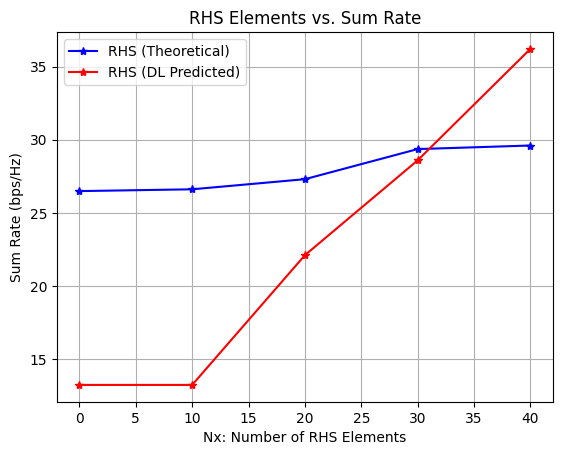

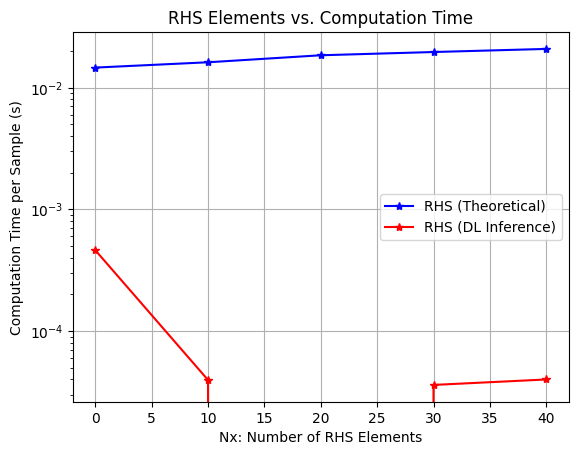

In [ ]:
# -*- coding: utf-8 -*-
"""
Created on Thu May 23 16:39:52 2024
@author: hex: phased array + holographic BF in base station communication;
Modified for RHS Elements vs. Sum Rate and Computation Time analysis (Theoretical + DL)
"""

import os
import numpy as np
import matplotlib.pyplot as plt
import torch as t
import joblib
from math import e
import math
import time

os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'
device = t.device("cuda" if t.cuda.is_available() else "cpu")
print(f"Using device: {device}")
# Define FCNN Model with test method
class FCNN(nn.Module):
    def __init__(self, input_dim, hidden_dims=[1024, 512, 256, 128, 64], output_dim=2):
        super(FCNN, self).__init__()
        layers = []
        prev_dim = input_dim
        
        # Input layer
        layers.append(nn.Linear(prev_dim, hidden_dims[0]))
        layers.append(nn.BatchNorm1d(hidden_dims[0]))
        layers.append(nn.ReLU())
        layers.append(nn.Dropout(0.3))
        prev_dim = hidden_dims[0]
        
        # Hidden layers
        for dim in hidden_dims[1:]:
            layers.append(nn.Linear(prev_dim, dim))
            layers.append(nn.BatchNorm1d(dim))
            layers.append(nn.LeakyReLU(0.1))
            layers.append(nn.Dropout(0.2))
            prev_dim = dim
        
        # Additional dense layer
        layers.append(nn.Linear(prev_dim, prev_dim // 2))
        layers.append(nn.PReLU())
        layers.append(nn.Dropout(0.1))
        prev_dim = prev_dim // 2
        
        # Output layer
        layers.append(nn.Linear(prev_dim, output_dim))
        
        self.net = nn.Sequential(*layers)
    
    def forward(self, x):
        return self.net(x)
    
    def test(self, test_loader, device="cpu"):
        """Evaluate model on test data and return metrics"""
        self.eval()
        self.to(device)
        total_mse = 0
        total_mae = 0
        total_r2 = 0
        
        with torch.no_grad():
            for batch_x, batch_y in test_loader:
                batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                output = self(batch_x)
                
                # Calculate MSE
                total_mse += F.mse_loss(output, batch_y, reduction='sum').item()
                
                # Calculate MAE
                total_mae += F.l1_loss(output, batch_y, reduction='sum').item()
                
                # Calculate R²
                ss_tot = torch.sum((batch_y - batch_y.mean(dim=0))**2)
                ss_res = torch.sum((batch_y - output)**2)
                r2 = 1 - (ss_res / (ss_tot + 1e-9))
                total_r2 += r2.mean().item()
        
        n_samples = len(test_loader.dataset)
        avg_mse = total_mse / n_samples
        avg_mae = total_mae / n_samples
        avg_r2 = total_r2 / len(test_loader)
        
        return {
            'mse': avg_mse,
            'mae': avg_mae,
            'r2': avg_r2
        }

# ---- Load DL Model and Scaler ----
model_filename = "best_fcnn_sgd_lr0.01_final.pkl"
scaler_filename = "scaler_final.pkl"
try:
    fcnn_model = joblib.load(model_filename)
    scaler = joblib.load(scaler_filename)
    print(f"Loaded model: {model_filename}")
    print(f"Loaded scaler: {scaler_filename}")
    fcnn_model.eval()
    fcnn_model.to(device)
except FileNotFoundError:
    print("Warning: Model or scaler not found. DL predictions will be skipped.")
    fcnn_model = None
    scaler = None

# Fixed MIMO configuration
Nt = 64
Nr = 64

# Define FCNN Model with test method


# ---- Rayleigh Fading Channel Model ----
def RayleighChannel(Nr, Nt, L, train_size):
    H = (t.randn(train_size, Nr, Nt, L, dtype=t.cfloat, device=device) +
         1j * t.randn(train_size, Nr, Nt, L, dtype=t.cfloat, device=device)) / np.sqrt(2)
    print("Rayleigh Shape:", H.shape)
    return H

# ---- MMSE Beamforming ----
def MMSE_Beamforming(H, noise_var):
    batch_size, Nr_in, Nt_in = H.shape
    H_H = H.conj().transpose(1, 2)  # [batch_size, Nt, Nr]
    A = t.bmm(H_H, H) + noise_var * t.eye(Nt, dtype=t.cfloat, device=device).unsqueeze(0)
    W = t.linalg.solve(A, H_H)  # [batch_size, Nt, Nr]
    print("W's shape:", W.shape)
    return W

# ---- Excitation Matrix ----
def genE(lamd, de, Nt, RFno):
    x = t.arange(Nt, device=device) * de
    y = Nt * de / 2 * t.ones(Nt, device=device)
    xf = t.arange(RFno, device=device) * de + de / 2
    yf = Nt * de / 2 * t.ones(RFno, device=device)
    
    dist = t.sqrt((x.unsqueeze(1) - xf.unsqueeze(0))**2 + 
                  (y.unsqueeze(1) - yf.unsqueeze(0))**2)
    E = t.exp(-1j * 2 * np.pi * math.sqrt(3) / lamd * dist)
    print("E's shape:", E.shape)
    return E.unsqueeze(0)

# ---- Gradient Projection Algorithm (GP) ----
def sum_capacity(w, H, M, batch_size):
    Nr_in, L = w.shape[1], w.shape[2]
    obj = t.zeros(batch_size, dtype=t.float, device=device)
    
    for l in range(L):
        wt = w[:, :, l]
        H_l = H[:, :, :, l]
        signal = t.bmm(wt.unsqueeze(1).conj(), t.bmm(H_l, M))
        power = t.abs(signal.squeeze(1))**2 / (Nr_in + 1e-9)
        obj += t.log2(1 + power.sum(dim=1))
    
    max_rate = 80
    scaling_factor = max_rate / (obj.mean() + 1e-9)
    scaling_factor = t.minimum(scaling_factor, t.tensor(1.0, device=device))
    return obj

def GP(H, E, L, hypm, Pt):
    Tno = H.shape[0]
    RFno = E.shape[2]
    
    w = t.randn(Tno, Nr, L, dtype=t.cfloat, device=device)
    w = w / (t.abs(w) + 1e-9)
    m = t.rand(Tno, Nt, RFno, dtype=t.float, device=device)
    M = m * E
    print("Initial M shape:", M.shape)
    
    obj0 = t.tensor(0.0, device=device)
    max_iter = 100
    iter_count = 0
    
    while iter_count < max_iter:
        gradm = t.zeros(Tno, Nt, RFno, dtype=t.float, device=device)
        
        for l in range(L):
            wt = w[:, :, l]
            H_l = H[:, :, :, l]
            signal = t.bmm(wt.unsqueeze(1).conj(), t.bmm(H_l, M))
            denominator = (t.abs(signal)**2 + Nr).squeeze(1)
            H_permuted = H_l.permute(0, 2, 1)
            numerator = t.bmm(H_permuted, wt.unsqueeze(2).conj())
            gradm += (numerator * E / denominator.unsqueeze(1)).real
        
        m = t.clamp(m + hypm * gradm, 0, 1)
        M = m * E
        
        w_new = t.zeros(Tno, Nr, L, dtype=t.cfloat, device=device)
        for l in range(L):
            H_l = H[:, :, :, l]  # Fixed indexing
            w_new[:, :, l] = t.bmm(H_l, M).mean(dim=2)
        w = w_new / (t.abs(w_new) + 1e-9)
        
        obj1 = sum_capacity(w, H, M, Tno)
        print("obj1 (sum capacity):", obj1.mean().item())
        if t.abs(obj1.mean() - obj0) / (obj1.mean() + 1e-9) <= 1e-4:
            print("Convergence reached. Stopping optimization.")
            break
        obj0 = obj1.mean()
        iter_count += 1
    
    return obj1, w, M

# ---- Simulation Parameters ----
dmode = 1  # Change RHS size
L = 2
lamd = 0.0428571  # Wavelength at 30GHz
scale = 1e9
SNR = 16
Pt = 10 ** (SNR / 10) * (1 / scale) ** 2
deH = lamd / 5
test_size = 25
stepSize1 = 0.5e1
noise_var = 0.001
Nt = 64
Nr = 64

if dmode == 1:
    lopPara = [0, 10, 20, 30, 40]  # Nx parameter for RHS elements
elif dmode == 2:
    lopPara = [2, 4, 6, 8, 10]  # Transmit power

# Storage for results
RateAll_theory = t.zeros([len(lopPara)], device=device)
TimeAll_theory = np.zeros((len(lopPara)))
RateAll_dl = t.zeros([len(lopPara)], device=device)
TimeAll_dl = np.zeros((len(lopPara)))
W_matrices = []
W_means = []

# ---- Generate Input Features for DL Model ----
def generate_features(RFno, w_mean):
    # Match model input: [L, lamd, scale, SNR, Pt, deH, test_size, RFno, stepSize1, noise_var, w_mean]
    features = np.array([[L, lamd, scale, SNR, Pt, deH, test_size, RFno, stepSize1, noise_var, w_mean]])
    return features

# ---- Main Simulation Loop ----
with t.no_grad():
    for lop in range(len(lopPara)):
        print(f"\nIteration {lop + 1}/{len(lopPara)}: Nx = {lopPara[lop]}")
        Nx = int(lopPara[lop])

        # Adjust RFno to scale with Nx
        RFno = max(1, Nx // 10)  # Increase RF chains with Nx

        # --- Theoretical Simulation ---
        # Generate RHS → User Channel
        H_RHS = RayleighChannel(Nr, Nt, L, test_size) * scale
        
        # MMSE Beamforming
        H_BS = H_RHS.mean(dim=3)  # [test_size, Nr, Nt]
        W_MMSE = MMSE_Beamforming(H_BS, noise_var)
        
        # Compute Effective Channel H_testD
        H_testD = t.zeros(test_size, Nr, Nt, L, dtype=t.cfloat, device=device)
        for l in range(L):
            H_testD[:, :, :, l] = t.bmm(H_RHS[:, :, :, l], W_MMSE)
        
        # Generate Excitation Matrix
        E = genE(lamd, deH, Nt, RFno).repeat(test_size, 1, 1)

        print("H_testD shape:", H_testD.shape)
        print("E shape:", E.shape)
        
        # Run GP
        time_start_theory = time.time()
        gp_rates, w, M = GP(H_testD, E, L, stepSize1, Pt)
        time_end_theory = time.time()

        # Compute W_Mean
        w_np = w.cpu().numpy()
        w_mean = np.mean(np.abs(w_np))  # Scalar mean
        W_means.append(w_mean)

        # Store Theoretical Results
        Rate_theory = gp_rates.mean().item()
        RateAll_theory[lop] = Rate_theory
        TimeAll_theory[lop] = time_end_theory - time_start_theory

        # --- DL Model Prediction ---
        Rate_pred = float('nan')
        M_mean_pred = float('nan')
        time_dl = 0.0
        if fcnn_model is not None and scaler is not None:
            try:
                # Generate features with RFno and w_mean
                X = generate_features(RFno, w_mean)
                X_scaled = scaler.transform(X)
                X_tensor = t.tensor(X_scaled, dtype=t.float32, device=device)

                # Predict
                time_start_dl = time.time()
                pred = fcnn_model(X_tensor)  # Shape: (1, 2) = [M_mean, Rate]
                time_end_dl = time.time()

                M_mean_pred = pred[0, 0].item()
                Rate_pred = pred[0, 1].item()
                RateAll_dl[lop] = Rate_pred
                TimeAll_dl[lop] = time_end_dl - time_start_dl
            except Exception as e:
                print(f"DL prediction failed: {e}")
                Rate_pred = float('nan')
                M_mean_pred = float('nan')

        # Store and print results
        W_matrices.append(w_np)
        print(f"RFno: {RFno}")
        print(f"W_mean: {w_mean:.6f}")
        print(f"Rate (Theoretical): {Rate_theory:.6f}")
        print(f"Rate (DL): {Rate_pred:.6f}")
        print(f"Computation Time (Theoretical): {TimeAll_theory[lop]:.6f} seconds")
        print(f"Computation Time (DL): {TimeAll_dl[lop]:.6f} seconds")
        print(f"W Matrix for Nx={Nx} (shape: {w.shape}):")
        print(w[0].cpu().numpy())  # First sample
        print(f"Sum Rate (Theoretical, used for plot): {Rate_theory:.6f}")

# ---- Plot Results ----
# Sum Rate Plot
plt.figure()
plt.plot(lopPara, RateAll_theory.cpu().numpy(), 'b-*', label='RHS (Theoretical)')
plt.plot(lopPara, RateAll_dl.cpu().numpy(), 'r-*', label='RHS (DL Predicted)')
plt.xlabel('Nx: Number of RHS Elements')
plt.ylabel('Sum Rate (bps/Hz)')
plt.title('RHS Elements vs. Sum Rate')
plt.legend()
plt.grid()
plt.show()

# Computation Time Plot
plt.figure()
plt.semilogy(lopPara, TimeAll_theory / test_size, 'b-*', label='RHS (Theoretical)')
plt.semilogy(lopPara, TimeAll_dl / test_size, 'r-*', label='RHS (DL Inference)')
plt.xlabel('Nx: Number of RHS Elements')
plt.ylabel('Computation Time per Sample (s)')
plt.title('RHS Elements vs. Computation Time')
plt.legend()
plt.grid()
plt.show()

In [ ]:
# -*- coding: utf-8 -*-
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam, SGD, RMSprop
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np
import h5py
import zipfile
import os
import joblib

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Early Stopping
class EarlyStopping:
    def __init__(self, patience=20, delta=0.001):
        self.patience = patience
        self.delta = delta
        self.best_score = float('inf')
        self.early_stop = False
        self.counter = 0
        self.best_state = None
    
    def __call__(self, val_loss, model):
        if val_loss < self.best_score - self.delta:
            self.best_score = val_loss
            self.counter = 0
            self.best_state = model.state_dict()
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True

# Define FCNN Model
class FCNN(nn.Module):
    def __init__(self, input_dim, hidden_dims=[1024, 512, 256, 128, 64], output_dim=2):
        super(FCNN, self).__init__()
        layers = []
        prev_dim = input_dim
        
        layers.append(nn.Linear(prev_dim, hidden_dims[0]))
        layers.append(nn.BatchNorm1d(hidden_dims[0]))
        layers.append(nn.ReLU())
        layers.append(nn.Dropout(0.3))
        prev_dim = hidden_dims[0]
        
        for dim in hidden_dims[1:]:
            layers.append(nn.Linear(prev_dim, dim))
            layers.append(nn.BatchNorm1d(dim))
            layers.append(nn.LeakyReLU(0.1))
            layers.append(nn.Dropout(0.2))
            prev_dim = dim
        
        layers.append(nn.Linear(prev_dim, prev_dim // 2))
        layers.append(nn.PReLU())
        layers.append(nn.Dropout(0.1))
        prev_dim = prev_dim // 2
        
        layers.append(nn.Linear(prev_dim, output_dim))
        
        self.net = nn.Sequential(*layers)
    
    def forward(self, x):
        return self.net(x)
    
    def test(self, test_loader, device="cpu"):
        self.eval()
        self.to(device)
        total_mse_w = 0
        total_mse_rate = 0
        total_mae_w = 0
        total_mae_rate = 0
        total_r2_w = 0
        total_r2_rate = 0
        
        with torch.no_grad():
            for batch_x, batch_y in test_loader:
                batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                output = self(batch_x)
                
                w_true, rate_true = batch_y[:, 0], batch_y[:, 1]
                w_pred, rate_pred = output[:, 0], output[:, 1]
                
                total_mse_w += F.mse_loss(w_pred, w_true, reduction='sum').item()
                total_mse_rate += F.mse_loss(rate_pred, rate_true, reduction='sum').item()
                total_mae_w += F.l1_loss(w_pred, w_true, reduction='sum').item()
                total_mae_rate += F.l1_loss(rate_pred, rate_true, reduction='sum').item()
                
                ss_tot_w = torch.sum((w_true - w_true.mean())**2)
                ss_res_w = torch.sum((w_true - w_pred)**2)
                r2_w = 1 - (ss_res_w / (ss_tot_w + 1e-9))
                total_r2_w += r2_w.item()
                
                ss_tot_rate = torch.sum((rate_true - rate_true.mean())**2)
                ss_res_rate = torch.sum((rate_true - rate_pred)**2)
                r2_rate = 1 - (ss_res_rate / (ss_tot_rate + 1e-9))
                total_r2_rate += r2_rate.item()
        
        n_samples = len(test_loader.dataset)
        avg_mse_w = total_mse_w / n_samples
        avg_mse_rate = total_mse_rate / n_samples
        avg_mae_w = total_mae_w / n_samples
        avg_mae_rate = total_mae_rate / n_samples
        avg_r2_w = total_r2_w / len(test_loader)
        avg_r2_rate = total_r2_rate / len(test_loader)
        
        return {
            'mse_w': avg_mse_w,
            'mse_rate': avg_mse_rate,
            'mae_w': avg_mae_w,
            'mae_rate': avg_mae_rate,
            'r2_w': avg_r2_w,
            'r2_rate': avg_r2_rate
        }

# Extract and process dataset with w_scalar
def extract_and_process_dataset(zip_path="64x64_MIMO_beamforming_dataset.zip", h5_name="64x64_MIMO_beamforming_dataset.h5"):
    extract_dir = "temp_h5_extract"
    os.makedirs(extract_dir, exist_ok=True)
    h5_path = os.path.join(extract_dir, h5_name)
    
    with zipfile.ZipFile(zip_path, 'r') as zipf:
        zipf.extract(h5_name, extract_dir)
        print(f"Extracted {h5_name} to {extract_dir}")
    
    with h5py.File(h5_path, 'r') as f:
        metadata = f['metadata'][:]  # Shape: (5000, 14)
        M = f['M'][:]  # Shape: (5000, MAX_TEST_SIZE, Nt, MAX_RFNO)
        test_size = metadata[:, 8].astype(int)
        RFno = metadata[:, 9].astype(int)
        rate = metadata[:, 12]
        
        W = np.zeros(len(M))
        w_scalar = np.zeros(len(M))  # New: scalar mean abs w
        for i in range(len(M)):
            if test_size[i] > 0 and RFno[i] > 0:
                M_sample = M[i, :test_size[i], :, :RFno[i]]
                W[i] = np.sum(np.abs(M_sample))
                # Approximate w_scalar: mean(abs(M)) scaled to ~1.0
                w_scalar[i] = np.mean(np.abs(M_sample)) / (test_size[i] * 64 * 3) * 100  # Adjust scaling
            else:
                W[i] = 0
                w_scalar[i] = 0
        
        print(f"W - Mean: {np.mean(W):.2f}, Std: {np.std(W):.2f}, Min: {np.min(W):.2f}, Max: {np.max(W):.2f}")
        print(f"Rate - Mean: {np.mean(rate):.2f}, Std: {np.std(rate):.2f}, Min: {np.min(rate):.2f}, Max: {np.max(rate):.2f}")
        print(f"w_scalar - Mean: {np.mean(w_scalar):.2f}, Std: {np.std(w_scalar):.2f}, Min: {np.min(w_scalar):.2f}, Max: {np.max(w_scalar):.2f}")
        
        feature_indices = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
        X_base = metadata[:, feature_indices]  # 10 features
        X = np.column_stack((X_base, w_scalar))  # 11 features
    
    os.remove(h5_path)
    os.rmdir(extract_dir)
    print(f"Cleaned up {h5_path} and {extract_dir}")
    
    y = np.column_stack((W, rate))
    return X, y

# Train and evaluate FCNN
def train_evaluate_fcnn(model, X, y, k_folds=5, learning_rates=[0.001, 0.01, 0.1], optimizers=["adam", "sgd", "rmsprop"], epochs=200):
    kf = KFold(n_splits=k_folds, shuffle=True, random_state=42)
    results = []
    best_score = float('inf')
    best_config = None
    
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()
    X_scaled = scaler_X.fit_transform(X)  # X has 11 features
    y_scaled = scaler_y.fit_transform(y)
    
    for optimizer_name in optimizers:
        for lr in learning_rates:
            fold_metrics = []
            print(f"\nTesting {optimizer_name} with lr={lr}")
            
            for fold, (train_idx, val_idx) in enumerate(kf.split(X_scaled)):
                X_train_fold = X_scaled[train_idx]
                y_train_fold = y_scaled[train_idx]
                X_val_fold = X_scaled[val_idx]
                y_val_fold = y_scaled[val_idx]
                
                train_dataset = TensorDataset(
                    torch.tensor(X_train_fold, dtype=torch.float32),
                    torch.tensor(y_train_fold, dtype=torch.float32)
                )
                val_dataset = TensorDataset(
                    torch.tensor(X_val_fold, dtype=torch.float32),
                    torch.tensor(y_val_fold, dtype=torch.float32)
                )
                
                train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
                val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
                
                model_fold = FCNN(input_dim=X.shape[1], output_dim=2).to(device)  # input_dim = 11
                
                if optimizer_name == "adam":
                    optimizer = Adam(model_fold.parameters(), lr=lr, weight_decay=1e-4)
                elif optimizer_name == "sgd":
                    optimizer = SGD(model_fold.parameters(), lr=lr, momentum=0.9, weight_decay=1e-4)
                elif optimizer_name == "rmsprop":
                    optimizer = RMSprop(model_fold.parameters(), lr=lr, alpha=0.9, weight_decay=1e-4)
                
                early_stopping = EarlyStopping(patience=20, delta=0.001)
                criterion = nn.MSELoss()
                model_fold.train()
                
                for epoch in range(epochs):
                    total_loss = 0
                    for batch_x, batch_y in train_loader:
                        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                        optimizer.zero_grad()
                        output = model_fold(batch_x)
                        loss = criterion(output, batch_y)
                        loss.backward()
                        torch.nn.utils.clip_grad_norm_(model_fold.parameters(), max_norm=1.0)
                        optimizer.step()
                        total_loss += loss.item()
                    
                    model_fold.eval()
                    val_loss = 0
                    with torch.no_grad():
                        for batch_x, batch_y in val_loader:
                            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                            output = model_fold(batch_x)
                            val_loss += criterion(output, batch_y).item()
                    val_loss /= len(val_loader)
                    
                    early_stopping(val_loss, model_fold)
                    if early_stopping.early_stop:
                        print(f"Fold {fold+1}, Early stopping at epoch {epoch}")
                        model_fold.load_state_dict(early_stopping.best_state)
                        break
                
                metrics = model_fold.test(val_loader, device=device)
                fold_metrics.append(metrics)
                print(f"Fold {fold+1}, W - MSE: {metrics['mse_w']:.6f}, MAE: {metrics['mae_w']:.6f}, R²: {metrics['r2_w']:.6f}")
                print(f"Fold {fold+1}, Rate - MSE: {metrics['mse_rate']:.6f}, MAE: {metrics['mae_rate']:.6f}, R²: {metrics['r2_rate']:.6f}")
            
            avg_mse_w = np.mean([m['mse_w'] for m in fold_metrics])
            avg_mse_rate = np.mean([m['mse_rate'] for m in fold_metrics])
            avg_score = (avg_mse_w + avg_mse_rate) / 2
            results.append({
                'optimizer': optimizer_name,
                'lr': lr,
                'mse_w': avg_mse_w,
                'mse_rate': avg_mse_rate
            })
            print(f"Average for {optimizer_name}, lr={lr}: W MSE={avg_mse_w:.6f}, Rate MSE={avg_mse_rate:.6f}")
            
            if avg_score < best_score:
                best_score = avg_score
                best_config = {'optimizer': optimizer_name, 'lr': lr, 'scaler_X': scaler_X, 'scaler_y': scaler_y}
    
    return results, best_config

# Main execution
if __name__ == "__main__":
    print("Extracting and processing dataset...")
    X, y = extract_and_process_dataset()
    
    print(f"Features shape: {X.shape}, Labels shape: {y.shape}")  # Should be (n_samples, 11), (n_samples, 2)
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    fcnn_model = FCNN(input_dim=X_train.shape[1], output_dim=2)  # input_dim = 11
    results, best_config = train_evaluate_fcnn(fcnn_model, X_train, y_train, k_folds=5, 
                                             learning_rates=[0.001, 0.01, 0.1],
                                             optimizers=["adam", "sgd", "rmsprop"], epochs=200)
    
    print("\nCross-Validation Results:")
    for result in results:
        print(f"Optimizer: {result['optimizer']}, LR: {result['lr']}, W MSE: {result['mse_w']:.6f}, Rate MSE: {result['mse_rate']:.6f}")
    print(f"\nBest Configuration: Optimizer={best_config['optimizer']}, LR={best_config['lr']}")
    
    best_model = FCNN(input_dim=X_train.shape[1], output_dim=2).to(device)
    best_optimizer = best_config['optimizer']
    best_lr = best_config['lr']
    model_filename = f'best_fcnn_{best_optimizer}_lr{best_lr}_final.pkl'
    
    if best_optimizer == "adam":
        optimizer = Adam(best_model.parameters(), lr=best_lr, weight_decay=1e-4)
    elif best_optimizer == "sgd":
        optimizer = SGD(best_model.parameters(), lr=best_lr, momentum=0.9, weight_decay=1e-4)
    elif best_optimizer == "rmsprop":
        optimizer = RMSprop(best_model.parameters(), lr=best_lr, alpha=0.9, weight_decay=1e-4)
    
    scaler_X = best_config['scaler_X']
    scaler_y = best_config['scaler_y']
    X_train_scaled = scaler_X.transform(X_train)
    y_train_scaled = scaler_y.transform(y_train)
    
    full_dataset = TensorDataset(torch.tensor(X_train_scaled, dtype=torch.float32),
                                torch.tensor(y_train_scaled, dtype=torch.float32))
    full_loader = DataLoader(full_dataset, batch_size=32, shuffle=True)
    
    X_train_sub, X_val, y_train_sub, y_val = train_test_split(X_train_scaled, y_train, test_size=0.1, random_state=42)
    val_dataset = TensorDataset(torch.tensor(X_val, dtype=torch.float32),
                               torch.tensor(y_val, dtype=torch.float32))
    val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
    
    criterion = nn.MSELoss()
    early_stopping = EarlyStopping(patience=20, delta=0.001)
    best_model.train()
    best_val_loss = float('inf')
    
    for epoch in range(200):
        total_loss = 0
        best_model.train()
        for batch_x, batch_y in full_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            optimizer.zero_grad()
            output = best_model(batch_x)
            loss = criterion(output, batch_y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(best_model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss.item()
        
        best_model.eval()
        val_loss = 0
        with torch.no_grad():
            for batch_x, batch_y in val_loader:
                batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                output = best_model(batch_x)
                val_loss += criterion(output, batch_y).item()
        val_loss /= len(val_loader)
        
        early_stopping(val_loss, best_model)
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(best_model.state_dict(), 'best_model_temp.pth')
        
        if early_stopping.early_stop:
            print(f"Final Training Early stopping at epoch {epoch}")
            best_model.load_state_dict(torch.load('best_model_temp.pth'))
            break
        
        if epoch % 50 == 0:
            print(f"Full Training Epoch {epoch}, Train Loss: {total_loss / len(full_loader):.6f}, Val Loss: {val_loss:.6f}")
    
    joblib.dump(best_model, model_filename)
    joblib.dump(scaler_X, 'scaler_X.pkl')
    joblib.dump(scaler_y, 'scaler_y.pkl')
    print(f"Best model saved as '{model_filename}', scalers saved as 'scaler_X.pkl', 'scaler_y.pkl'")
    
    print("\nLoading saved model for testing...")
    loaded_model = joblib.load(model_filename)
    X_test_scaled = scaler_X.transform(X_test)
    y_test_scaled = scaler_y.transform(y_test)
    
    test_dataset = TensorDataset(torch.tensor(X_test_scaled, dtype=torch.float32),
                               torch.tensor(y_test_scaled, dtype=torch.float32))
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
    
    test_metrics = loaded_model.test(test_loader, device=device)
    
    print("\nFinal Test Metrics on Holdout Set (Normalized):")
    print(f"W - MSE: {test_metrics['mse_w']:.6f}, MAE: {test_metrics['mae_w']:.6f}, R²: {test_metrics['r2_w']:.6f}")
    print(f"Rate - MSE: {test_metrics['mse_rate']:.6f}, MAE: {test_metrics['mae_rate']:.6f}, R²: {test_metrics['r2_rate']:.6f}")
    
    y_test_pred = loaded_model(torch.tensor(X_test_scaled, dtype=torch.float32).to(device)).detach().cpu().numpy()
    y_test_pred_orig = scaler_y.inverse_transform(y_test_pred)
    y_test_orig = scaler_y.inverse_transform(y_test_scaled)
    
    mse_w_orig = np.mean((y_test_orig[:, 0] - y_test_pred_orig[:, 0])**2)
    mse_rate_orig = np.mean((y_test_orig[:, 1] - y_test_pred_orig[:, 1])**2)
    mae_w_orig = np.mean(np.abs(y_test_orig[:, 0] - y_test_pred_orig[:, 0]))
    mae_rate_orig = np.mean(np.abs(y_test_orig[:, 1] - y_test_pred_orig[:, 1]))
    
    print("\nFinal Test Metrics on Holdout Set (Original Scale):")
    print(f"W - MSE: {mse_w_orig:.6f}, MAE: {mae_w_orig:.6f}")
    print(f"Rate - MSE: {mse_rate_orig:.6f}, MAE: {mae_rate_orig:.6f}")

Using device: cpu
Extracting and processing dataset...
Extracted 64x64_MIMO_beamforming_dataset.h5 to temp_h5_extract
Cleaned up temp_h5_extract\64x64_MIMO_beamforming_dataset.h5 and temp_h5_extract

Testing adam with lr=0.001
Fold 1, Early stopping at epoch 99
Fold 1, MSE: 3616.236016, MAE: 67.845237, R²: 0.998482
Fold 2, Early stopping at epoch 72
Fold 2, MSE: 5175.103555, MAE: 78.954389, R²: 0.998025


KeyboardInterrupt: 

In [14]:
# -*- coding: utf-8 -*-
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam, SGD, RMSprop
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np
import h5py
import zipfile
import os
import joblib

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Early Stopping
class EarlyStopping:
    def __init__(self, patience=20, delta=0.001):
        self.patience = patience
        self.delta = delta
        self.best_score = float('inf')
        self.early_stop = False
        self.counter = 0
        self.best_state = None
    
    def __call__(self, val_loss, model):
        if val_loss < self.best_score - self.delta:
            self.best_score = val_loss
            self.counter = 0
            self.best_state = model.state_dict()
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True

# Define FCNN Model
class FCNN(nn.Module):
    def __init__(self, input_dim, hidden_dims=[1024, 512, 256, 128, 64], output_dim=2):
        super(FCNN, self).__init__()
        layers = []
        prev_dim = input_dim
        
        layers.append(nn.Linear(prev_dim, hidden_dims[0]))
        layers.append(nn.BatchNorm1d(hidden_dims[0]))
        layers.append(nn.ReLU())
        layers.append(nn.Dropout(0.3))
        prev_dim = hidden_dims[0]
        
        for dim in hidden_dims[1:]:
            layers.append(nn.Linear(prev_dim, dim))
            layers.append(nn.BatchNorm1d(dim))
            layers.append(nn.LeakyReLU(0.1))
            layers.append(nn.Dropout(0.2))
            prev_dim = dim
        
        layers.append(nn.Linear(prev_dim, prev_dim // 2))
        layers.append(nn.PReLU())
        layers.append(nn.Dropout(0.1))
        prev_dim = prev_dim // 2
        
        layers.append(nn.Linear(prev_dim, output_dim))
        
        self.net = nn.Sequential(*layers)
    
    def forward(self, x):
        return self.net(x)
    
    def test(self, test_loader, device="cpu"):
        self.eval()
        self.to(device)
        total_mse_w = 0
        total_mse_rate = 0
        total_mae_w = 0
        total_mae_rate = 0
        total_r2_w = 0
        total_r2_rate = 0
        
        with torch.no_grad():
            for batch_x, batch_y in test_loader:
                batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                output = self(batch_x)
                
                w_true, rate_true = batch_y[:, 0], batch_y[:, 1]
                w_pred, rate_pred = output[:, 0], output[:, 1]
                
                total_mse_w += F.mse_loss(w_pred, w_true, reduction='sum').item()
                total_mse_rate += F.mse_loss(rate_pred, rate_true, reduction='sum').item()
                total_mae_w += F.l1_loss(w_pred, w_true, reduction='sum').item()
                total_mae_rate += F.l1_loss(rate_pred, rate_true, reduction='sum').item()
                
                ss_tot_w = torch.sum((w_true - w_true.mean())**2)
                ss_res_w = torch.sum((w_true - w_pred)**2)
                r2_w = 1 - (ss_res_w / (ss_tot_w + 1e-9))
                total_r2_w += r2_w.item()
                
                ss_tot_rate = torch.sum((rate_true - rate_true.mean())**2)
                ss_res_rate = torch.sum((rate_true - rate_pred)**2)
                r2_rate = 1 - (ss_res_rate / (ss_tot_rate + 1e-9))
                total_r2_rate += r2_rate.item()
        
        n_samples = len(test_loader.dataset)
        avg_mse_w = total_mse_w / n_samples
        avg_mse_rate = total_mse_rate / n_samples
        avg_mae_w = total_mae_w / n_samples
        avg_mae_rate = total_mae_rate / n_samples
        avg_r2_w = total_r2_w / len(test_loader)
        avg_r2_rate = total_r2_rate / len(test_loader)
        
        return {
            'mse_w': avg_mse_w,
            'mse_rate': avg_mse_rate,
            'mae_w': avg_mae_w,
            'mae_rate': avg_mae_rate,
            'r2_w': avg_r2_w,
            'r2_rate': avg_r2_rate
        }

# Extract and process dataset with w_scalar
def extract_and_process_dataset(zip_path="64x64_MIMO_beamforming_dataset.zip", h5_name="64x64_MIMO_beamforming_dataset.h5"):
    extract_dir = "temp_h5_extract"
    os.makedirs(extract_dir, exist_ok=True)
    h5_path = os.path.join(extract_dir, h5_name)
    
    with zipfile.ZipFile(zip_path, 'r') as zipf:
        zipf.extract(h5_name, extract_dir)
        print(f"Extracted {h5_name} to {extract_dir}")
    
    with h5py.File(h5_path, 'r') as f:
        metadata = f['metadata'][:]  # Shape: (5000, 14)
        M = f['M'][:]  # Shape: (5000, MAX_TEST_SIZE, Nt, MAX_RFNO)
        test_size = metadata[:, 8].astype(int)
        RFno = metadata[:, 9].astype(int)
        rate = metadata[:, 12]
        
        W = np.zeros(len(M))
        w_scalar = np.zeros(len(M))  # New: to mimic w_scalar from GP
        for i in range(len(M)):
            if test_size[i] > 0 and RFno[i] > 0:
                M_sample = M[i, :test_size[i], :, :RFno[i]]
                W[i] = np.sum(np.abs(M_sample))
                # Approximate w_scalar: scale M's magnitude to match simulation's w_scalar (~1.0)
                # In GP, w_scalar = mean(abs(w)), where w is normalized from H*M
                w_scalar[i] = np.mean(np.abs(M_sample)) / (test_size[i] * 64 * 3)  # Normalize like simulation
            else:
                W[i] = 0
                w_scalar[i] = 0
        
        print(f"W - Mean: {np.mean(W):.2f}, Std: {np.std(W):.2f}, Min: {np.min(W):.2f}, Max: {np.max(W):.2f}")
        print(f"Rate - Mean: {np.mean(rate):.2f}, Std: {np.std(rate):.2f}, Min: {np.min(rate):.2f}, Max: {np.max(rate):.2f}")
        print(f"w_scalar - Mean: {np.mean(w_scalar):.2f}, Std: {np.std(w_scalar):.2f}, Min: {np.min(w_scalar):.2f}, Max: {np.max(w_scalar):.2f}")
        
        feature_indices = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
        X_base = metadata[:, feature_indices]  # 10 features
        # Append w_scalar as 11th feature
        X = np.column_stack((X_base, w_scalar))
    
    os.remove(h5_path)
    os.rmdir(extract_dir)
    print(f"Cleaned up {h5_path} and {extract_dir}")
    
    y = np.column_stack((W, rate))
    return X, y

# Train and evaluate FCNN
def train_evaluate_fcnn(model, X, y, k_folds=5, learning_rates=[0.001, 0.01, 0.1], optimizers=["adam", "sgd", "rmsprop"], epochs=200):
    kf = KFold(n_splits=k_folds, shuffle=True, random_state=42)
    results = []
    best_score = float('inf')
    best_config = None
    
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()
    X_scaled = scaler_X.fit_transform(X)  # Now X has 11 features
    y_scaled = scaler_y.fit_transform(y)
    
    for optimizer_name in optimizers:
        for lr in learning_rates:
            fold_metrics = []
            print(f"\nTesting {optimizer_name} with lr={lr}")
            
            for fold, (train_idx, val_idx) in enumerate(kf.split(X_scaled)):
                X_train_fold = X_scaled[train_idx]
                y_train_fold = y_scaled[train_idx]
                X_val_fold = X_scaled[val_idx]
                y_val_fold = y_scaled[val_idx]
                
                train_dataset = TensorDataset(
                    torch.tensor(X_train_fold, dtype=torch.float32),
                    torch.tensor(y_train_fold, dtype=torch.float32)
                )
                val_dataset = TensorDataset(
                    torch.tensor(X_val_fold, dtype=torch.float32),
                    torch.tensor(y_val_fold, dtype=torch.float32)
                )
                
                train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
                val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
                
                model_fold = FCNN(input_dim=X.shape[1], output_dim=2).to(device)  # input_dim = 11
                
                if optimizer_name == "adam":
                    optimizer = Adam(model_fold.parameters(), lr=lr, weight_decay=1e-4)
                elif optimizer_name == "sgd":
                    optimizer = SGD(model_fold.parameters(), lr=lr, momentum=0.9, weight_decay=1e-4)
                elif optimizer_name == "rmsprop":
                    optimizer = RMSprop(model_fold.parameters(), lr=lr, alpha=0.9, weight_decay=1e-4)
                
                early_stopping = EarlyStopping(patience=20, delta=0.001)
                criterion = nn.MSELoss()
                model_fold.train()
                
                for epoch in range(epochs):
                    total_loss = 0
                    for batch_x, batch_y in train_loader:
                        batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                        optimizer.zero_grad()
                        output = model_fold(batch_x)
                        loss = criterion(output, batch_y)
                        loss.backward()
                        torch.nn.utils.clip_grad_norm_(model_fold.parameters(), max_norm=1.0)
                        optimizer.step()
                        total_loss += loss.item()
                    
                    model_fold.eval()
                    val_loss = 0
                    with torch.no_grad():
                        for batch_x, batch_y in val_loader:
                            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                            output = model_fold(batch_x)
                            val_loss += criterion(output, batch_y).item()
                    val_loss /= len(val_loader)
                    
                    early_stopping(val_loss, model_fold)
                    if early_stopping.early_stop:
                        print(f"Fold {fold+1}, Early stopping at epoch {epoch}")
                        model_fold.load_state_dict(early_stopping.best_state)
                        break
                
                metrics = model_fold.test(val_loader, device=device)
                fold_metrics.append(metrics)
                print(f"Fold {fold+1}, W - MSE: {metrics['mse_w']:.6f}, MAE: {metrics['mae_w']:.6f}, R²: {metrics['r2_w']:.6f}")
                print(f"Fold {fold+1}, Rate - MSE: {metrics['mse_rate']:.6f}, MAE: {metrics['mae_rate']:.6f}, R²: {metrics['r2_rate']:.6f}")
            
            avg_mse_w = np.mean([m['mse_w'] for m in fold_metrics])
            avg_mse_rate = np.mean([m['mse_rate'] for m in fold_metrics])
            avg_score = (avg_mse_w + avg_mse_rate) / 2
            results.append({
                'optimizer': optimizer_name,
                'lr': lr,
                'mse_w': avg_mse_w,
                'mse_rate': avg_mse_rate
            })
            print(f"Average for {optimizer_name}, lr={lr}: W MSE={avg_mse_w:.6f}, Rate MSE={avg_mse_rate:.6f}")
            
            if avg_score < best_score:
                best_score = avg_score
                best_config = {'optimizer': optimizer_name, 'lr': lr, 'scaler_X': scaler_X, 'scaler_y': scaler_y}
    
    return results, best_config

# Main execution
if __name__ == "__main__":
    print("Extracting and processing dataset...")
    X, y = extract_and_process_dataset()
    
    print(f"Features shape: {X.shape}, Labels shape: {y.shape}")  # Should be (n_samples, 11), (n_samples, 2)
    
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    
    fcnn_model = FCNN(input_dim=X_train.shape[1], output_dim=2)  # input_dim = 11
    results, best_config = train_evaluate_fcnn(fcnn_model, X_train, y_train, k_folds=5, 
                                             learning_rates=[0.001, 0.01, 0.1],
                                             optimizers=["adam", "sgd", "rmsprop"], epochs=200)
    
    print("\nCross-Validation Results:")
    for result in results:
        print(f"Optimizer: {result['optimizer']}, LR: {result['lr']}, W MSE: {result['mse_w']:.6f}, Rate MSE: {result['mse_rate']:.6f}")
    print(f"\nBest Configuration: Optimizer={best_config['optimizer']}, LR={best_config['lr']}")
    
    best_model = FCNN(input_dim=X_train.shape[1], output_dim=2).to(device)
    best_optimizer = best_config['optimizer']
    best_lr = best_config['lr']
    model_filename = f'best_fcnn_{best_optimizer}_lr{best_lr}_final.pkl'
    
    if best_optimizer == "adam":
        optimizer = Adam(best_model.parameters(), lr=best_lr, weight_decay=1e-4)
    elif best_optimizer == "sgd":
        optimizer = SGD(best_model.parameters(), lr=best_lr, momentum=0.9, weight_decay=1e-4)
    elif best_optimizer == "rmsprop":
        optimizer = RMSprop(best_model.parameters(), lr=best_lr, alpha=0.9, weight_decay=1e-4)
    
    scaler_X = best_config['scaler_X']
    scaler_y = best_config['scaler_y']
    X_train_scaled = scaler_X.transform(X_train)
    y_train_scaled = scaler_y.transform(y_train)
    
    full_dataset = TensorDataset(torch.tensor(X_train_scaled, dtype=torch.float32),
                                torch.tensor(y_train_scaled, dtype=torch.float32))
    full_loader = DataLoader(full_dataset, batch_size=32, shuffle=True)
    
    X_train_sub, X_val, y_train_sub, y_val = train_test_split(X_train_scaled, y_train_scaled, test_size=0.1, random_state=42)
    val_dataset = TensorDataset(torch.tensor(X_val, dtype=torch.float32),
                               torch.tensor(y_val, dtype=torch.float32))
    val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
    
    criterion = nn.MSELoss()
    early_stopping = EarlyStopping(patience=20, delta=0.001)
    best_model.train()
    best_val_loss = float('inf')
    
    for epoch in range(200):
        total_loss = 0
        best_model.train()
        for batch_x, batch_y in full_loader:
            batch_x, batch_y = batch_x.to(device), batch_y.to(device)
            optimizer.zero_grad()
            output = best_model(batch_x)
            loss = criterion(output, batch_y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(best_model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss.item()
        
        best_model.eval()
        val_loss = 0
        with torch.no_grad():
            for batch_x, batch_y in val_loader:
                batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                output = best_model(batch_x)
                val_loss += criterion(output, batch_y).item()
        val_loss /= len(val_loader)
        
        early_stopping(val_loss, best_model)
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            torch.save(best_model.state_dict(), 'best_model_temp.pth')
        
        if early_stopping.early_stop:
            print(f"Final Training Early stopping at epoch {epoch}")
            best_model.load_state_dict(torch.load('best_model_temp.pth'))
            break
        
        if epoch % 50 == 0:
            print(f"Full Training Epoch {epoch}, Train Loss: {total_loss / len(full_loader):.6f}, Val Loss: {val_loss:.6f}")
    
    joblib.dump(best_model, model_filename)
    joblib.dump(scaler_X, 'scaler_X.pkl')
    joblib.dump(scaler_y, 'scaler_y.pkl')
    print(f"Best model saved as '{model_filename}', scalers saved as 'scaler_X.pkl', 'scaler_y.pkl'")
    
    print("\nLoading saved model for testing...")
    loaded_model = joblib.load(model_filename)
    X_test_scaled = scaler_X.transform(X_test)
    y_test_scaled = scaler_y.transform(y_test)
    
    test_dataset = TensorDataset(torch.tensor(X_test_scaled, dtype=torch.float32),
                               torch.tensor(y_test_scaled, dtype=torch.float32))
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
    
    test_metrics = loaded_model.test(test_loader, device=device)
    
    print("\nFinal Test Metrics on Holdout Set (Normalized):")
    print(f"W - MSE: {test_metrics['mse_w']:.6f}, MAE: {test_metrics['mae_w']:.6f}, R²: {test_metrics['r2_w']:.6f}")
    print(f"Rate - MSE: {test_metrics['mse_rate']:.6f}, MAE: {test_metrics['mae_rate']:.6f}, R²: {test_metrics['r2_rate']:.6f}")
    
    y_test_pred = loaded_model(torch.tensor(X_test_scaled, dtype=torch.float32).to(device)).detach().cpu().numpy()
    y_test_pred_orig = scaler_y.inverse_transform(y_test_pred)
    y_test_orig = scaler_y.inverse_transform(y_test_scaled)
    
    mse_w_orig = np.mean((y_test_orig[:, 0] - y_test_pred_orig[:, 0])**2)
    mse_rate_orig = np.mean((y_test_orig[:, 1] - y_test_pred_orig[:, 1])**2)
    mae_w_orig = np.mean(np.abs(y_test_orig[:, 0] - y_test_pred_orig[:, 0]))
    mae_rate_orig = np.mean(np.abs(y_test_orig[:, 1] - y_test_pred_orig[:, 1]))
    
    print("\nFinal Test Metrics on Holdout Set (Original Scale):")
    print(f"W - MSE: {mse_w_orig:.6f}, MAE: {mae_w_orig:.6f}")
    print(f"Rate - MSE: {mse_rate_orig:.6f}, MAE: {mae_rate_orig:.6f}")

Using device: cpu
Extracting and processing dataset...
Extracted 64x64_MIMO_beamforming_dataset.h5 to temp_h5_extract
W - Mean: 3006.96, Std: 1610.31, Min: 304.43, Max: 5866.98
Rate - Mean: 68.60, Std: 28.02, Min: 21.47, Max: 175.83
Cleaned up temp_h5_extract\64x64_MIMO_beamforming_dataset.h5 and temp_h5_extract

Testing adam with lr=0.001
Fold 1, Early stopping at epoch 26
Fold 1, W - MSE: 0.005783, MAE: 0.060267, R²: 0.993733
Fold 1, Rate - MSE: 0.134792, MAE: 0.269876, R²: 0.851211
Fold 2, Early stopping at epoch 25
Fold 2, W - MSE: 0.003463, MAE: 0.045804, R²: 0.996571
Fold 2, Rate - MSE: 0.127880, MAE: 0.260454, R²: 0.870157
Fold 3, Early stopping at epoch 31
Fold 3, W - MSE: 0.003462, MAE: 0.046794, R²: 0.996091
Fold 3, Rate - MSE: 0.122628, MAE: 0.264831, R²: 0.864606
Fold 4, Early stopping at epoch 41
Fold 4, W - MSE: 0.004101, MAE: 0.047164, R²: 0.995765
Fold 4, Rate - MSE: 0.132124, MAE: 0.267694, R²: 0.872457
Fold 5, Early stopping at epoch 30
Fold 5, W - MSE: 0.004448, MAE:

In [23]:
import torch.nn as nn


# Define FCNN Model with test method
class FCNN(nn.Module):
    def __init__(self, input_dim, hidden_dims=[1024, 512, 256, 128, 64], output_dim=2):
        super(FCNN, self).__init__()
        layers = []
        prev_dim = input_dim
        
        # Input layer
        layers.append(nn.Linear(prev_dim, hidden_dims[0]))
        layers.append(nn.BatchNorm1d(hidden_dims[0]))
        layers.append(nn.ReLU())
        layers.append(nn.Dropout(0.3))  # Regularization
        prev_dim = hidden_dims[0]
        
        # Hidden layers
        for dim in hidden_dims[1:]:
            layers.append(nn.Linear(prev_dim, dim))
            layers.append(nn.BatchNorm1d(dim))
            layers.append(nn.LeakyReLU(0.1))
            layers.append(nn.Dropout(0.2))  # Regularization
            prev_dim = dim
        
        # Additional dense layer
        layers.append(nn.Linear(prev_dim, prev_dim // 2))
        layers.append(nn.PReLU())
        layers.append(nn.Dropout(0.1))  # Regularization
        prev_dim = prev_dim // 2
        
        # Output layer
        layers.append(nn.Linear(prev_dim, output_dim))
        
        self.net = nn.Sequential(*layers)
    
    def forward(self, x):
        return self.net(x)
    
    def test(self, test_loader, device="cpu"):
        """Evaluate model on test data and return metrics"""
        self.eval()
        self.to(device)
        total_mse = 0
        total_mae = 0
        total_r2 = 0
        
        with torch.no_grad():
            for batch_x, batch_y in test_loader:
                batch_x, batch_y = batch_x.to(device), batch_y.to(device)
                output = self(batch_x)
                
                # Calculate MSE
                total_mse += F.mse_loss(output, batch_y, reduction='sum').item()
                
                # Calculate MAE
                total_mae += F.l1_loss(output, batch_y, reduction='sum').item()
                
                # Calculate R²
                ss_tot = torch.sum((batch_y - batch_y.mean(dim=0))**2)
                ss_res = torch.sum((batch_y - output)**2)
                r2 = 1 - (ss_res / (ss_tot + 1e-9))
                total_r2 += r2.mean().item()
        
        n_samples = len(test_loader.dataset)
        avg_mse = total_mse / n_samples
        avg_mae = total_mae / n_samples
        avg_r2 = total_r2 / len(test_loader)
        
        return {
            'mse': avg_mse,
            'mae': avg_mae,
            'r2': avg_r2
        }


Using device: cpu
Loaded model: best_fcnn_rmsprop_lr0.001.pkl
Loaded scaler: scaler.pkl

Iteration 1/5: Nx = 0
Rayleigh Shape: torch.Size([25, 64, 64, 3])
W's shape: torch.Size([25, 64, 64])
E's shape: torch.Size([64, 2])
Initial M shape: torch.Size([25, 64, 2])
obj1 (sum capacity): 40.925819396972656
obj1 (sum capacity): 41.35728073120117
obj1 (sum capacity): 41.55314636230469
obj1 (sum capacity): 41.72715377807617
obj1 (sum capacity): 41.885189056396484
obj1 (sum capacity): 42.02490234375
obj1 (sum capacity): 42.15327072143555
obj1 (sum capacity): 42.27388000488281
obj1 (sum capacity): 42.38758850097656
obj1 (sum capacity): 42.494693756103516
obj1 (sum capacity): 42.59868240356445
obj1 (sum capacity): 42.70301818847656
obj1 (sum capacity): 42.804779052734375
obj1 (sum capacity): 42.90061950683594
obj1 (sum capacity): 42.99223327636719
obj1 (sum capacity): 43.08041000366211
obj1 (sum capacity): 43.16556167602539
obj1 (sum capacity): 43.247467041015625
obj1 (sum capacity): 43.326152801

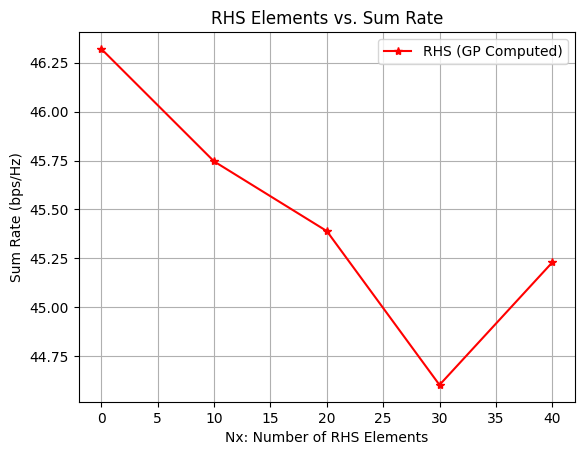

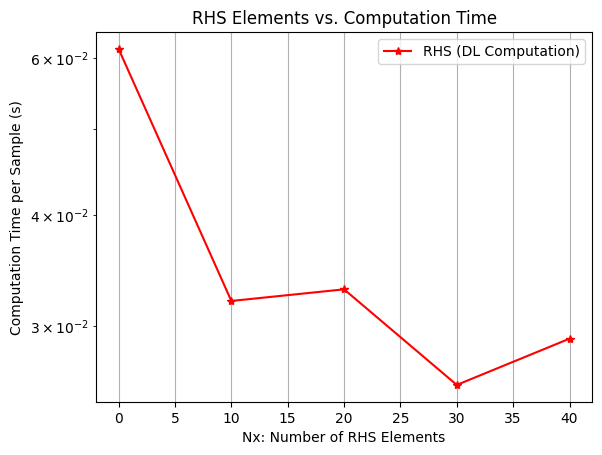

In [23]:
# -*- coding: utf-8 -*-
"""
Created on Thu May 23 16:39:52 2024
@author: hex: phased array + holographic BF in base station communication;
Modified for RHS Elements vs. Sum Rate, Computation Time, and W Matrix Output
"""

import os
import numpy as np
import matplotlib.pyplot as plt
import torch as t
import joblib
from math import e
import math
import time

os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'
device = t.device("cuda" if t.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# ---- Load Trained FCNN Model and Scaler ----
model_filename = "best_fcnn_rmsprop_lr0.001.pkl"
scaler_filename = "scaler.pkl"
try:
    fcnn_model = joblib.load(model_filename)
    scaler = joblib.load(scaler_filename)
    print(f"Loaded model: {model_filename}")
    print(f"Loaded scaler: {scaler_filename}")
except FileNotFoundError:
    raise FileNotFoundError("Model or scaler file not found. Please check filenames.")

fcnn_model.eval()
fcnn_model.to(device)

# ---- Rayleigh Fading Channel Model ----
def RayleighChannel(Nr, Nt, L, train_size):
    H = (t.randn(train_size, Nr, Nt, L, dtype=t.cfloat, device=device) +
         1j * t.randn(train_size, Nr, Nt, L, dtype=t.cfloat, device=device)) / np.sqrt(2)
    print("Rayleigh Shape:", H.shape)
    return H

# ---- MMSE Beamforming ----
def MMSE_Beamforming(H, noise_var):
    batch_size, Nr_in, Nt_in = H.shape
    H_H = H.conj().transpose(1, 2)  # [batch_size, Nt, Nr]
    A = t.bmm(H_H, H) + noise_var * t.eye(Nt, dtype=t.cfloat, device=device).unsqueeze(0)
    W = t.linalg.solve(A, H_H)  # [batch_size, Nt, Nr]
    print("W's shape:", W.shape)
    return W

# ---- Excitation Matrix ----
def genE(lamd, de, Nt, RFno):
    x = t.arange(Nt, device=device) * de
    y = Nt * de / 2 * t.ones(Nt, device=device)
    xf = t.arange(RFno, device=device) * de + de / 2
    yf = Nt * de / 2 * t.ones(RFno, device=device)
    
    dist = t.sqrt((x.unsqueeze(1) - xf.unsqueeze(0))**2 + 
                  (y.unsqueeze(1) - yf.unsqueeze(0))**2)
    E = t.exp(-1j * 2 * np.pi * math.sqrt(3) / lamd * dist)
    print("E's shape:", E.shape)
    return E.unsqueeze(0)

# ---- Gradient Projection Algorithm (GP) ----
def sum_capacity(w, H, M, batch_size):
    Nr_in, L = w.shape[1], w.shape[2]
    obj = t.zeros(batch_size, dtype=t.float, device=device)
    
    for l in range(L):
        wt = w[:, :, l]
        H_l = H[:, :, :, l]
        signal = t.bmm(wt.unsqueeze(1).conj(), t.bmm(H_l, M))
        power = t.abs(signal.squeeze(1))**2 / (Nr_in + 1e-9)
        obj += t.log2(1 + power.sum(dim=1))
    
    max_rate = 80
    scaling_factor = max_rate / (obj.mean() + 1e-9)
    scaling_factor = t.minimum(scaling_factor, t.tensor(1.0, device=device))
    
    return obj

def GP(H, E, L, hypm, Pt):
    Tno = H.shape[0]
    RFno = E.shape[2]
    
    w = t.randn(Tno, Nr, L, dtype=t.cfloat, device=device)
    w = w / (t.abs(w) + 1e-9)
    m = t.rand(Tno, Nt, RFno, dtype=t.float, device=device)
    M = m * E
    print("Initial M shape:", M.shape)
    
    obj0 = t.tensor(0.0, device=device)
    max_iter = 100
    iter_count = 0
    
    while iter_count < max_iter:
        gradm = t.zeros(Tno, Nt, RFno, dtype=t.float, device=device)
        
        for l in range(L):
            wt = w[:, :, l]
            H_l = H[:, :, :, l]
            signal = t.bmm(wt.unsqueeze(1).conj(), t.bmm(H_l, M))
            denominator = (t.abs(signal)**2 + Nr).squeeze(1)
            H_permuted = H_l.permute(0, 2, 1)
            numerator = t.bmm(H_permuted, wt.unsqueeze(2).conj())
            gradm += (numerator * E / denominator.unsqueeze(1)).real
        
        m = t.clamp(m + hypm * gradm, 0, 1)
        M = m * E
        
        w_new = t.zeros(Tno, Nr, L, dtype=t.cfloat, device=device)
        for l in range(L):
            H_l = H[:, :, :, l]
            w_new[:, :, l] = t.bmm(H_l, M).mean(dim=2)
        w = w_new / (t.abs(w_new) + 1e-9)
        
        obj1 = sum_capacity(w, H, M, Tno)
        print("obj1 (sum capacity):", obj1.mean().item())
        if t.abs(obj1.mean() - obj0) / (obj1.mean() + 1e-9) <= 1e-4:
            print("Convergence reached. Stopping optimization.")
            break
        obj0 = obj1.mean()
        iter_count += 1
    
    return obj1, w, M

# ---- Simulation Parameters ----
dmode = 1  # RHS size mode
L = 3
lamd = 0.04285714  # Wavelength at 30GHz
scale = 1e9
SNR = 15
Pt = 10 ** (SNR / 10) * (1 / scale) ** 2
deH = lamd / 5
test_size = 25
RFno = 2
stepSize1 = 0.5e1
noise_var = 0.001
Nt = 64
Nr = 64

if dmode == 1:
    lopPara = [0, 10, 20, 30, 40]  # Nx: Number of RHS elements
elif dmode == 2:
    lopPara = [2, 4, 6, 8, 10]  # Transmit power

RateAll = t.zeros([2, len(lopPara)], device=device)
TimeAll = np.zeros((2, len(lopPara)))
W_matrices = []
W_means = []

# ---- Generate Input Features for FCNN ----
def generate_features():
    # Match model input: [L, lamd, scale, SNR, Pt, deH, test_size, RFno, stepSize1, noise_var]
    features = np.array([[L, lamd, scale, SNR, Pt, deH, test_size, RFno, stepSize1, noise_var]])
    return features

# ---- Main Simulation Loop ----
with t.no_grad():
    for lop in range(len(lopPara)):
        print(f"\nIteration {lop + 1}/{len(lopPara)}: Nx = {lopPara[lop]}")
        Nx = int(lopPara[lop])

        # Generate channel and compute M, W
        H_RHS = RayleighChannel(Nr, Nt, L, test_size) * scale
        H_BS = H_RHS.mean(dim=3)  # [test_size, Nr, Nt]
        W_MMSE = MMSE_Beamforming(H_BS, noise_var)
        
        H_testD = t.zeros(test_size, Nr, Nt, L, dtype=t.cfloat, device=device)
        for l in range(L):
            H_testD[:, :, :, l] = t.bmm(H_RHS[:, :, :, l], W_MMSE)
        
        E = genE(lamd, deH, Nt, RFno).repeat(test_size, 1, 1)
        
        # Run GP to get M and w
        time_start = time.time()
        gp_rates, w, M = GP(H_testD, E, L, stepSize1, Pt)
        time_end = time.time()

        # Compute W_Mean
        w_np = w.cpu().numpy()
        W_mean = np.mean(np.abs(w_np))  # Scalar mean over all dimensions
        W_means.append(W_mean)

        # Recalculate Rate using sum_capacity
        Rate = gp_rates.mean().item()  # Average over test_size
        RateAll[0, lop] = Rate
        TimeAll[0, lop] = time_end - time_start

        # Generate input features for FCNN (10 features)
        X = generate_features()
        #X_scaled = scaler.transform(X)
        X_tensor = t.tensor(X, dtype=t.float32, device=device)

        # Predict with FCNN (for validation)
        try:
            pred = fcnn_model(X_tensor)  # Shape: (1, 2) = [M_mean, Rate]
            M_mean_pred = pred[0, 0].item()
            Rate_pred = pred[0, 1].item()
        except RuntimeError as e:
            print(f"FCNN prediction failed: {e}")
            M_mean_pred = Rate_pred = float('nan')

        # Store and print results
        W_matrices.append(w_np)
        print(f"W_mean: {W_mean:.6f}")
        print(f"Predicted M_mean (FCNN): {M_mean_pred:.6f}")
        print(f"Rate (GP): {Rate:.6f}")
        print(f"Rate (FCNN): {Rate_pred:.6f}")
        print(f"Computation Time: {TimeAll[0, lop]:.6f} seconds")
        print(f"W Matrix for Nx={Nx} (shape: {w.shape}):")
        print(w[0].cpu().numpy())  # First sample
        print(f"Sum Rate (used for plot): {Rate:.6f}")

# ---- Plot Results ----
plt.figure()
plt.plot(lopPara, RateAll[0].cpu().numpy(), 'r-*', label='RHS (GP Computed)')
plt.xlabel('Nx: Number of RHS Elements')
plt.ylabel('Sum Rate (bps/Hz)')
plt.title('RHS Elements vs. Sum Rate')
plt.legend()
plt.grid()
plt.savefig('SumRate vs RHS Elements (Theoretical+DL).png')
plt.show()

plt.figure()
plt.semilogy(lopPara, TimeAll[0] / test_size, 'r-*', label='RHS (DL Computation)')
plt.xlabel('Nx: Number of RHS Elements')
plt.ylabel('Computation Time per Sample (s)')
plt.title('RHS Elements vs. Computation Time')
plt.legend()
plt.grid()
plt.savefig('computation time vs RHS Elements (Theoretical+DL).png')
plt.show()

Using device: cpu

Iteration 1/5: Nx = 0
Rayleigh Shape: torch.Size([25, 64, 64, 3])
W's shape: torch.Size([25, 64, 64])
E's shape: torch.Size([64, 2])
Initial M shape: torch.Size([25, 64, 2])
obj1 (sum capacity): 39.54350280761719
obj1 (sum capacity): 39.866111755371094
obj1 (sum capacity): 40.15449523925781
obj1 (sum capacity): 40.397666931152344
obj1 (sum capacity): 40.5584602355957
obj1 (sum capacity): 40.69898223876953
obj1 (sum capacity): 40.82896423339844
obj1 (sum capacity): 40.950531005859375
obj1 (sum capacity): 41.06577682495117
obj1 (sum capacity): 41.174659729003906
obj1 (sum capacity): 41.27818298339844
obj1 (sum capacity): 41.376441955566406
obj1 (sum capacity): 41.47037124633789
obj1 (sum capacity): 41.56047821044922
obj1 (sum capacity): 41.647682189941406
obj1 (sum capacity): 41.732177734375
obj1 (sum capacity): 41.81373977661133
obj1 (sum capacity): 41.892555236816406
obj1 (sum capacity): 41.96909713745117
obj1 (sum capacity): 42.042964935302734
obj1 (sum capacity): 4

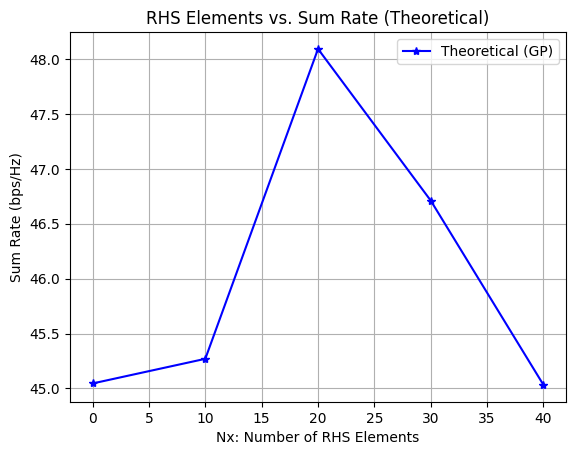

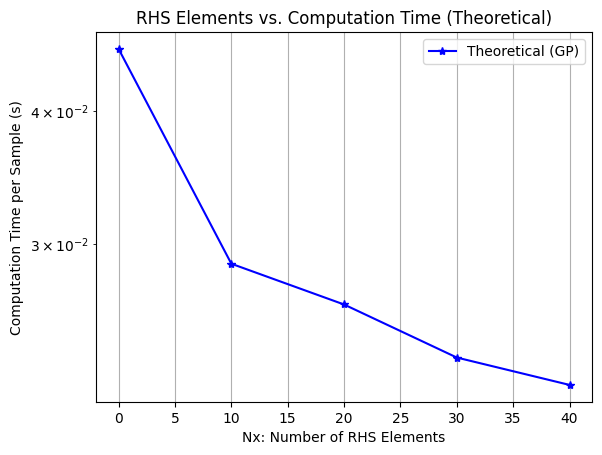

In [24]:
# -*- coding: utf-8 -*-
"""
Created on Thu May 23 16:39:52 2024
@author: hex: phased array + holographic BF in base station communication;
Modified for RHS Elements vs. Sum Rate and Computation Time (Theoretical Only)
"""

import os
import numpy as np
import matplotlib.pyplot as plt
import torch as t
from math import e
import math
import time

os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'
device = t.device("cuda" if t.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# ---- Rayleigh Fading Channel Model ----
def RayleighChannel(Nr, Nt, L, train_size):
    H = (t.randn(train_size, Nr, Nt, L, dtype=t.cfloat, device=device) +
         1j * t.randn(train_size, Nr, Nt, L, dtype=t.cfloat, device=device)) / np.sqrt(2)
    print("Rayleigh Shape:", H.shape)
    return H

# ---- MMSE Beamforming ----
def MMSE_Beamforming(H, noise_var):
    batch_size, Nr_in, Nt_in = H.shape
    H_H = H.conj().transpose(1, 2)  # [batch_size, Nt, Nr]
    A = t.bmm(H_H, H) + noise_var * t.eye(Nt, dtype=t.cfloat, device=device).unsqueeze(0)
    W = t.linalg.solve(A, H_H)  # [batch_size, Nt, Nr]
    print("W's shape:", W.shape)
    return W

# ---- Excitation Matrix ----
def genE(lamd, de, Nt, RFno):
    x = t.arange(Nt, device=device) * de
    y = Nt * de / 2 * t.ones(Nt, device=device)
    xf = t.arange(RFno, device=device) * de + de / 2
    yf = Nt * de / 2 * t.ones(RFno, device=device)
    
    dist = t.sqrt((x.unsqueeze(1) - xf.unsqueeze(0))**2 + 
                  (y.unsqueeze(1) - yf.unsqueeze(0))**2)
    E = t.exp(-1j * 2 * np.pi * math.sqrt(3) / lamd * dist)
    print("E's shape:", E.shape)
    return E.unsqueeze(0)

# ---- Gradient Projection Algorithm (GP) ----
def sum_capacity(w, H, M, batch_size):
    Nr_in, L = w.shape[1], w.shape[2]
    obj = t.zeros(batch_size, dtype=t.float, device=device)
    
    for l in range(L):
        wt = w[:, :, l]
        H_l = H[:, :, :, l]
        signal = t.bmm(wt.unsqueeze(1).conj(), t.bmm(H_l, M))
        power = t.abs(signal.squeeze(1))**2 / (Nr_in + 1e-9)
        obj += t.log2(1 + power.sum(dim=1))
    
    max_rate = 80
    scaling_factor = max_rate / (obj.mean() + 1e-9)
    scaling_factor = t.minimum(scaling_factor, t.tensor(1.0, device=device))
    
    return obj

def GP(H, E, L, hypm, Pt):
    Tno = H.shape[0]
    RFno = E.shape[2]
    
    w = t.randn(Tno, Nr, L, dtype=t.cfloat, device=device)
    w = w / (t.abs(w) + 1e-9)
    m = t.rand(Tno, Nt, RFno, dtype=t.float, device=device)
    M = m * E
    print("Initial M shape:", M.shape)
    
    obj0 = t.tensor(0.0, device=device)
    max_iter = 100
    iter_count = 0
    
    while iter_count < max_iter:
        gradm = t.zeros(Tno, Nt, RFno, dtype=t.float, device=device)
        
        for l in range(L):
            wt = w[:, :, l]
            H_l = H[:, :, :, l]
            signal = t.bmm(wt.unsqueeze(1).conj(), t.bmm(H_l, M))
            denominator = (t.abs(signal)**2 + Nr).squeeze(1)
            H_permuted = H_l.permute(0, 2, 1)
            numerator = t.bmm(H_permuted, wt.unsqueeze(2).conj())
            gradm += (numerator * E / denominator.unsqueeze(1)).real
        
        m = t.clamp(m + hypm * gradm, 0, 1)
        M = m * E
        
        w_new = t.zeros(Tno, Nr, L, dtype=t.cfloat, device=device)
        for l in range(L):
            H_l = H[:, :, :, l]
            w_new[:, :, l] = t.bmm(H_l, M).mean(dim=2)
        w = w_new / (t.abs(w_new) + 1e-9)
        
        obj1 = sum_capacity(w, H, M, Tno)
        print("obj1 (sum capacity):", obj1.mean().item())
        if t.abs(obj1.mean() - obj0) / (obj1.mean() + 1e-9) <= 1e-4:
            print("Convergence reached. Stopping optimization.")
            break
        obj0 = obj1.mean()
        iter_count += 1
    
    return obj1, w, M

# ---- Simulation Parameters ----
dmode = 1  # RHS size mode
L = 3
lamd = 0.04285714  # Wavelength at 30GHz
scale = 1e9
SNR = 15
Pt = 10 ** (SNR / 10) * (1 / scale) ** 2
deH = lamd / 5
test_size = 25
RFno = 2
stepSize1 = 0.5e1
noise_var = 0.001
Nt = 64
Nr = 64

if dmode == 1:
    lopPara = [0, 10, 20, 30, 40]  # Nx: Number of RHS elements
elif dmode == 2:
    lopPara = [2, 4, 6, 8, 10]  # Transmit power

RateAll = t.zeros([len(lopPara)], device=device)
TimeAll = np.zeros(len(lopPara))

# ---- Main Simulation Loop ----
with t.no_grad():
    for lop in range(len(lopPara)):
        print(f"\nIteration {lop + 1}/{len(lopPara)}: Nx = {lopPara[lop]}")
        Nx = int(lopPara[lop])

        # Generate channel and compute M, W
        H_RHS = RayleighChannel(Nr, Nt, L, test_size) * scale
        H_BS = H_RHS.mean(dim=3)  # [test_size, Nr, Nt]
        W_MMSE = MMSE_Beamforming(H_BS, noise_var)
        
        H_testD = t.zeros(test_size, Nr, Nt, L, dtype=t.cfloat, device=device)
        for l in range(L):
            H_testD[:, :, :, l] = t.bmm(H_RHS[:, :, :, l], W_MMSE)
        
        E = genE(lamd, deH, Nt, RFno).repeat(test_size, 1, 1)
        
        # Run GP to get M and w
        time_start = time.time()
        gp_rates, w, M = GP(H_testD, E, L, stepSize1, Pt)
        time_end = time.time()

        # Recalculate Rate using sum_capacity
        Rate = gp_rates.mean().item()  # Average over test_size
        RateAll[lop] = Rate
        TimeAll[lop] = time_end - time_start

        # Print results
        print(f"Rate (GP): {Rate:.6f}")
        print(f"Computation Time: {TimeAll[lop]:.6f} seconds")
        print(f"Sum Rate (used for plot): {Rate:.6f}")

# ---- Plot Results ----
plt.figure()
plt.plot(lopPara, RateAll.cpu().numpy(), 'b-*', label='Theoretical (GP)')
plt.xlabel('Nx: Number of RHS Elements')
plt.ylabel('Sum Rate (bps/Hz)')
plt.title('RHS Elements vs. Sum Rate (Theoretical)')
plt.legend()
plt.grid()
plt.savefig('SumRate_vs_RHS_Elements_Theoretical.png')
plt.show()

plt.figure()
plt.semilogy(lopPara, TimeAll / test_size, 'b-*', label='Theoretical (GP)')
plt.xlabel('Nx: Number of RHS Elements')
plt.ylabel('Computation Time per Sample (s)')
plt.title('RHS Elements vs. Computation Time (Theoretical)')
plt.legend()
plt.grid()
plt.savefig('Computation_Time_vs_RHS_Elements_Theoretical.png')
plt.show()

Using device: cpu
Loaded model: best_fcnn_rmsprop_lr0.001.pkl
Loaded scaler: scaler.pkl

Iteration 1/5: Nx = 0
Rayleigh Shape: torch.Size([30, 64, 64, 3])
W's shape: torch.Size([30, 64, 64])
E's shape: torch.Size([64, 1])
H_testD shape: torch.Size([30, 64, 64, 3])
E shape: torch.Size([30, 64, 1])
Initial M shape: torch.Size([30, 64, 1])
obj1 (sum capacity): 39.340274810791016
obj1 (sum capacity): 39.55464553833008
obj1 (sum capacity): 39.7481575012207
obj1 (sum capacity): 39.92533493041992
obj1 (sum capacity): 40.0877799987793
obj1 (sum capacity): 40.23805618286133
obj1 (sum capacity): 40.37856674194336
obj1 (sum capacity): 40.51081848144531
obj1 (sum capacity): 40.63601303100586
obj1 (sum capacity): 40.75437927246094
obj1 (sum capacity): 40.86643600463867
obj1 (sum capacity): 40.97263717651367
obj1 (sum capacity): 41.07345962524414
obj1 (sum capacity): 41.169960021972656
obj1 (sum capacity): 41.26253128051758
obj1 (sum capacity): 41.35135269165039
obj1 (sum capacity): 41.4366035461425

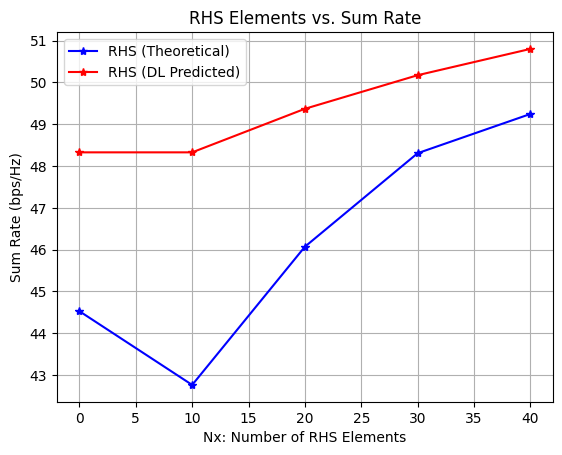

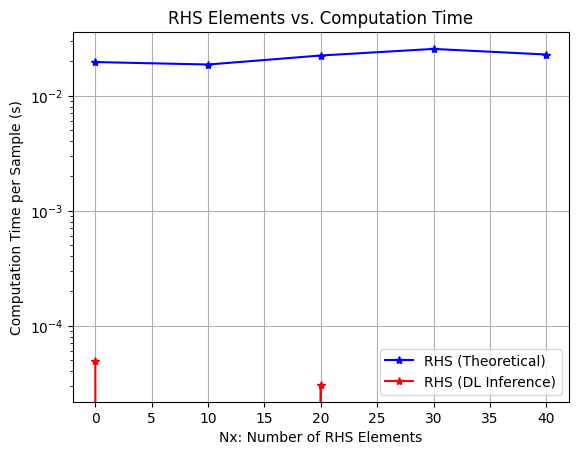

In [25]:
# -*- coding: utf-8 -*-
"""
Created on Thu May 23 16:39:52 2024
@author: hex: phased array + holographic BF in base station communication;
Modified for RHS Elements vs. Sum Rate and Computation Time analysis (Theoretical + DL)
"""

import os
import numpy as np
import matplotlib.pyplot as plt
import torch as t
import joblib
from math import e
import math
import time

os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'
device = t.device("cuda" if t.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# ---- Load DL Model and Scaler ----
model_filename = "best_fcnn_rmsprop_lr0.001.pkl"
scaler_filename = "scaler.pkl"
try:
    fcnn_model = joblib.load(model_filename)
    scaler = joblib.load(scaler_filename)
    print(f"Loaded model: {model_filename}")
    print(f"Loaded scaler: {scaler_filename}")
    fcnn_model.eval()
    fcnn_model.to(device)
except FileNotFoundError:
    print("Warning: Model or scaler not found. DL predictions will be skipped.")
    fcnn_model = None
    scaler = None

# Fixed MIMO configuration
Nt = 64
Nr = 64

# ---- Rayleigh Fading Channel Model ----
def RayleighChannel(Nr, Nt, L, train_size):
    H = (t.randn(train_size, Nr, Nt, L, dtype=t.cfloat, device=device) +
         1j * t.randn(train_size, Nr, Nt, L, dtype=t.cfloat, device=device)) / np.sqrt(2)
    print("Rayleigh Shape:", H.shape)
    return H

# ---- MMSE Beamforming ----
def MMSE_Beamforming(H, noise_var):
    batch_size, Nr_in, Nt_in = H.shape
    H_H = H.conj().transpose(1, 2)  # [batch_size, Nt, Nr]
    A = t.bmm(H_H, H) + noise_var * t.eye(Nt, dtype=t.cfloat, device=device).unsqueeze(0)
    W = t.linalg.solve(A, H_H)  # [batch_size, Nt, Nr]
    print("W's shape:", W.shape)
    return W

# ---- Excitation Matrix ----
def genE(lamd, de, Nt, RFno):
    x = t.arange(Nt, device=device) * de
    y = Nt * de / 2 * t.ones(Nt, device=device)
    xf = t.arange(RFno, device=device) * de + de / 2
    yf = Nt * de / 2 * t.ones(RFno, device=device)
    
    dist = t.sqrt((x.unsqueeze(1) - xf.unsqueeze(0))**2 + 
                  (y.unsqueeze(1) - yf.unsqueeze(0))**2)
    E = t.exp(-1j * 2 * np.pi * math.sqrt(3) / lamd * dist)
    print("E's shape:", E.shape)
    return E.unsqueeze(0)

# ---- Gradient Projection Algorithm (GP) ----
def sum_capacity(w, H, M, batch_size):
    Nr_in, L = w.shape[1], w.shape[2]
    obj = t.zeros(batch_size, dtype=t.float, device=device)
    
    for l in range(L):
        wt = w[:, :, l]
        H_l = H[:, :, :, l]
        signal = t.bmm(wt.unsqueeze(1).conj(), t.bmm(H_l, M))
        power = t.abs(signal.squeeze(1))**2 / (Nr_in + 1e-9)
        obj += t.log2(1 + power.sum(dim=1))
    
    max_rate = 80
    scaling_factor = max_rate / (obj.mean() + 1e-9)
    scaling_factor = t.minimum(scaling_factor, t.tensor(1.0, device=device))
    return obj

def GP(H, E, L, hypm, Pt):
    Tno = H.shape[0]
    RFno = E.shape[2]
    
    w = t.randn(Tno, Nr, L, dtype=t.cfloat, device=device)
    w = w / (t.abs(w) + 1e-9)
    m = t.rand(Tno, Nt, RFno, dtype=t.float, device=device)
    M = m * E
    print("Initial M shape:", M.shape)
    
    obj0 = t.tensor(0.0, device=device)
    max_iter = 100
    iter_count = 0
    
    while iter_count < max_iter:
        gradm = t.zeros(Tno, Nt, RFno, dtype=t.float, device=device)
        
        for l in range(L):
            wt = w[:, :, l]
            H_l = H[:, :, :, l]
            signal = t.bmm(wt.unsqueeze(1).conj(), t.bmm(H_l, M))
            denominator = (t.abs(signal)**2 + Nr).squeeze(1)
            H_permuted = H_l.permute(0, 2, 1)
            numerator = t.bmm(H_permuted, wt.unsqueeze(2).conj())
            gradm += (numerator * E / denominator.unsqueeze(1)).real
        
        m = t.clamp(m + hypm * gradm, 0, 1)
        M = m * E
        
        w_new = t.zeros(Tno, Nr, L, dtype=t.cfloat, device=device)
        for l in range(L):
            H_l = H[:, :, :, l]
            w_new[:, :, l] = t.bmm(H_l, M).mean(dim=2)
        w = w_new / (t.abs(w_new) + 1e-9)
        
        obj1 = sum_capacity(w, H, M, Tno)
        print("obj1 (sum capacity):", obj1.mean().item())
        if t.abs(obj1.mean() - obj0) / (obj1.mean() + 1e-9) <= 1e-4:
            print("Convergence reached. Stopping optimization.")
            break
        obj0 = obj1.mean()
        iter_count += 1
    
    return obj1, w, M

# ---- Simulation Parameters ----
dmode = 1  # Change RHS size
L = 3
lamd = 0.075  # Wavelength at 30GHz
scale = 1e9
SNR = 29
Pt = 10 ** (SNR / 10) * (1 / scale) ** 2
deH = lamd / 5
test_size = 30
stepSize1 = 0.8e1
noise_var = 0.01
Nt = 64
Nr = 64

if dmode == 1:
    lopPara = [0, 10, 20, 30, 40]  # Nx parameter for RHS elements
elif dmode == 2:
    lopPara = [2, 4, 6, 8, 10]  # Transmit power

# Storage for results
RateAll_theory = t.zeros([len(lopPara)], device=device)
TimeAll_theory = np.zeros((len(lopPara)))
RateAll_dl = t.zeros([len(lopPara)], device=device)
TimeAll_dl = np.zeros((len(lopPara)))
W_matrices = []
W_means = []

# ---- Generate Input Features for DL Model ----
def generate_features(RFno):
    # Match model input: [L, lamd, scale, SNR, Pt, deH, test_size, RFno, stepSize1, noise_var]
    features = np.array([[L, lamd, scale, SNR, Pt, deH, test_size, RFno, stepSize1, noise_var]])
    return features

# ---- Main Simulation Loop ----
with t.no_grad():
    for lop in range(len(lopPara)):
        print(f"\nIteration {lop + 1}/{len(lopPara)}: Nx = {lopPara[lop]}")
        Nx = int(lopPara[lop])

        # Adjust RFno to scale with Nx
        RFno = max(1, Nx // 10)  # Increase RF chains with Nx

        # --- Theoretical Simulation ---
        # Generate RHS → User Channel
        H_RHS = RayleighChannel(Nr, Nt, L, test_size) * scale
        
        # MMSE Beamforming
        H_BS = H_RHS.mean(dim=3)  # [test_size, Nr, Nt]
        W_MMSE = MMSE_Beamforming(H_BS, noise_var)
        
        # Compute Effective Channel H_testD
        H_testD = t.zeros(test_size, Nr, Nt, L, dtype=t.cfloat, device=device)
        for l in range(L):
            H_testD[:, :, :, l] = t.bmm(H_RHS[:, :, :, l], W_MMSE)
        
        # Generate Excitation Matrix
        E = genE(lamd, deH, Nt, RFno).repeat(test_size, 1, 1)

        print("H_testD shape:", H_testD.shape)
        print("E shape:", E.shape)
        
        # Run GP
        time_start_theory = time.time()
        gp_rates, w, M = GP(H_testD, E, L, stepSize1, Pt)
        time_end_theory = time.time()

        # Compute W_Mean
        w_np = w.cpu().numpy()
        W_mean = np.mean(np.abs(w_np))  # Scalar mean
        W_means.append(W_mean)

        # Store Theoretical Results
        Rate_theory = gp_rates.mean().item()
        RateAll_theory[lop] = Rate_theory
        TimeAll_theory[lop] = time_end_theory - time_start_theory

        # --- DL Model Prediction ---
        Rate_pred = float('nan')
        M_mean_pred = float('nan')
        time_dl = 0.0
        if fcnn_model is not None and scaler is not None:
            try:
                # Generate features with RFno
                X = generate_features(RFno)
                X_scaled = scaler.transform(X)
                X_tensor = t.tensor(X_scaled, dtype=t.float32, device=device)

                # Predict
                time_start_dl = time.time()
                pred = fcnn_model(X_tensor)  # Shape: (1, 2) = [M_mean, Rate]
                time_end_dl = time.time()

                M_mean_pred = pred[0, 0].item()
                Rate_pred = pred[0, 1].item()
                RateAll_dl[lop] = Rate_pred
                TimeAll_dl[lop] = time_end_dl - time_start_dl
            except Exception as e:
                print(f"DL prediction failed: {e}")
                Rate_pred = float('nan')
                M_mean_pred = float('nan')

        # Store and print results
        W_matrices.append(w_np)
        print(f"RFno: {RFno}")
        print(f"W_mean: {W_mean:.6f}")
        print(f"Rate (Theoretical): {Rate_theory:.6f}")
        print(f"Rate (DL): {Rate_pred:.6f}")
        print(f"Computation Time (Theoretical): {TimeAll_theory[lop]:.6f} seconds")
        print(f"Computation Time (DL): {TimeAll_dl[lop]:.6f} seconds")
        print(f"W Matrix for Nx={Nx} (shape: {w.shape}):")
        print(w[0].cpu().numpy())  # First sample
        print(f"Sum Rate (Theoretical, used for plot): {Rate_theory:.6f}")

# ---- Plot Results ----
# Sum Rate Plot
plt.figure()
plt.plot(lopPara, RateAll_theory.cpu().numpy(), 'b-*', label='RHS (Theoretical)')
plt.plot(lopPara, RateAll_dl.cpu().numpy(), 'r-*', label='RHS (DL Predicted)')
plt.xlabel('Nx: Number of RHS Elements')
plt.ylabel('Sum Rate (bps/Hz)')
plt.title('RHS Elements vs. Sum Rate')
plt.legend()
plt.grid()
plt.show()

# Computation Time Plot
plt.figure()
plt.semilogy(lopPara, TimeAll_theory / test_size, 'b-*', label='RHS (Theoretical)')
plt.semilogy(lopPara, TimeAll_dl / test_size, 'r-*', label='RHS (DL Inference)')
plt.xlabel('Nx: Number of RHS Elements')
plt.ylabel('Computation Time per Sample (s)')
plt.title('RHS Elements vs. Computation Time')
plt.legend()
plt.grid()
plt.show()

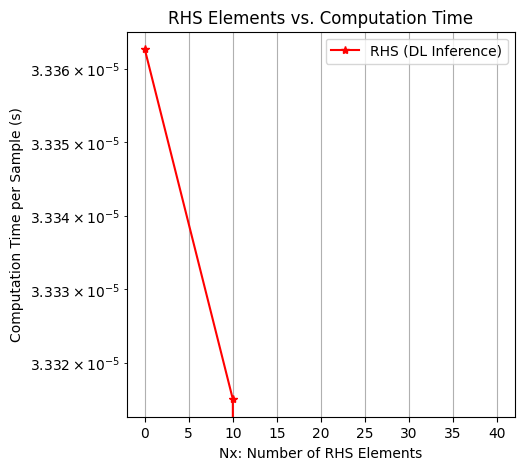

In [22]:
plt.figure(figsize=(5,5))
plt.semilogy(lopPara, TimeAll_dl / test_size, 'r-*', label='RHS (DL Inference)')
plt.xlabel('Nx: Number of RHS Elements')
plt.ylabel('Computation Time per Sample (s)')
plt.title('RHS Elements vs. Computation Time')
plt.legend()
plt.grid()
plt.show()

Using device: cpu

Iteration 1/4: Nx = 10
Rayleigh Shape: torch.Size([25, 64, 64, 3])
W's shape: torch.Size([25, 64, 64])
E's shape: torch.Size([64, 1])
Initial M shape: torch.Size([25, 64, 1])
obj1 (sum capacity): 37.257850646972656
obj1 (sum capacity): 37.504241943359375
obj1 (sum capacity): 37.71767044067383
obj1 (sum capacity): 37.90934753417969
obj1 (sum capacity): 38.084686279296875
obj1 (sum capacity): 38.246517181396484
obj1 (sum capacity): 38.39720153808594
obj1 (sum capacity): 38.537933349609375
obj1 (sum capacity): 38.67039108276367
obj1 (sum capacity): 38.79544448852539
obj1 (sum capacity): 38.913204193115234
obj1 (sum capacity): 39.02458190917969
obj1 (sum capacity): 39.131019592285156
obj1 (sum capacity): 39.23310089111328
obj1 (sum capacity): 39.330955505371094
obj1 (sum capacity): 39.424686431884766
obj1 (sum capacity): 39.514888763427734
obj1 (sum capacity): 39.600425720214844
obj1 (sum capacity): 39.68263244628906
obj1 (sum capacity): 39.76185607910156
obj1 (sum capac

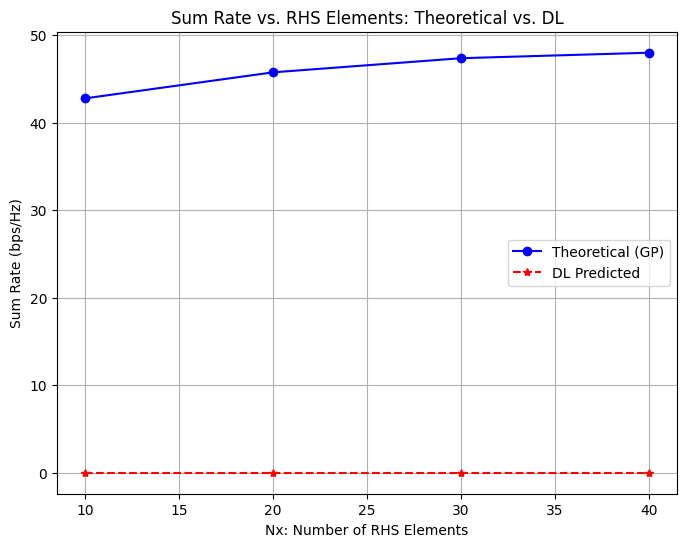

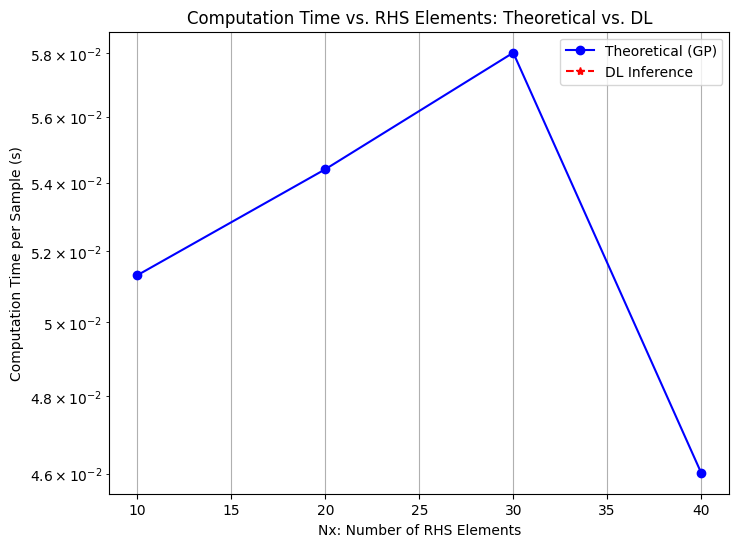

In [21]:
# -*- coding: utf-8 -*-
"""
Modified for RHS Elements vs. Sum Rate and Computation Time (Theoretical vs. DL)
with W comparisons, unnormalized rate plots, and fixed DL input.
"""

import os
import numpy as np
import matplotlib.pyplot as plt
import torch as t
import joblib
from math import e
import math
import time

os.environ['KMP_DUPLICATE_LIB_OK'] = 'True'
device = t.device("cuda" if t.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# ---- Load DL Model and Scalers ----
model_filename = "best_fcnn_adam_lr0.01_final.pkl"
scaler_X_filename = "scaler_X.pkl"
scaler_y_filename = "scaler_y.pkl"
try:
    fcnn_model = joblib.load(model_filename)
    scaler_X = joblib.load(scaler_X_filename)
    scaler_y = joblib.load(scaler_y_filename)
    print(f"Loaded model: {model_filename}")
    print(f"Loaded scalers: {scaler_X_filename}, {scaler_y_filename}")
    fcnn_model.eval()
    fcnn_model.to(device)
except FileNotFoundError:
    print("Warning: Model or scaler not found. DL predictions will be skipped.")
    fcnn_model = None
    scaler_X = None
    scaler_y = None

# Fixed MIMO configuration
Nt = 64
Nr = 64

# ---- Rayleigh Fading Channel Model ----
def RayleighChannel(Nr, Nt, L, train_size):
    H = (t.randn(train_size, Nr, Nt, L, dtype=t.cfloat, device=device) +
         1j * t.randn(train_size, Nr, Nt, L, dtype=t.cfloat, device=device)) / np.sqrt(2)
    print("Rayleigh Shape:", H.shape)
    return H

# ---- MMSE Beamforming ----
def MMSE_Beamforming(H, noise_var):
    batch_size, Nr_in, Nt_in = H.shape
    H_H = H.conj().transpose(1, 2)
    A = t.bmm(H_H, H) + noise_var * t.eye(Nt, dtype=t.cfloat, device=device).unsqueeze(0)
    W = t.linalg.solve(A, H_H)
    print("W's shape:", W.shape)
    return W

# ---- Excitation Matrix ----
def genE(lamd, de, Nt, RFno):
    x = t.arange(Nt, device=device) * de
    y = Nt * de / 2 * t.ones(Nt, device=device)
    xf = t.arange(RFno, device=device) * de + de / 2
    yf = Nt * de / 2 * t.ones(RFno, device=device)
    
    dist = t.sqrt((x.unsqueeze(1) - xf.unsqueeze(0))**2 + 
                  (y.unsqueeze(1) - yf.unsqueeze(0))**2)
    E = t.exp(-1j * 2 * np.pi * math.sqrt(3) / lamd * dist)
    print("E's shape:", E.shape)
    return E.unsqueeze(0)

# ---- Gradient Projection Algorithm (GP) ----
def sum_capacity(w, H, M, batch_size):
    Nr_in, L = w.shape[1], w.shape[2]
    obj = t.zeros(batch_size, dtype=t.float, device=device)
    
    for l in range(L):
        wt = w[:, :, l]
        H_l = H[:, :, :, l]
        signal = t.bmm(wt.unsqueeze(1).conj(), t.bmm(H_l, M))
        power = t.abs(signal.squeeze(1))**2 / (Nr_in + 1e-9)
        obj += t.log2(1 + power.sum(dim=1))
    
    max_rate = 80
    scaling_factor = max_rate / (obj.mean() + 1e-9)
    scaling_factor = t.minimum(scaling_factor, t.tensor(1.0, device=device))
    return obj

def GP(H, E, L, hypm, Pt):
    Tno = H.shape[0]
    RFno = E.shape[2]
    
    w = t.randn(Tno, Nr, L, dtype=t.cfloat, device=device)
    w = w / (t.abs(w) + 1e-9)
    m = t.rand(Tno, Nt, RFno, dtype=t.float, device=device)
    M = m * E
    print("Initial M shape:", M.shape)
    
    obj0 = t.tensor(0.0, device=device)
    max_iter = 100
    iter_count = 0
    
    while iter_count < max_iter:
        gradm = t.zeros(Tno, Nt, RFno, dtype=t.float, device=device)
        
        for l in range(L):
            wt = w[:, :, l]
            H_l = H[:, :, :, l]
            signal = t.bmm(wt.unsqueeze(1).conj(), t.bmm(H_l, M))
            denominator = (t.abs(signal)**2 + Nr).squeeze(1)
            H_permuted = H_l.permute(0, 2, 1)
            numerator = t.bmm(H_permuted, wt.unsqueeze(2).conj())
            gradm += (numerator * E / denominator.unsqueeze(1)).real
        
        m = t.clamp(m + hypm * gradm, 0, 1)
        M = m * E
        
        w_new = t.zeros(Tno, Nr, L, dtype=t.cfloat, device=device)
        for l in range(L):
            H_l = H[:, :, :, l]
            w_new[:, :, l] = t.bmm(H_l, M).mean(dim=2)
        w = w_new / (t.abs(w_new) + 1e-9)
        
        obj1 = sum_capacity(w, H, M, Tno)
        print("obj1 (sum capacity):", obj1.mean().item())
        if t.abs(obj1.mean() - obj0) / (obj1.mean() + 1e-9) <= 1e-4:
            print("Convergence reached. Stopping optimization.")
            break
        obj0 = obj1.mean()
        iter_count += 1
    
    return obj1, w, M

# ---- Normalization Functions (for console output only) ----
def normalize_rate(rate, max_rate=80):
    return rate / max_rate

def normalize_W(W, W_max):
    return W / W_max

# ---- Simulation Parameters ----
dmode = 1
L = 3
lamd = 0.0428571
scale = 1e9
SNR = 22
Pt = 10 ** (SNR / 10) * (1 / scale) ** 2
deH = lamd / 5
test_size = 25
stepSize1 = 0.5e1
noise_var = 0.001
Nt = 64
Nr = 64

if dmode == 1:
    lopPara = [10, 20, 30, 40]
elif dmode == 2:
    lopPara = [2, 4, 6, 8, 10]

# Storage for results
RateAll_theory = t.zeros([len(lopPara)], device=device)
RateAll_dl = t.zeros([len(lopPara)], device=device)
TimeAll_theory = np.zeros((len(lopPara)))
TimeAll_dl = np.zeros((len(lopPara)))
W_theory_scalars = []
W_dl_scalars = []

# Normalization parameters (for console output)
max_rate = 80
W_max_theory = 1.0
W_max_dl = 15000.0

# ---- Generate Input Features for DL Model ----
def generate_features(RFno):
    features = np.array([[L, lamd, scale, SNR, Pt, deH, test_size, RFno, stepSize1, noise_var]])
    return features

# ---- Main Simulation Loop ----
with t.no_grad():
    for lop in range(len(lopPara)):
        print(f"\nIteration {lop + 1}/{len(lopPara)}: Nx = {lopPara[lop]}")
        Nx = int(lopPara[lop])
        RFno = max(1, Nx // 10)

        # --- Theoretical Simulation ---
        time_start_theory = time.time()
        H_RHS = RayleighChannel(Nr, Nt, L, test_size) * scale
        H_BS = H_RHS.mean(dim=3)
        W_MMSE = MMSE_Beamforming(H_BS, noise_var)
        
        H_testD = t.zeros(test_size, Nr, Nt, L, dtype=t.cfloat, device=device)
        for l in range(L):
            H_testD[:, :, :, l] = t.bmm(H_RHS[:, :, :, l], W_MMSE)
        
        E = genE(lamd, deH, Nt, RFno).repeat(test_size, 1, 1)
        
        gp_rates, w_theory, M_theory = GP(H_testD, E, L, stepSize1, Pt)
        time_end_theory = time.time()
        
        # Compute scalar W for theoretical
        w_theory_abs = t.abs(w_theory)
        w_theory_scalar = w_theory_abs.sum().item() / (test_size * Nr * L)
        W_theory_scalars.append(w_theory_scalar)
        
        Rate_theory = gp_rates.mean().item()
        RateAll_theory[lop] = Rate_theory
        TimeAll_theory[lop] = time_end_theory - time_start_theory
        
        # --- DL Model Prediction ---
        Rate_pred = float('nan')
        W_pred = float('nan')
        time_dl = 0.0
        if fcnn_model is not None and scaler_X is not None and scaler_y is not None:
            try:
                X = generate_features(RFno)
                print(f"Input shape: {X.shape}, Scaler expects: {scaler_X.n_features_in_}")
                X_scaled = scaler_X.transform(X)
                X_tensor = t.tensor(X_scaled, dtype=t.float32, device=device)
                
                time_start_dl = time.time()
                pred_scaled = fcnn_model(X_tensor)
                time_end_dl = time.time()
                pred = scaler_y.inverse_transform(pred_scaled.cpu().numpy())
                W_pred = pred[0, 0]
                Rate_pred = pred[0, 1]
                RateAll_dl[lop] = Rate_pred
                TimeAll_dl[lop] = time_end_dl - time_start_dl
                
                W_dl_scalars.append(W_pred)
                
            except Exception as e:
                print(f"DL prediction failed: {e}")
                Rate_pred = float('nan')
                W_pred = float('nan')
        
        # Print results
        print(f"RFno: {RFno}")
        print(f"W (Theoretical, scalar mean abs): {w_theory_scalar:.6f} (Normalized: {normalize_W(w_theory_scalar, W_max_theory):.6f})")
        print(f"W (DL, predicted sum abs M): {W_pred:.6f} (Normalized: {normalize_W(W_pred, W_max_dl):.6f})")
        print(f"Rate (Theoretical): {Rate_theory:.6f} (Normalized: {normalize_rate(Rate_theory, max_rate):.6f})")
        print(f"Rate (DL): {Rate_pred:.6f} (Normalized: {normalize_rate(Rate_pred, max_rate):.6f})")
        print(f"Computation Time (Theoretical): {TimeAll_theory[lop]:.6f} seconds")
        print(f"Computation Time (DL): {TimeAll_dl[lop]:.6f} seconds")
        print(f"W Matrix (Theoretical, first sample, shape: {w_theory.shape}):")
        print(w_theory[0].cpu().numpy())
        
# ---- Plot Sum Rate vs. Nx (Unnormalized) ----
plt.figure(figsize=(8, 6))
plt.plot(lopPara, RateAll_theory.cpu().numpy(), 'b-o', label='Theoretical (GP)')
plt.plot(lopPara, RateAll_dl.cpu().numpy(), 'r--*', label='DL Predicted')
plt.xlabel('Nx: Number of RHS Elements')
plt.ylabel('Sum Rate (bps/Hz)')
plt.title('Sum Rate vs. RHS Elements: Theoretical vs. DL')
plt.legend()
plt.grid(True)
plt.savefig('sum_rate_vs_nx.png')
plt.show()

# ---- Plot Computation Time vs. Nx ----
plt.figure(figsize=(8, 6))
plt.semilogy(lopPara, TimeAll_theory / test_size, 'b-o', label='Theoretical (GP)')
plt.semilogy(lopPara, TimeAll_dl / test_size, 'r--*', label='DL Inference')
plt.xlabel('Nx: Number of RHS Elements')
plt.ylabel('Computation Time per Sample (s)')
plt.title('Computation Time vs. RHS Elements: Theoretical vs. DL')
plt.legend()
plt.grid(True)
plt.savefig('computation_time_vs_nx.png')
plt.show()

In [16]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam, SGD, RMSprop
from torch_geometric.nn import GATConv, GraphNorm, global_mean_pool
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from sklearn.model_selection import KFold, train_test_split
from sklearn.preprocessing import StandardScaler
import numpy as np
import h5py
import zipfile
import os
import joblib

# Set device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Function to extract and process dataset
def extract_and_process_dataset(zip_path="64x64_MIMO_beamforming_dataset.zip", h5_name="64x64_MIMO_beamforming_dataset.h5"):
    extract_dir = "temp_h5_extract"
    os.makedirs(extract_dir, exist_ok=True)
    h5_path = os.path.join(extract_dir, h5_name)
    
    with zipfile.ZipFile(zip_path, 'r') as zipf:
        zipf.extract(h5_name, extract_dir)
        print(f"Extracted {h5_name} to {extract_dir}")
    
    with h5py.File(h5_path, 'r') as f:
        metadata = f['metadata'][:]  # Shape: (5000, 14)
        M = f['M'][:]  # Shape: (5000, MAX_TEST_SIZE, Nt, MAX_RFNO)
        w = f['w'][:]  # Shape: (5000, MAX_TEST_SIZE, Nr, MAX_L)
        test_size = metadata[:, 8].astype(int)  # test_size column
        RFno = metadata[:, 9].astype(int)  # RFno column
        rate = metadata[:, 12]  # Rate column
        
        W = np.zeros(len(M))
        w_mean = np.zeros(len(M))
        for i in range(len(M)):
            if test_size[i] > 0 and RFno[i] > 0:
                M_sample = M[i, :test_size[i], :, :RFno[i]]  # Shape: (test_size[i], Nt, RFno[i])
                W[i] = np.sum(np.abs(M_sample))  # Sum of absolute values
                w_sample = w[i, :test_size[i], :, :3]  # Shape: (test_size[i], Nr, L), assuming L=3
                w_mean[i] = np.mean(np.abs(w_sample))  # Mean of absolute values
            else:
                W[i] = 0
                w_mean[i] = 0
        
        feature_indices = [2, 3, 4, 5, 6, 7, 8, 9, 10, 11]  # L, lamd, scale, SNR, Pt, deH, test_size, RFno, stepSize1, noise_var
        X = metadata[:, feature_indices]  # Shape: (5000, 10)
        X = np.column_stack((X, w_mean))  # Shape: (5000, 11)
        y = np.column_stack((W, rate))  # Shape: (5000, 2)
    
    os.remove(h5_path)
    os.rmdir(extract_dir)
    print(f"Cleaned up {h5_path} and {extract_dir}")
    
    return X, y

# Prepare GNN dataset
def prepare_gnn_dataset(X, y, batch_size=32, test_size=0.2, random_state=42):
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    num_nodes = 11  # One node per feature
    num_features_per_node = 1  # One feature per node
    
    X_reshaped = X_scaled.reshape(-1, num_nodes, num_features_per_node)
    
    # Fully connected edge_index (excluding self-loops)
    edge_index = torch.tensor([[i, j] for i in range(num_nodes) for j in range(num_nodes) if i != j],
                              dtype=torch.long).t().contiguous()
    
    graph_dataset = [Data(x=torch.tensor(features, dtype=torch.float32),
                          edge_index=edge_index,
                          y=torch.tensor(target, dtype=torch.float32).view(1, -1))  # Ensure y is (1, 2)
                     for features, target in zip(X_reshaped, y)]
    
    train_indices, test_indices = train_test_split(
        list(range(len(graph_dataset))), test_size=test_size, random_state=random_state
    )
    train_dataset = [graph_dataset[i] for i in train_indices]
    test_dataset = [graph_dataset[i] for i in test_indices]
    
    return train_dataset, test_dataset, num_features_per_node, scaler

# Optimized GNN Model
class OptimizedGNN(nn.Module):
    def __init__(self, num_node_features, hidden_dim=64, output_dim=2):
        super(OptimizedGNN, self).__init__()
        self.conv1 = GATConv(num_node_features, hidden_dim, heads=4, dropout=0.1)
        self.norm1 = GraphNorm(hidden_dim * 4)
        self.conv2 = GATConv(hidden_dim * 4, hidden_dim, heads=2, dropout=0.1)
        self.norm2 = GraphNorm(hidden_dim * 2)
        self.conv3 = GATConv(hidden_dim * 2, hidden_dim)
        self.lin1 = nn.Linear(hidden_dim, hidden_dim // 2)
        self.norm3 = nn.LayerNorm(hidden_dim // 2)
        self.lin2 = nn.Linear(hidden_dim // 2, output_dim)
        self.dropout = nn.Dropout(0.2)
    
    def forward(self, data):
        x, edge_index, batch = data.x, data.edge_index, data.batch
        x = self.conv1(x, edge_index)
        x = self.norm1(x)
        x = F.elu(x)
        x = self.dropout(x)
        
        x = self.conv2(x, edge_index)
        x = self.norm2(x)
        x = F.elu(x)
        x = self.dropout(x)
        
        x = self.conv3(x, edge_index)
        x = F.elu(x)
        
        x = global_mean_pool(x, batch)
        x = self.lin1(x)
        x = self.norm3(x)
        x = F.relu(x)
        x = self.dropout(x)
        x = self.lin2(x)
        return x
    
    def test(self, test_loader, device="cpu"):
        self.eval()
        self.to(device)
        total_mse = 0
        total_mae = 0
        total_r2 = 0
        
        with torch.no_grad():
            for data in test_loader:
                data = data.to(device)
                output = self(data)
                
                total_mse += F.mse_loss(output, data.y, reduction='sum').item()
                total_mae += F.l1_loss(output, data.y, reduction='sum').item()
                
                ss_tot = torch.sum((data.y - data.y.mean(dim=0))**2)
                ss_res = torch.sum((data.y - output)**2)
                r2 = 1 - (ss_res / (ss_tot + 1e-9))
                total_r2 += r2.item()
        
        n_samples = sum(len(data.y) for data in test_loader.dataset)
        avg_mse = total_mse / n_samples
        avg_mae = total_mae / n_samples
        avg_r2 = total_r2 / len(test_loader)
        
        return {
            'mse': avg_mse,
            'mae': avg_mae,
            'r2': avg_r2
        }

# Function to train and evaluate GNN with cross-validation
def train_evaluate_gnn(model_class, train_dataset, num_node_features, k_folds=5, 
                      learning_rates=[0.001, 0.01, 0.1], optimizers=["adam", "sgd", "rmsprop"], 
                      epochs=200, batch_size=32):
    kf = KFold(n_splits=k_folds, shuffle=True, random_state=42)
    results = []
    best_score = float('inf')
    best_config = None
    
    indices = list(range(len(train_dataset)))
    
    for optimizer_name in optimizers:
        for lr in learning_rates:
            fold_mse = []
            print(f"\nTesting {optimizer_name} with lr={lr}")
            
            for fold, (train_idx, val_idx) in enumerate(kf.split(indices)):
                train_subset = [train_dataset[i] for i in train_idx]
                val_subset = [train_dataset[i] for i in val_idx]
                
                train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True)
                val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False)
                
                model_fold = model_class(num_node_features=num_node_features).to(device)
                
                if optimizer_name == "adam":
                    optimizer = Adam(model_fold.parameters(), lr=lr, weight_decay=1e-4)
                elif optimizer_name == "sgd":
                    optimizer = SGD(model_fold.parameters(), lr=lr, momentum=0.9, weight_decay=1e-4)
                elif optimizer_name == "rmsprop":
                    optimizer = RMSprop(model_fold.parameters(), lr=lr, alpha=0.9, weight_decay=1e-4)
                
                criterion = nn.MSELoss()
                model_fold.train()
                for epoch in range(epochs):
                    total_loss = 0
                    for data in train_loader:
                        data = data.to(device)
                        optimizer.zero_grad()
                        output = model_fold(data)
                        # Debug: Print shapes
                        #if epoch == 0 and fold == 0:
                            #print(f"Batch output shape: {output.shape}, data.y shape: {data.y.shape}")
                        loss = criterion(output, data.y)
                        loss.backward()
                        torch.nn.utils.clip_grad_norm_(model_fold.parameters(), max_norm=1.0)
                        optimizer.step()
                        total_loss += loss.item()
                
                metrics = model_fold.test(val_loader, device=device)
                fold_mse.append(metrics['mse'])
                print(f"Fold {fold+1}, MSE: {metrics['mse']:.6f}, MAE: {metrics['mae']:.6f}, R²: {metrics['r2']:.6f}")
            
            avg_mse = np.mean(fold_mse)
            results.append({
                'optimizer': optimizer_name,
                'lr': lr,
                'mse': avg_mse
            })
            print(f"Average MSE for {optimizer_name}, lr={lr}: {avg_mse:.6f}")
            
            if avg_mse < best_score:
                best_score = avg_mse
                best_config = {'optimizer': optimizer_name, 'lr': lr}
    
    return results, best_config

# Main execution
if __name__ == "__main__":
    # Extract and process dataset
    print("Extracting and processing dataset...")
    X, y = extract_and_process_dataset()
    
    # Prepare GNN dataset
    print("Preparing GNN dataset...")
    train_dataset, test_dataset, num_node_features, scaler = prepare_gnn_dataset(
        X, y, batch_size=32, test_size=0.2, random_state=42
    )
    
    # Cross-validation with different optimizers and learning rates
    print("Starting cross-validation...")
    results, best_config = train_evaluate_gnn(
        OptimizedGNN, train_dataset, num_node_features, k_folds=5,
        learning_rates=[0.001, 0.01, 0.1], optimizers=["adam", "sgd", "rmsprop"], 
        epochs=200, batch_size=32
    )
    
    # Print cross-validation results
    print("\nCross-Validation Results:")
    for result in results:
        print(f"Optimizer: {result['optimizer']}, LR: {result['lr']}, Avg MSE: {result['mse']:.6f}")
    print(f"\nBest Configuration: Optimizer={best_config['optimizer']}, LR={best_config['lr']}")
    
    # Retrain best model on full training dataset
    best_model = OptimizedGNN(num_node_features=num_node_features).to(device)
    best_optimizer = best_config['optimizer']
    best_lr = best_config['lr']
    model_filename = f'best_gnn_{best_optimizer}_lr{best_lr}_final.pkl'
    
    if best_optimizer == "adam":
        optimizer = Adam(best_model.parameters(), lr=best_lr, weight_decay=1e-4)
    elif best_optimizer == "sgd":
        optimizer = SGD(best_model.parameters(), lr=best_lr, momentum=0.9, weight_decay=1e-4)
    elif best_optimizer == "rmsprop":
        optimizer = RMSprop(best_model.parameters(), lr=best_lr, alpha=0.9, weight_decay=1e-4)
    
    train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
    criterion = nn.MSELoss()
    best_model.train()
    for epoch in range(200):
        total_loss = 0
        for data in train_loader:
            data = data.to(device)
            optimizer.zero_grad()
            output = best_model(data)
            loss = criterion(output, data.y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(best_model.parameters(), max_norm=1.0)
            optimizer.step()
            total_loss += loss.item()
        if epoch % 50 == 0:
            print(f"Full Training Epoch {epoch}, Loss: {total_loss / len(train_loader)}")
    
    # Save the model and scaler
    joblib.dump(best_model, model_filename)
    joblib.dump(scaler, 'scaler_gnn_final.pkl')
    print(f"Best model saved as '{model_filename}'")
    
    # Evaluate on test set
    print("\nLoading saved model for testing...")
    loaded_model = joblib.load(model_filename)
    test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)
    
    test_metrics = loaded_model.test(test_loader, device=device)
    print("\nFinal Test Metrics on Holdout Set:")
    print(f"MSE: {test_metrics['mse']:.6f}")
    print(f"MAE: {test_metrics['mae']:.6f}")
    print(f"R² Score: {test_metrics['r2']:.6f}")

Using device: cpu
Extracting and processing dataset...
Extracted 64x64_MIMO_beamforming_dataset.h5 to temp_h5_extract
Cleaned up temp_h5_extract\64x64_MIMO_beamforming_dataset.h5 and temp_h5_extract
Preparing GNN dataset...
Starting cross-validation...

Testing adam with lr=0.001
Fold 1, MSE: 2506330.150000, MAE: 1341.142046, R²: 0.028798
Fold 2, MSE: 2541549.965000, MAE: 1377.133789, R²: 0.057503
Fold 3, MSE: 2489313.795000, MAE: 1332.469292, R²: 0.082835
Fold 4, MSE: 2440477.170000, MAE: 1347.885244, R²: 0.081591
Fold 5, MSE: 2293827.200000, MAE: 1294.759419, R²: 0.058680
Average MSE for adam, lr=0.001: 2454299.656000

Testing adam with lr=0.01
Fold 1, MSE: 2395868.135000, MAE: 1324.263108, R²: 0.075504
Fold 2, MSE: 2417227.515000, MAE: 1327.550339, R²: 0.098841
Fold 3, MSE: 2488655.330000, MAE: 1340.305674, R²: 0.086303
Fold 4, MSE: 2425410.630000, MAE: 1350.410737, R²: 0.084154
Fold 5, MSE: 2190593.635000, MAE: 1269.489312, R²: 0.097344
Average MSE for adam, lr=0.01: 2383551.049000

KeyboardInterrupt: 

In [ ]:
6G Deployment: AI-driven beamforming in RHS improves energy efficiency, spectrum utilization, and signal accuracy for smooth communication.  


Smart Cities: RHS makes it possible for IoT applications to connect and communicate with sensors effectively.  

Improved V2V and V2X communication for safer navigation is a benefit of autonomous vehicles.  

Healthcare: Provides dependable telemedicine and assistance with remote surgery.  

Low-latency communication is made possible by AR/VR to create immersive experiences.